In [1]:
# createObspack 
#
# v5.0  10 Oct 2024
#
# source code license: GPL V3 (c)ICOS ERIC
#
# Alex Vermeulen, ICOS ERIC - Carbon Portal (alex.vermeulen@icos-ri.eu)
#
# Program to loop through available ICOS atmosphere data (L1, NRT, historical) and produce per station,sampleheight 
# an Obspack compatible netcdf file
#
# Builds on the icoscp library for retrieving the station and datafile metadata
#
# Assumptions:
# - Station has a Level 2 data file available (for extra data colums on uncertainty), so at the moment only works 
#   for labelled stations
# 10 Oct 2024 added support for NRT 1.5 Fasttrack products

In [2]:
# import statements
import pandas as pd
import numpy as np
import datetime as dt
import time
from icoscp.station import station
from icoscp.dobj import Dobj
from prompt_toolkit import print_formatted_text, HTML
import ccgfilt
import matplotlib.pyplot as plt
import requests
import urllib.request
import zipfile
import re
import io
import warnings
warnings.filterwarnings('ignore')

display(HTML("<style>.container { width:100% !important',' }</style>"))
%matplotlib inline
#%matplotlib ipympl

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


HTML("<style>.container { width:100% !important',' }</style>")

In [3]:
# initialisation routine to set up global structures and initialise data
def init():
    global gas
    global doi
    global atc_drought_header
    global atc_header
    global colnames
    global nrcols
    global skip
    global obspack_set
    global dfRoles
    global dfiles
    global produced
    global fileContribs
    global collectionContribs
    global cntAll
    global ML
    global MaunaLoa
    global GlobAverCH4
    global labNumbers
    global ICOSstations
    global useflags
    atc_drought_header = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','co2','Stdev','NbPoints','Flag','InstrumentId','QualityId','InternalFlag','AutoDescriptiveFlag','ManualDescriptiveFlag','DataOrigin']
    atc_atmprod_header = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','co2','Stdev','NbPoints','Flag','InstrumentId','QualityId','LTR','CMR','STTB','QcBias','QcBiasUncertainty','Origin','OriginalFlag']
    atc_l2_header      = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','co2','Stdev','NbPoints','Flag','InstrumentId','QualityId','LTR','CMR','STTB','QcBias','QcBiasUncertainty']
    atc_nrt_header     = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','co2','Stdev','NbPoints','Flag','InstrumentId','QualityId','InternalFlag','AutoDescriptiveFlag','ManualDescriptiveFlag']
    atc_l2_header_ch4  = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','ch4','Stdev','NbPoints','Flag','InstrumentId','QualityId','LTR','CMR','STTB','QcBias','QcBiasUncertainty']
    atc_l2_header_co   = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','co','Stdev','NbPoints','Flag','InstrumentId','QualityId','LTR','CMR','STTB','QcBias','QcBiasUncertainty']
    atc_l2_header_n2o  = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','n2o','Stdev','NbPoints','Flag','InstrumentId','QualityId','LTR','CMR','STTB','QcBias','QcBiasUncertainty']
    atc_fast_header    = ['Site','SamplingHeight','Year','Month','Day','Hour','Minute','DecimalDate','co2','Stdev','NbPoints','Flag','InstrumentId','QualityId','LTR','CMR','STTB','QcBias','QcBiasUncertainty']
    
    colnames = [atc_atmprod_header,atc_nrt_header,atc_fast_header,atc_l2_header]
              
    nrcols = [22,18,20,20]
    skip = [45,39,45,45]
    doi = 'XKKA-AWRS'
    gas = 'n2o'
    obspack_set = {'doi_collection' : 'https://doi.org/10.18160/'+doi,
                   'icos_class' : [1,2],
                   'non-icos' : True,
                   'version' : '11.1',
                   'contributors' : [],
                   'contrib_ORCID' : [],
                   'other' : 'NA',
                  }
    cntAll = 0
    useflags = True
    fileContribs=pd.DataFrame()
    collectionContribs=pd.DataFrame()
    MaunaLoa,ML = Get_MaunaLoa(analyse=plotit)
    GlobAverCH4 =  GlobAverageCH4()
    labNumbers = pd.read_csv('./labnumbers.csv',comment='#',delimiter=';')           
    ICOSstations = pd.read_csv('./ICOSstations.csv',comment='#',delimiter=';') 

In [4]:
# execute sparql query to get dataframe with roles and names of contributors at all stations
def getroles():
    url = 'https://meta.icos-cp.eu/sparql'    
    query = '''
        prefix cpmeta: <http://meta.icos-cp.eu/ontologies/cpmeta/>
        prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#>
        select ?stId ?stationName ?fname ?lname ?roleName ?weight ?start ?end
        from <http://meta.icos-cp.eu/resources/icos/>
        from <http://meta.icos-cp.eu/resources/cpmeta/>
        where{
            ?pers cpmeta:hasMembership ?memb .
            ?memb cpmeta:hasRole/rdfs:label ?roleName .
            ?memb cpmeta:atOrganization ?station .
            ?station cpmeta:hasStationId ?stId ; cpmeta:hasName ?stationName .
            ?pers cpmeta:hasFirstName ?fname; cpmeta:hasLastName ?lname .
            OPTIONAL{?memb cpmeta:hasStartTime ?start}
            OPTIONAL{?memb cpmeta:hasEndTime ?end}
            OPTIONAL{?memb cpmeta:hasAttributionWeight ?weight}
        }
        order by ?stId desc(?weight) desc(?end) ?start ?roleName ?lname
        '''
    r = requests.get(url, params = {'format': 'json', 'query': query})
    data = r.json()

    #Convert the the result into a table
    # output is an array, where each row contains 
    # information about the roles:
    data_ls = [[data['results']['bindings'][row].get(col, {}).get('value')
              for col in data['head']['vars']]
              for row in range(len(data['results']['bindings']))]

    #Create a pandas dataframe from the list:
    df = pd.DataFrame(data_ls, columns=data['head']['vars'])

    #Return dataframe:
    return df   

In [5]:
# execute sparql query to retrieve atmospheric datafiles that we need to explore
def getfilelist(specs=['atcCo2Product','atcCo2L2DataObject','atcCo2NrtGrowingDataObject']):
    specstr=''
    for spec in specs:
        specstr=specstr+'<http://meta.icos-cp.eu/resources/cpmeta/'+spec+'> '
    url = 'https://meta.icos-cp.eu/sparql'    
    query = '''
        prefix cpmeta: <http://meta.icos-cp.eu/ontologies/cpmeta/>
        prefix prov: <http://www.w3.org/ns/prov#>
        prefix xsd: <http://www.w3.org/2001/XMLSchema#>
        select ?dobj ?hasNextVersion ?spec ?fileName ?size ?submTime ?timeStart ?timeEnd
        where {
            VALUES ?spec {'''+specstr+'''}
            ?dobj cpmeta:hasObjectSpec ?spec .
            BIND(EXISTS{[] cpmeta:isNextVersionOf ?dobj} AS ?hasNextVersion)
            ?dobj cpmeta:hasSizeInBytes ?size .
        ?dobj cpmeta:hasName ?fileName .
        ?dobj cpmeta:wasSubmittedBy/prov:endedAtTime ?submTime .
        ?dobj cpmeta:hasStartTime | (cpmeta:wasAcquiredBy / prov:startedAtTime) ?timeStart .
        ?dobj cpmeta:hasEndTime | (cpmeta:wasAcquiredBy / prov:endedAtTime) ?timeEnd .
            FILTER NOT EXISTS {[] cpmeta:isNextVersionOf ?dobj}
        FILTER( ?submTime >= '2023-05-31T22:00:00.000Z'^^xsd:dateTime ) 
        }
        order by desc(?submTime)   
        '''
    r = requests.get(url, params = {'format': 'json', 'query': query})
    data = r.json()

    #Convert the the result into a table
    # output is an array, where each row contains 
    # information about the roles:
    data_ls = [[data['results']['bindings'][row].get(col, {}).get('value')
              for col in data['head']['vars']]
              for row in range(len(data['results']['bindings']))]

    #Create a pandas dataframe from the list:
    df = pd.DataFrame(data_ls, columns=data['head']['vars'])

    #Return dataframe:
    return df   

In [6]:
# execute sparql query to retrieve information on a data object
def getfileinfo(id):
    url = 'https://meta.icos-cp.eu/sparql'    
    query = '''   
        prefix cpmeta: <http://meta.icos-cp.eu/ontologies/cpmeta/>
        prefix prov: <http://www.w3.org/ns/prov#>
        prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#>
        prefix xsd: <http://www.w3.org/2001/XMLSchema#>
        prefix dcterms: <http://purl.org/dc/terms/>
        select distinct ?dobj ?station ?stationId ?samplingHeight ?samplingPoint ?theme ?themeIcon ?title ?description ?columnNames ?site ?hasVarInfo ?dois ?biblioInfo where{
            {
                select ?dobj (min(?station0) as ?station) (sample(?stationId0) as ?stationId) (sample(?samplingHeight0) as ?samplingHeight) (sample(?samplingPoint0) as ?samplingPoint) (sample(?site0) as ?site) (group_concat(?doi ; separator="|") as ?dois) where{
                    VALUES ?dobj { <'''+id+'''> }
                    OPTIONAL{
                        ?dobj cpmeta:wasAcquiredBy ?acq.
                        ?acq prov:wasAssociatedWith ?stationUri .
                        OPTIONAL{ ?stationUri cpmeta:hasName ?station0 }
                        OPTIONAL{ ?stationUri cpmeta:hasStationId ?stationId0 }
                        OPTIONAL{ ?acq cpmeta:hasSamplingHeight ?samplingHeight0 }
                        OPTIONAL{ ?acq cpmeta:hasSamplingPoint/rdfs:label ?samplingPoint0 }
                        OPTIONAL{ ?acq cpmeta:wasPerformedAt/cpmeta:hasSpatialCoverage/rdfs:label ?site0 }
                    }
                    OPTIONAL{
                        ?coll dcterms:hasPart ?dobj ; cpmeta:hasDoi ?doi .
                        filter not exists{[] cpmeta:isNextVersionOf ?coll ; dcterms:hasPart ?dobj}
                    }
                }
                group by ?dobj
            }
            OPTIONAL{
                ?dobj cpmeta:hasObjectSpec/cpmeta:hasDataTheme ?themeUri .
                ?themeUri rdfs:label ?theme ; cpmeta:hasIcon ?themeIcon .
            }
            OPTIONAL{ ?dobj dcterms:title ?title }
            OPTIONAL{ ?dobj dcterms:description ?description }
            OPTIONAL{ ?dobj cpmeta:hasActualColumnNames ?columnNames }
            OPTIONAL{ ?dobj cpmeta:hasActualVariable [].BIND ("true"^^xsd:boolean as ?hasVarInfo) }
            OPTIONAL{ ?dobj cpmeta:hasBiblioInfo ?biblioInfo}
        }
        '''
    r = requests.get(url, params = {'format': 'json', 'query': query})
    data = r.json()

    #Convert the the result into a table
    # output is an array, where each row contains 
    # information about the roles:
    data_ls = [[data['results']['bindings'][row].get(col, {}).get('value')
              for col in data['head']['vars']]
              for row in range(len(data['results']['bindings']))]

    #Create a pandas dataframe from the list:
    df = pd.DataFrame(data_ls, columns=data['head']['vars'])

    #Return dataframe:
    return df       

In [7]:
def toYearFraction(date):

    def sinceEpoch(date): # returns seconds since epoch
        return time.mktime(date.timetuple())
    s = sinceEpoch

    year = date.year
    startOfThisYear = dt.datetime(year=year, month=1, day=1)
    startOfNextYear = dt.datetime(year=year+1, month=1, day=1)

    yearElapsed = s(date) - s(startOfThisYear)
    yearDuration = s(startOfNextYear) - s(startOfThisYear)
    fraction = yearElapsed/yearDuration

    return date.year + fraction

In [8]:
def t2dt(atime):
    year = int(atime)
    remainder = atime - year
    boy = dt.datetime(year, 1, 1)
    eoy = dt.datetime(year + 1, 1, 1)
    seconds = remainder * (eoy - boy).total_seconds()
    return boy + dt.timedelta(seconds=seconds)

In [9]:
def doiCitation(doi,citationstyle='elsevier-harvard'):    

    import json, requests
    from requests.structures import CaseInsensitiveDict

    headers = CaseInsensitiveDict()
    headers["Accept"] = "text/x-bibliography; style="+citationstyle
    resp = requests.get("https://doi.org/"+doi, headers=headers)
    if resp.status_code==200:
        info=resp.text
    else:
        info='citation not found'
    return info    

In [10]:
# look up station uri in dataset meta info and harvest contributor info for that station into a dataframe
def getStationRolesFromFilePid(fpid,debug=False):
    import json, requests
    from requests.structures import CaseInsensitiveDict
         
    if 'https://meta.icos-cp.eu/resources/stations/' in fpid:
        stationurl = fpid
    elif len(fpid)<7:
        stationurl='https://meta.icos-cp.eu/resources/stations/'+fpid
    else:
        obj=Dobj(fpid)
        meta=obj.meta
        #citation=meta['references']['citationString']
        stationurl=meta['specificInfo']['acquisition']['station']['org']['self']['uri']

    if debug: print(stationurl)
    df=pd.DataFrame()
    
    headers = CaseInsensitiveDict()
    headers["Accept"] = "application/json"
    resp = requests.get(stationurl, headers=headers)
    info=json.loads(resp.text)
    
    if 'ATMO_' in stationurl:
        #if debug: print(info)
        authors=meta['references']['authors']        
        #if debug: print(authors)
        for author in authors:
            fname=author['firstName']
            lname=author['lastName']
            uri=author['self']['uri']
            orcid=''
            wght=30
            start=None
            end=None      
            df=df.append({'fname':fname,'lname':lname,'orcid':orcid,'uri':uri,'weight':wght,'start':start,'end':end},ignore_index=True)
    else:
        for person in info['staff']:
            fname=person['person']['firstName']
            lname=person['person']['lastName']
            #if debug: print(person)
            uri=person['person']['self']['uri']
            try:
                orcid=person['person']['orcid']
            except:
                orcid=''
            try:
                wght=person['role']['weight']
            except:
                wght=None
            try:
                start=person['role']['start']
            except:
                start=None
            try:
                end=person['role']['end']
            except:
                end=None
            df=df.append({'fname':fname,'lname':lname,'orcid':orcid,'uri':uri,'weight':wght,'start':start,'end':end},ignore_index=True)

    if 'HFD' in stationurl:
        df=df.append({'fname':'Chris',
           'lname':'Rennick',
           'orcid':'0000-0003-4993-0156',
           'uri':'http://meta.icos-cp.eu/resources/people/chris_rennick',
           'weight':100,
           'start':None,
           'end':None}, 
          ignore_index=True)    
    if 'ZOT' in stationurl:
        df=df.append({'fname':'Sönke',
           'lname':'Zähle',
           'orcid':'0000-0001-5602-7956',
           'uri':'http://meta.icos-cp.eu/resources/people/S%C3%B6nke_Zaehle',
           'weight':100,
           'start':None,
           'end':None}, 
          ignore_index=True)    
    
    if debug: print(df)    

    return df,info

In [11]:
def GHG_Filter_TS(time,meas,shortTerm=80,longTerm=667,numPolyterms=3,numHarmonics=4,timeZero=2010,sampleInterval=1/24):
    #
    # Function wrapper to the CCGCRV routine from Thonen et al (1996). Filters a timeseries by smoothing and 
    # removing higher frequency information and fitting a trend and harmonic oscillation. 
    #
    # Specifically designed for greenhouse has observations
    #
    # Parameters
    # Shortterm specifies the interval in days for the low-pass filter and is default 2.6 months (80 days)
    # Longterm specifies the smoothing period which is default set to just under 2 years (667 days)
    # The fit can be defined by the number of polynomial terms (default 3) and the number of harmonics (default 4)
    #
    # Input
    # data: Observational data provided in Panda dataframe data with index datetime as YYYY.fraction and 
    # in first colum the observation series
    #
    # Result
    # A dataframe with index datetime containing in the columns the GrowthRate, Function, Polynome, SmoothCurve, Trend, Cycle, Residual, Detrended 
    # at the interpolated sampleinterval
    #
    # Set the default parameters for the ccg filter and run ccgfilt 
    
    sampleinterval=1/24
    gap=0
    debug=True

    filt = ccgfilt.ccgFilter(time, meas, shortTerm, longTerm, sampleInterval, numPolyterms, numHarmonics, timeZero, gap, debug)

    # get x,y data for plotting
    x0 = filt.xinterp
    y1 = filt.getFunctionValue(x0)
    y2 = filt.getPolyValue(x0)
    y3 = filt.getSmoothValue(x0)
    y4 = filt.getTrendValue(x0)
    y5 = y3-y4
    
    # Seasonal Cycle
    # x and y are original data points
    trend = filt.getTrendValue(time)
    detrend = meas - trend
    harmonics = filt.getHarmonicValue(x0)
    smooth_cycle = harmonics + filt.smooth - filt.trend
    # residuals from the function
    resid_from_func = filt.resid
    # smoothed residuals
    resid_smooth = filt.smooth
    # trend of residuals
    resid_trend = filt.trend
    # residuals about the smoothed line
    resid_from_smooth = filt.yp - filt.getSmoothValue(meas.index)
    deriv = filt.deriv
    
    res=pd.DataFrame({'datetime':x0,'GrowthRate':deriv,'Function':y1,'Poly':y2,'SmoothCurve':y3,'Trend':y4,'Cycle':smooth_cycle,
                'Residual':resid_trend,'Detrended':y5})
    res.set_index('datetime', inplace=True)    
    return res

In [12]:
def GlobAverageCH4():
    MaunaLoaCH4=pd.read_csv('https://gml.noaa.gov/webdata/ccgg/trends/ch4/ch4_mm_gl.txt',skiprows=65,header=None,names=['JulDate','Meas'],delimiter=r"\s+",usecols=[2,3])
    MaunaLoaCH4=MaunaLoaCH4.query("Meas>20")
    MaunaLoaCH4['DateTime'] = [t2dt(i) for i in MaunaLoaCH4.JulDate]
    MaunaLoaCH4.set_index('DateTime', inplace=True)
    return MaunaLoaCH4    

In [13]:
def globAverage(gas='ch4'): # or n2o or co2
    skip=48
    if gas=='co2': skip = 40
    url='https://gml.noaa.gov/webdata/ccgg/trends/'+gas+'/'+gas+'_mm_gl.txt'
    globAver=pd.read_csv(url,skiprows=skip,header=None,names=['JulDate','Meas'],delimiter=r"\s+",usecols=[2,3])
    gloAver=globAver.query("Meas>20")
    globAver['DateTime'] = [t2dt(i) for i in globAver.JulDate]
    globAver.set_index('DateTime', inplace=True)
    return globAver        

In [14]:
def Get_MaunaLoa(analyse=False):
    # Get the most recent Mauna Loa CO2 data and plot it
    # CH4: https://gml.noaa.gov/webdata/ccgg/trends/ch4/ch4_mm_gl.txt monthly marine BL global average
    # N2O: https://gml.noaa.gov/webdata/ccgg/trends/n2o/n2o_mm_gl.txt monthly marine BL global average
    
    MaunaLoa=pd.read_csv("https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_weekly_mlo.txt",skiprows=37,header=None,names=['JulDate','Meas'],delimiter=r"\s+",usecols=[3,4])
    MaunaLoa=MaunaLoa.query("Meas>20")

    MaunaLoa['DateTime'] = [t2dt(i) for i in MaunaLoa.JulDate]
    MaunaLoa.set_index('DateTime', inplace=True)
    if analyse:
        ML = GHG_Filter_TS(MaunaLoa.JulDate,MaunaLoa.Meas)
    else:
        ML = pd.DataFrame()
    return MaunaLoa,ML

In [15]:
def Get_ICOS_ATM_product(dobj,level,debug=False):
    
    from os.path import exists
    
    # get the ICOS ATM data by directly accessing the data objects from CP, 
    # this will trigger the download count for each object, unless we are on the black list
    def count(s,ch):
        # function to count occurances of a character in a string
        cnt=0
        for i in s:
            if i == ch:
                cnt += 1
        return cnt
    
    def readfile(f):
        # Read the ICOS data object by using the io-stream handle and parse as csv 
        # using the predefined column definitions and length of header.
        # Reading this column definitions from the io-stream directly needs seek to work and that fails,
        # so this part is commented out
#        for i in range(0,45):
#            header = f.readline()
#            print(header)
#        head=str(header)[3:-3]
#        colnames="['"+head.replace(';',"','")+"']"
#        nrcols=count(colnames,',')+1
#        print(nrcols)
#        print('Columns: ', colnames)
#        f.seek(0)
#        df = pd.read_csv(f,skiprows=skip[level],header=None,names=colnames[level],delimiter=';',usecols=range(0,nrcols[level]-1))       
        if debug:
            print('File name: ',fname)
            print('Level: ',level)
            print('Columns: ',colnames[level]) 
            print('Cols : ',nrcols[level]) 
        df = pd.read_csv(f,comment='#',header=None,names=colnames[level],delimiter=';',usecols=range(0,nrcols[level]-1))           
        return df
    
    # modify the url to allow download by accepting the data license explicitly
    url=dobj.meta['accessUrl'].replace('https://data.icos-cp.eu/objects/','https://data.icos-cp.eu/licence_accept?ids=%5B%22')+'%22%5D'
    print('url:', url)

    # get the data object from CP, unless we have the file in cache already, if not save it there
    fname='./cache/'+dobj.meta['fileName']
    if not exists(fname):
        r = requests.get(url, allow_redirects=True)
        with open(fname, 'wb') as f:
            f.write(r.content)
        print('filled cache with ',fname)
    else:
        print('hit cache for ',fname)
    if '.zip' in fname:
        zf = zipfile.ZipFile(fname, 'r')
        for item in zf.namelist():
            if debug: print("File in zip: "+ item)
        match = [s for s in zf.namelist() if "ICOS_ATC" in s][0]
        df=readfile(zf.open(match))
    else:
      df=readfile(fname)
    
#    # access the url and open an io stream to it, if the file is zipped, unzip the stream, and pass the file to a dataframe
#    r = requests.get(url, allow_redirects=True)
#    if r.headers.get('content-type')=='application/zip':
#        filename = r.content
#        zf = zipfile.ZipFile(io.BytesIO(filename), 'r')
#        for item in zf.namelist():
#            if debug: print("File in zip: "+ item)
#        match = [s for s in zf.namelist() if "ICOS_ATC" in s][0]
#        df=readfile(zf.open(match))
#    else:
#        s=r.content
#        df=readfile(io.StringIO(s.decode('utf-8')))
    
    # do some bookkeeping, like removing useless time columns, using a true datetime and indexing
    df.rename({'DecimalDate':'JulDate'}, axis='columns', inplace=True)
    df['Datetime'] = [t2dt(i) for i in df['JulDate']]    
    df = df.set_index('Datetime')
    df.drop(['Year','Month','Day','Hour','Minute'], axis=1, inplace = True)
        
    # if debug set printing of url and dataframe
    if debug:
        print(url, ' ', df)      
    
    return df

In [16]:
def Get_ICOS_TS(dobj, station_hgh=None, download_from_CP=False):

    global fileContribs
    
    timeStart_L2 = dt.datetime.now() 
    timeEnd_L2 = dt.datetime.now()
    
    #Create list to store pandas dataframes with data
    data_df_ls = []
    data_LX_df=pd.DataFrame()
        
    for rdo in dobj:
        do=Dobj(rdo)
        fast = False
        spec = do.meta['specification']['self']['uri']
        level = int(do.meta['specification']['dataLevel'])
        if (level == 2):
            if 'L2DataObject' in spec:
                #Get date & time for 1st & last observation:
                timeStart_L2 = dt.datetime.strptime(do.meta['specificInfo']['acquisition']['interval']['start'], '%Y-%m-%dT%H:%M:%SZ')
                timeEnd_L2 = dt.datetime.strptime(do.meta['specificInfo']['acquisition']['interval']['stop'], '%Y-%m-%dT%H:%M:%SZ')
                level = 3
            else:
              level = 0
        else:
            if level == 1:
                if 'FastTrack' in spec:
                    timeEnd_fast = dt.datetime.strptime(do.meta['specificInfo']['acquisition']['interval']['stop'], '%Y-%m-%dT%H:%M:%SZ')
                    level = 2
                
    for rdo in dobj:
        do=Dobj(rdo)
        spec=do.meta['specification']['self']['uri']
        level=do.meta['specification']['dataLevel']
        project=do.meta['specification']['project']['self']['label']
        print(spec)
        if (level==2):
            if 'L2DataObject' in spec:
                level = 3
            else:
                level = 0
        if (level == 1):
            if 'FastTrack' in spec:
                fast=True
                level = 2

        #Get pandas dataframe 
        if download_from_CP:
            obs_data_df = Get_ICOS_ATM_product(do,level,False)
        else:
            obs_data_df = do.getColumns()
            obs_data_df['Datetime']=pd.to_datetime(obs_data_df['TIMESTAMP']) 
            obs_data_df = obs_data_df.set_index('Datetime')
       
        #Check if dobj corresponds to NRT data product:
        if level==1:
            #Filter dataframe by quality flag value:
            if fast:
                obs_data_df = obs_data_df[timeEnd_L2:]
            else:
                obs_data_df = obs_data_df[timeEnd_fast:]
            if useflags: obs_data_df = obs_data_df.loc[obs_data_df.Flag=='U']   
        else:
            if level==0:
                #Filter dataframe by quality flag value and only values before L2 data start:
                timeStart_L0 = dt.datetime.strptime(do.meta['specificInfo']['acquisition']['interval']['start'], '%Y-%m-%dT%H:%M:%SZ')
                timeEnd_L0 = dt.datetime.strptime(do.meta['specificInfo']['acquisition']['interval']['stop'], '%Y-%m-%dT%H:%M:%SZ')
                obs_data_df = obs_data_df.query('Datetime < @timeStart_L2')
            if useflags: obs_data_df = obs_data_df[obs_data_df['Flag'].isin(['O','U'])]                      
                
        #Add data dataframe of the current data object ID to the list:
        if level==3:
            obs_data_df['Level'] = 2
        elif level==2:
            obs_data_df['Level'] = 15
        elif level==1:
            obs_data_df['Level'] = 1
        
        if (level==0) & (len(obs_data_df)>1): 
            obs_data_df['Level'] = 0
            obs_data_df.loc[(obs_data_df.index>=timeStart_L2)&(obs_data_df.index<=timeEnd_L2),'Level'] = 2  
        
        data_df_ls.append(obs_data_df)
        
        contrib,info=getStationRolesFromFilePid(do.id)
        fileContribs=pd.concat([contrib,fileContribs])
    
    #Concatenate list of dataframes to one dataframe:
    data_LX_df = pd.concat(data_df_ls)

    #Sort the dataframe index in ascending order:
    data_LX_df.sort_index(inplace=True)

    #Change column name from "co2" to "Meas":
    data_LX_df.rename({'co2':'Meas'}, axis='columns', inplace=True)

    # if needed add column with Julian Year:
    if 'JulDate' not in data_LX_df:
        data_LX_df['JulDate'] = [toYearFraction(i) for i in data_LX_df.index]
    
    # if present drop column TIMESTAMP:
    if 'TIMESTAMP' in data_LX_df:
        data_LX_df.drop('TIMESTAMP',axis=1,inplace=True)
       
    #Return dataframe:
    return data_LX_df

In [17]:
def nicePlot(df, ml, meas, mlo, MeasName = 'CO${_2}$', Unit = '[µmol/mol]', Station = 'Global av.', pngfile = '', 
             xlim=[2010,2025.1], ylim=[380,460]):
    # PLOT: MEASUREMENTS, TREND, SMOOTHED CURVE
    #
    l2=meas.loc[meas.Level==2]
    ax1=l2.plot(x='JulDate',y='Meas', fontsize=12, label=Station+' L2', linewidth=0, color='green', marker='+', 
                markersize=4, figsize=(15,8))
    l15=meas.loc[meas.Level==15]
    l15.plot(ax=ax1, x='JulDate', y='Meas', label=Station+' L1.5', linewidth=0, color='olive', marker='+', 
                markersize=4, figsize=(15,8))
    l1=meas.loc[meas.Level==1]
    l1.plot(ax=ax1, x='JulDate', y='Meas', linewidth=0, color='red', marker='+', markersize=4, label=Station+' NRT')
    l0=meas.loc[meas.Level==0]
    l0.plot(ax=ax1, x='JulDate', y='Meas', linewidth=0, color='lightgreen', marker='+', markersize=4, label=Station+' Hist.')    
    ax1.set_facecolor('whitesmoke')
    plt.ylabel(MeasName+' '+Unit, fontsize=14)
    plt.style.use('seaborn-white')
    df.plot(y='Trend', ax=ax1, color='black', label='Trend from '+Station)
    if not ml.empty:
        ml.plot(y='Trend', ax=ax1, color='yellow', linestyle = "--", label = 'Global trend')
    mlo.plot(x='JulDate', y = 'Meas', ax = ax1, linewidth = 0, color = 'red', marker='+', markersize=3, label = 'Global av.')
    h1, l1 = ax1.get_legend_handles_labels()
    ax1.get_legend().remove()  # hack to remove wrong second legend on top right
    plt.xticks(np.arange(xlim[0], xlim[1], step=1))
    ax1.set_title(MeasName+' at '+Station+'; measurements, trend and seasonal signal',fontsize=18)
    df.SmoothCurve.plot(ax=ax1, fontsize=12, color='blue', label='Smoothed curve '+Station)
    ax1.set_xlabel('Year', fontsize=14)
    ax1.grid(zorder=0,linestyle='-.',color='grey')
    plt.legend(h1, l1, loc=2)
    plt.xlim(xlim)
    plt.ylim(ylim)
    if pngfile:
        plt.savefig(pngfile,dpi=150)
    plt.show(close=True)

In [18]:
# Run ccgfilt for Mauna Loa and the chosen station
def analyseStation(id,hgh,dobj,doplot=False,printFmt=None,fname='',gas='co2',useflags=False):
    if doplot:
        file=fname+'.png'
    else:
        file=''
    icos_df = Get_ICOS_TS(dobj,hgh,download_from_CP=True)
    if icos_df.empty:
        print('No data found for station '+id+' '+str(hgh))
    else:
        if doplot: 
            try:
                df=GHG_Filter_TS(icos_df.JulDate,icos_df.Meas)
                if gas=='co2':
                    gasname='CO${_2}$'
                    unit='[µmol/mol]'
                    limy=[380,460]
                    back=ML
                    Mau=MaunaLoa
                elif gas=='ch4':
                    gasname='CH${_4}$'
                    unit='[nmol/mol]'
                    limy=[1800,2500]
                    back=pd.DataFrame()
                elif gas=='n2o':
                    gasname='N${_2}$O'
                    unit='[nmol/mol]'
                    limy=[315,370]
                    back=pd.DataFrame()
                else:
                    sys.exit()
                if gas!='co2': Mau=globAverage(gas)
                nicePlot(df,back,icos_df,Mau,MeasName=gasname,Unit=unit,Station=id+' '+str(hgh),
                         pngfile=file,xlim=[2010,2025.1],ylim=limy)    
            except:
                print('Error in time filtering for station ',id,'; plot skipped')
    return icos_df

In [19]:
def createtxtheader(headertemplate,obspackname,ncfile,doicite,citation=''):
    
    import os
    
    head=[]
    with open('header.txt') as f:
        pre = f.readlines()
    stream = os.popen('ncdump -h '+ncfile)
    output = stream.readlines()
    filtered=[]    
    variables=[]
    variables.append('#')
    variables.append('# ------------------------------------------------------------->>>>')
    variables.append('# VARIABLE ATTRIBUTES')
    variables.append('#')
    for i in output:
        if '\t\t' in i:
            i=i.replace(' ;\n','')
            i=i.replace('"','') 
            if '\t\t:' in i: 
                i=i.replace('\t\t:','# ') 
                filtered.append(i)
            else:
                i=i.replace('\t\t','# ') 
                variables.append(i)
    variables.append('#')
    variables.append('# VARIABLE ORDER')
    variables.append('#')
    hlen=len(filtered)+len(variables)+len(pre)+1

    fname=os.path.basename(ncfile)
    (dataset, sep, ext) = fname.rpartition('.')
    head.append('# header_lines : '+str(hlen))
    if citation=='':
        citation=doiCitation('10.18160/'+doicite)
    for i in pre:
        i=i.replace('\n','') 
        if 'doi_xxx' in i:
            i=i.replace('doi_xxx',doicite)
        if 'citation_xxx' in i:
            i=i.replace('citation_xxx',citation)
        if 'obspack_xxx' in i:
            i=i.replace('obspack_xxx',obspackname)
        if 'dataset_xxx' in i:
            i=i.replace('dataset_xxx',dataset)     
        head.append(i)
    for i in filtered:
        head.append(i)
    for i in variables:
        head.append(i)
    return head

In [20]:
#df,info=getStationRolesFromFilePid('https://meta.icos-cp.eu/resources/stations/AS_MHD',debug=True)
#df,info=getStationRolesFromFilePid('https://meta.icos-cp.eu/resources/stations/ATMO_GIC',debug=True)
#df,info=getStationRolesFromFilePid('v6pScuq5S85_PzM4ZWsk4G9y',debug=True)
#df
import os,hashlib,xarray,base64

def getHashSum(filename: str = None) -> str:
    with open(filename,"rb") as f:
        bytes = f.read() # read entire file as bytes
        hash = hashlib.sha256(bytes).digest();
    return base64.b64encode(hash).decode()

def uploadMetadataJson(fname=None,objSpec=None,doi=None,scale=None) -> str:
    fileName = os.path.basename(fname)
    filePath = os.path.dirname(fname)
    xarrDataset = xarray.open_dataset(fname)
    try:
        variable = [variable for variable in ['co2_', 'ch4_', 'co_', 'n2o_'] if variable in fileName]    
        if len(variable) != 1:
            exit(f'\tError! Incorrect number of variables detected: {variable} file: {fileName}.\n'
                 f'\tNeed to have only one variable specified in file\'s name.\n'
                 f'\tZupload will now exit.')    
        variable=variable[0][0:-1]

        jsonPackage = {
            "submitterId": "CP",
            "hashSum": getHashSum(fname),
            "fileName": fileName,
            "specificInfo": {
                "station": xarrDataset.site_url,  
#                "aquisitionInterval": {
#                    "start": xarrDataset.time[0].dt.strftime("%Y-%m-%dT%H:%M:%SZ").item(),
#                    "stop": xarrDataset.time[-1].dt.strftime("%Y-%m-%dT%H:%M:%SZ").item(),
#                }
                "samplingHeight": xarrDataset.intake_height[0].item(),
                "production": {
                    "creator": "http://meta.icos-cp.eu/resources/organizations/CP",
                    "contributors": fileContribs.uri.to_list(),
                    "hostOrganization": "http://meta.icos-cp.eu/resources/organizations/CP",
                    "comment": "European Obspack observational timeseries in netcdf format of ambient mole fraction of "+variable+" in dry air "+
                               "calibrated using the WMO GAW calibration scale "+scale+", composed of (all whenever available) historical PI QCed "+
                               "data, ICOS Level 2 data and ICOS NRT data",
                    "creationDate": xarrDataset.dataset_creation_date+"Z",
                    "sources": dfiles
                }
            },
            "objectSpecification": objSpec,
            "isNextVersionOf": [  ],
            "preExistingDoi": doi.replace('https://doi.org/', ''), 
            "references": {
#                "partialUpload" : false,
                 "autodeprecateSameFilenameObjects" : True,
#                "duplicateFilenameAllowed" : false,
                "keywords": [scale,"atmospheric dry air "+variable+" mole fraction"]
            }
        }
    finally:
        xarrDataset.close()
    return jsonPackage

In [21]:
def write2nc(fname, df, station, citations, settings, persons = '', hgh=150, gas='co2', factor=1e6, 
             calibScale='WMO CO2 X2019', labId=466, ncfolder='./',txtfolder='./',nc_cnt=0,doTxt=False,doicite='PEKQ-M4T1'):
    
    # write the measurements data as Obspack netcdf file
    import netCDF4 as nc
    import os
    
    global cntAll
    global ICOSstations
    
    # for testing purposes you can truncate a data file to max 100 rows
    # df = df[:99]
      
    dlen = len(df.index)
    netcdfname = ncfolder+fname+'.nc'
    ds =  nc.Dataset(netcdfname, 'w', format='NETCDF4', clobber=True)
#    try:
    # create dimensions
    time = ds.createDimension('time', dlen)
    s20 =  ds.createDimension('string_of_20chars', 20);
    cal_6 =  ds.createDimension('calendar_components', 6);
    s10 =  ds.createDimension('string_of_10chars', 10);
    s200 =  ds.createDimension('string_of_200chars', 200);
    dim6 =  ds.createDimension('dim_concerns', 6) ;
    mip17 =  ds.createDimension('mip_nmodels', 17);
    ch40 =  ds.createDimension('nchar', 40);

    # add variables
    time = ds.createVariable('time', 'i4', ('time',), zlib=True)
    time.standard_name = 'time'
    time.longname = 'sample_time_in_seconds_since_january_1_1970'
    time.units = 'seconds since 1970-01-01T00:00:00Z'
    time.comment = 'POSIX time.  Number of seconds since January 1, 1970 in UTC. Time-averaged values are reported'\
        ' at the midpoint of the averaging interval (dataset_data_frequency). For uneven averaging intervals times are rounded down to the'\
        ' nearest second. Averaging interval is specified through global attribute dataset_data_frequency (per hour)'

    # add variables
    start_time = ds.createVariable('start_time', 'i4', ('time',), zlib=True)
    start_time.longname = 'sample_time_in_seconds_since_january_1_1970'
    start_time.units = 'seconds since 1970-01-01T00:00:00Z'
    start_time.comment = 'POSIX time.  Number of seconds since January 1, 1970 in UTC. Time-averaged values are reported'\
        ' at the beginning of the averaging interval (dataset_data_frequency). For uneven averaging intervals times are rounded down to the'\
        ' nearest second. Averaging interval is specified through global attribute dataset_data_frequency (per hour)'

    datetime = ds.createVariable('datetime', 'c', ('time','string_of_20chars',), zlib=True)
    datetime.longname = 'air_sample_date_and_time_in_UTC'
    datetime.comment = 'Air sample date and time in UTC ISO 8601 format. Time-averaged values are reported at'\
        ' the midpoint of the averaging interval (dataset_data_frequency). For uneven averaging intervals times are rounded down to the'\
        ' nearest second. Averaging interval is specified through global attribute dataset_data_frequency (per hour)'

    time_decimal = ds.createVariable('time_decimal', 'f8', ('time',), zlib=True)
    time_decimal.longname = 'sample_decimal_year_in_UTC'
    time_decimal.comment = 'Decimal year in UTC. Time-averaged values are reported at the midpoint of the averaging '\
        'interval (dataset_data_frequency). For uneven averaging intervals times are rounded down to the nearest second.'

    time_components = ds.createVariable('time_components', 'i2', ('time','calendar_components',), fill_value=-9, zlib=True)
    time_components.longname = 'integer_components_of_UTC_date/time'
    time_components.order = 'year, month, day, hour, minute, second'
    time_components.comment = 'Calendar time components as integers.  Times and dates are UTC. Time-averaged values are '\
        'reported at the midpoint of the averaging interval (dataset_data_frequency). For uneven averaging intervals times are rounded down to '\
        'the nearest second.'

    solartime_components = ds.createVariable('solartime_components', 'i2', ('time','calendar_components',), fill_value=-9, zlib=True)
    solartime_components.longname = 'integer_components_of_local_solar_date/time'
    solartime_components.order = 'year, month, day, hour, minute, second'
    solartime_components.comment = 'Calendar local solar time components as integers.  UTC time is converted to local solar '\
        'time based on longitude and day-of-year.  Time-averaged values are '\
        'reported at the midpoint of the averaging interval (dataset_data_frequency). For uneven averaging intervals times are rounded down to '\
        'the nearest second.'

    value = ds.createVariable('value', 'f4', ('time',), fill_value=np.nan, zlib=True)
    value.long_name = 'measured_mole_fraction_of_trace_gas_in_dry_air' 
    value.standard_name = 'mole_fraction_of_'+gas+'_in_dry_air'
    value.units = 'mol mol-1'
    value.comment = 'mole per mole of dry air'
    value.scale_comment = calibScale

    nvalue= ds.createVariable('nvalue', 'i', ('time',), fill_value=-9, zlib=True)
    nvalue.long_name = 'number_of_measurements_contributing_to_reported_value'
    nvalue.comment = 'Number of individual measurements used to compute reported value. See provider_comment'\
        ' if available.'

    value_std_dev = ds.createVariable('value_std_dev', 'f4', ('time',), fill_value=np.nan, zlib=True)
    value_std_dev.long_name = 'standard_deviation_in_reported_value' 
    value_std_dev.units = 'mol mol-1'
    value_std_dev.comment = 'This is the standard deviation of the reported mean value when nvalue is greater than 1'\
        '. See provider_comment if available.'

    latitude = ds.createVariable('latitude', 'f4', ('time',), fill_value=np.nan, zlib=True)
    latitude.long_name = 'sample_latitude_in_decimal_degrees' 
    latitude.units = 'decimal degrees north (-90..90)'
    latitude.comment = 'Latitude at which air sample was collected.'

    longitude = ds.createVariable('longitude', 'f4', ('time',), fill_value=np.nan, zlib=True)
    longitude.long_name = 'sample_longitude_in_decimal_degrees' 
    longitude.units = 'decimal degrees east (-180..180)'
    longitude.comment = 'Longitude at which air sample was collected.'

    altitude = ds.createVariable('altitude', 'f4', ('time',), fill_value=np.nan, zlib=True)
    altitude.long_name = 'sample_altitude_in_meters_above_sea_level' 
    altitude.units = 'meters above sea level (masl)'
    altitude.comment = 'Altitude (surface elevation plus sample intake height) at which air sample was collected'

    intake_height = ds.createVariable('intake_height', 'f4', ('time',), fill_value=np.nan, zlib=True)
    intake_height.long_name = 'Height above ground at which air sample was collected' 
    intake_height.units = 'meters above ground level (magl)'
    intake_height.comment = 'Sample intake height in meters above ground level (magl)'

    qc_flag = ds.createVariable('qc_flag', 'c', ('time',), fill_value='-', zlib=True)
    qc_flag.long_name = 'quality_control_flag' 
    qc_flag.comment = '- Flag U = data correct before manual quality control - Flag O = data correct '\
        'after manual quality control, other flags denote incorrect data. '\
        'Data processing at ICOS ATC is described in [Hazan et al., 2016], doi:10.5194/amt-9-4719-2016.'

    quality_id = ds.createVariable('quality_id', 'i', ('time',), fill_value=-9, zlib=True)
    quality_id.long_name = 'quality_id' 
    quality_id.comment = 'unique id linking to the QC provenance - Data processing at ICOS ATC is described in '\
        '[Hazan et al., 2016], doi:10.5194/amt-9-4719-2016.'   

    instrument = ds.createVariable('instrument', 'i', ('time',), fill_value=-9, zlib=True)
    instrument.long_name = 'instrument_ID_to_detect_atmospheric_parameter'
    instrument.comment = 'Instrument ID used to detect atmospheric parameter. See provider_comment if available.'
    instrument.provider_comment = 'This variable is the ICOS provided Instrument ID'

    icos_datalevel = ds.createVariable('icos_datalevel', 'b', ('time',), fill_value='255', zlib=True)
    icos_datalevel.long_name = 'icos_data_release_level' 
    icos_datalevel.comment = 'Level 0 means pre-ICOS or non-ICOS data (processing by PI); Level 1 means NRT='\
        'near real-time data (Automatic Quality Control by ICOS ATC) delay max 24 hrs; Level 2 means final '\
        'quality data (Manual and automatic QC by PI and ATC - Data processing at ICOS ATC is described in '\
        '[Hazan et al., 2016], doi:10.5194/amt-9-4719-2016.'

    icos_LTR = ds.createVariable('icos_LTR', 'f4', ('time',), fill_value=np.nan, zlib=True)
    icos_LTR.long_name = 'icos_long_term_repeatability'
    icos_LTR.units = 'mol mol-1'
    icos_LTR.comment = 'Analytical uncertainty parameters LTR, SMR and STTB are described in [Yver Kwok et al, '\
        '2015] https://doi.org/10.5194/amt-8-3867-2015'

    icos_CMR = ds.createVariable('icos_SMR', 'f4', ('time',), fill_value=np.nan, zlib=True) 
    icos_CMR.long_name = 'icos_continuous_measurement_repeatability'
    icos_CMR.units = 'mol mol-1'
    icos_CMR.comment = 'Analytical uncertainty parameters LTR, SMR and STTB are described in [Yver Kwok et al, '\
        '2015] https://doi.org/10.5194/amt-8-3867-2015'

    icos_STTB = ds.createVariable('icos_STTB', 'f4', ('time',), fill_value=np.nan, zlib=True)
    icos_STTB.long_name = 'icos_short_term_target_bias'
    icos_STTB.units = 'mol mol-1'
    icos_STTB.comment = 'Analytical uncertainty parameters LTR, SMR and STTB are described in [Yver Kwok et al, '\
        '2015] https://doi.org/10.5194/amt-8-3867-2015'

    obs_flag = ds.createVariable('obs_flag', 'b', ('time',), fill_value=1, zlib=True)
    obs_flag.long_name = 'obs_flag' ;
    obs_flag.units = 'binary' ;
    obs_flag.comment = 'Determined by data provider (1: large spatial scale representation; 0: '\
        'local/regional influence).  The implementation of this flag is still being developed.'

    obspack_id = ds.createVariable('obspack_id', 'c', ('time', 'string_of_200chars', ), zlib=True)
    obspack_id.long_name = 'obs_flag' ;
    obspack_id.comment = 'Unique identification string that distinguishes the data item from all other data items '\
        'both within an ObsPack product, and across any ObsPack data product. It includes obspack_name, '\
        'dataset_name, and obspack_num, with each field delimited by a tilde (~).'

    assimilation_concerns = ds.createVariable('assimilation_concerns', 'b', ('time', 'dim_concerns'), zlib=True)
    assimilation_concerns.long_name = 'assimilation_concerns'
    assimilation_concerns.units = 'NA'
    assimilation_concerns.order = 'time window, representivity, variability, under review, wdcgg-background, '\
        'scale_conversion'
    assimilation_concerns.comment = 'Values in this array indicate if the given observation has the assimilation '\
        'concern defined by each column. A value of 0 means that there is no concern or it is not known to exist, '\
        'and a non-zero value means that this concern does exist. Data suitable for a global scale model in '\
        'general will have a 0 in the time window, representivity, and variability columns of this variable. The'\
        'implementation of this variable is still being developed.'

    obs_num = ds.createVariable('obs_num', 'i',  ('time',), zlib=True)
    obs_num.long_name = 'unique_dataset_observation_number'
    obs_num.comment = 'Unique observation number in this data set.  Range is from 1 to '+str(len(df)+1)

    obspack_num = ds.createVariable('obspack_num', 'i',  ('time',), zlib=True)
    obspack_num.long_name = 'unique_ObsPack_observation_number'
    obspack_num.comment = 'Unique observation index number across all data sets in the ObsPack data product. '\
        'Range is from 1 to max_obspack_num'

    # fill the attributes, most value are default and copied from Obspack V7 2021 and some need to be replaced 
    # with actual info before writing to netcdf
    obspack_name = 'obspack_'+gas+'_'+str(labId)+'_GV_ICOSFT2025.1_'+dt.datetime.now().strftime('%Y%m%d')

    s=ICOSstations[ICOSstations.Hist==station.id]
    labId=s.NOAALabNr.values[0] 
    labName = s.NOAA_Lab_name.values[0]
    TZ = s.Timezone.values[0]
    if s.ICOS_L12.values[0]=='':
        isICOS='No'
    else:
        isICOS='Yes'
    oscarId = s.OSCAR_ID.values[0]
    if oscarId == '':
        oscarId = 'n.a.'

    # now finally time to start writing the data arrays!
    def rndts(dat,offsetSec=0):
        return round(dat.to_pydatetime().timestamp()+offsetSec)
    tim=[rndts(i,1800.0) for i in df.index]
    time[:] = tim

    timstart=[rndts(i) for i in df.index]
    start_time[:] = timstart

    def toiso(dat,offsetSec=0):
        dat=dat+dt.timedelta(seconds=offsetSec)
        return dat.isoformat()+'Z' 
    isof = [toiso(i,1800) for i in df.index]
    iso = nc.stringtochar(np.array(isof,dtype='S20'))
    datetime[:] = iso

    def year_frac(dat,offsetSec=0):
        dat = dat + dt.timedelta(seconds=offsetSec)
        start =  dt.datetime(dat.year, 1, 1, 0, 0, 0)
        endyr = dt.datetime(dat.year+1, 1, 1, 0, 0, 0)
        yearlen = dt.datetime.timestamp(endyr) - dt.datetime.timestamp(start)
        year_frac = (dt.datetime.timestamp(dat) - dt.datetime.timestamp(start)) / yearlen
        return dat.year + year_frac
    timdec = [year_frac(i,1801.1) for i in df.index]
    time_decimal[:] = timdec

    timeseries_start=df.index[0].isoformat()+'Z'
    timeseries_end=df.index[len(df)-1].isoformat()+'Z'

    def tocomp(dat,OffsetSec=0):
        dat=dat+dt.timedelta(seconds=OffsetSec)
        return [dat.year,dat.month,dat.day,dat.hour,dat.minute,0]

    timcomp = [tocomp(i,1801.1) for i in df.index]
    time_components[:] = timcomp

    timcomp = [tocomp(i,1800.0+TZ*3600.0) for i in df.index]
    solartime_components[:] = timcomp

    def scaleAndMask(dff,col,fact=1):
        dff[col] = dff[col]/fact
        dff.loc[(dff[col]<0),col] = np.nan
        return dff[col]

    value[:] = scaleAndMask(df,'Meas',factor)
    value_std_dev[:] = scaleAndMask(df,'Stdev',factor)
    nvalue[:] = df.NbPoints
    latitude[:] = station.location.lat
    longitude[:] = station.location.lon
    altitude[:] = float(station.location.alt)+hgh
    intake_height[:] = hgh
    qc_flag[:] = df.Flag
    icos_datalevel[:] = df.Level
    try:
        icos_LTR[:] = scaleAndMask(df,'LTR',factor)
        icos_CMR[:] = scaleAndMask(df,'CMR',factor)
        icos_STTB[:] = scaleAndMask(df,'STTB',factor)
    except:
        icos_LTR[:] = np.nan
        icos_CMR[:] = np.nan
        icos_STTB[:] = np.nan
    quality_id[:] = df.QualityId
    try:
        instrument[:] = df.InstrumentId
    except:
        instrument[:] = -1
    obs_flag[:] = 1
    obs_num[:] = np.arange(1, len(df)+1, 1)
    obspack_num[:] = np.arange(cntAll+1, cntAll+len(df)+1, 1)
    ss = np.array([obspack_name+'~'+fname+'~'+str(cntAll+i+1) for i in range(len(df))],dtype='S200')
    obspack_id[:] = nc.stringtochar(ss)

    assimilation_concerns[:,:] = 0

    if gas=='co2':
        warning = 'In Feb 2021, NOAA updated the WMO CO2 scale from version X2007 to X2019 '\
            '(Hall et al., 2021). The X2019 scale supersedes all previous versions of the WMO scale and is '\
            'used in this GV+ release. Values contributed on scales other than X2019 have been adjusted by '\
            'either known scale offsets or with the known X2019 to X2007 relationship to account for changes '\
            'in the scale relationship caused by the X2019 revision.'
    else:
        warning = ''

    attr = {'site_code' : station.id,
        'site_name' : station.org.name,  # python quirk. station.name returns the name of the station object
        'site_country' : station.countryCode,
        'site_latitude' : station.location.lat,
        'site_longitude' : station.location.lon,
        'site_elevation' :  station.location.alt,
        'site_elevation_unit' : 'masl',
        'site_position_comment' : 'This is the nominal location of the site. The sampling location at many sites'\
        ' has changed over time, and we report here the most recent nominal location. The actual sampling location'\
        ' for each observation is not necessarily the site location. The sampling locations for each observation'\
        ' are reported in the latitude, longitude, and altitude variables..',
        'site_utc2lst' : TZ,
        'site_utc2lst_comment' : 'Add site_utc2lst hours to convert a time stamp in UTC (Coordinated '\
            'Universal Time) to LST (Local Standard Time).',
        'site_url' : station.org.self.uri,
        'site_oscar_id' : oscarId,
        'warning_dataset_scale' : warning,
        'dataset_creation_date': dt.datetime.now().isoformat(),
        'dataset_num' : nc_cnt,
        'dataset_name' : fname,
        'dataset_globalview_prefix' : station.id+'_'+str(labId)+'C0',
        'dataset_process' : "PassThru",
        'dataset_alternative_names' : 'NA',
        'dataset_alternative_names_description' : 'The attribute dataset_alternative_names is used to identify '\
            'all other dataset names that have been used for the record in this dataset. To obtain the full '\
            'record for this dataset please use all alternatively named datasets that appear in this ObsPack '\
            'product and the corresponding release of other ObsPacks if applicable.',
        'dataset_alternative_names_comment' : '',
        'dataset_parameter' : gas,
        'dataset_project' : 'surface-insitu or tower-insitu',
        'dataset_platform' : 'fixed',
        'dataset_map' : 'https://meta.icos-cp.eu/station/?station=/resources/stations/AS_'+station.id+'&icon=https://static.icos-cp.eu/share/stations/icons/as.png',
        'dataset_selection' : 'all hourly data from '+str(hgh)+' magl intake',
        'dataset_selection_tag' :  'allvalid-'+str(hgh)+'magl',
        'dataset_comment' : 'Please note that some datasets included in past Obspack releases are now '\
            'provided by the ICOS program. The valid data selection scheme for ICOS datasets may differ '\
            'significantly from the selection scheme provided previously by contributing laboratories.)',
        'dataset_contains_ICOS_L1_and_or_L2_data' : isICOS,
        'dataset_calibration_scale' : calibScale,
        'dataset_start_date' : timeseries_start,
        'dataset_stop_date' : timeseries_end,
        'dataset_data_frequency' : 1.,
        'dataset_data_frequency_unit' : 'hour',
        'dataset_time_window_lst' : '0-23',
        'dataset_time_window_utc' : '0-23',
        'dataset_time_window_exclusion' : 'F', 
        'dataset_intake_ht' : str(hgh),
        'dataset_intake_ht_unit' : 'magl',
        'dataset_description' : 'This data package is intended for use in carbon cycle inverse modeling, model '\
            'evaluation, and satellite validation studies.  Please report errors and send comments regarding '\
            'this product to the ObsPack originators. Please read carefully the ObsPack Fair Use statement '\
            'and cite appropriately. DOI metadata for this product are available '\
            'at https://search.datacite.org/works/10.18160/'+doicite+'.',
        'dataset_usage_url' : 'https://doi.org/10.18160/'+doicite,
        'dataset_usage_description' : 'In addition to this product\'s citation we ask that you please cite '\
            'the following provider citations when using data from this dataset.',
        'dataset_provider_citation_total' : str(len(citations))}

    for i in range(0,len(citations)):
        attr.update({'dataset_provider_citation_'+str(i+1) : citations[i]})

    attr2={
        'dataset_provider_license' : 'DATA POLICY: ICOS DATA is licensed under a Creative Commons Attribution '\
            '4.0 international licence (http://creativecommons.org/licenses/by/4.0/.The ICOS data licence is '\
            'described at https://data.icos-cp.eu/licence.',
        'dataset_provider_license_url' : 'http://creativecommons.org/licenses/by/4.0/',
        'dataset_reference_total_listed' : 0,
        'dataset_contribution' : 'These data are provided by ICOS-RI AND '+labName+' AND ICOS ATC, CAL, Carbon Portal. '\
            'Principal investigators and contributors include '+persons+'.',
        'obspack_variables_and_attributes' : 'ObsPack variables and attributes are described at '\
            'www.gml.noaa.gov/ccgg/obspack/documentation.html#MetaData',
        'obspack_name' : obspack_name,
        'obspack_description' : 'This data file is part of a data package called Obspack that is intended '\
            'for use in carbon cycle inverse modeling, model '\
            'evaluation, and satellite validation studies.  Please report errors and send comments regarding this '\
            'product to the ObsPack originators. Please read carefully the ObsPack Fair Use statement and cite '\
            'appropriately. DOI metadata for this product are available at '\
            'https://search.datacite.org/works/10.18160/'+doicite+ \
            'Please visit http://www.gml.noaa.gov/ccgg/obspack/ for more information.',
        'obspack_creation_date' : dt.datetime.now().isoformat(),
        'obspack_warning' :  'Every effort is made to create the most accurate and precise data product possible.'\
            ' Contributors reserve the right to make corrections to this product and data based on recalibration of '\
            'standard gases or for other reasons deemed scientifically justified. Contributors to this product are '\
            'not responsible for results and conclusions based on use of this product without regard to this warning.',
        'obspack_fair_use' : 'This cooperative data product is made freely available to the scientific community '\
            'and is intended to stimulate and support carbon cycle modeling studies.  We rely on the ethics and '\
            'integrity of the user to assure that each contributing national and university laboratory receives '\
            'fair credit for their work. Fair credit will depend on the nature of the work and the requirements of '\
            'the institutions involved.Your use of this data product implies an agreement to contact each '\
            'contributing laboratory for data sets used to discuss the nature of the work and the appropriate level'\
            'of acknowledgement. If this product is essential to the work, or if an important result or conclusion '\
            'depends on this product, co-authorship may be appropriate. This should be discussed with the '\
            'appropriate data providers at an early stage in the work.  Contacting the data providers is not '\
            'optional; if you use this data product, you must contact the applicable data providers. To help you '\
            'meet your obligation, the data product includes an e-mail distribution list of all data providers. '\
            'This data product must be obtained directly from the ICOS Data Portal at '\
            'https://data.icos-cp.eu/portal/ and we ask you to not re-distribute. In addition to the conditions of '\
            'fair use as stated above, users are requested to include the ObsPack product citation in any publication or '\
            'presentation using the product.  The required citation is included in every data product.',
        'obspack_usage_policy' : 'https://www.icos-cp.eu/data-services/about-data-portal/data-license',
        'obspack_data_license' : 'https://creativecommons.org/licenses/by/4.0/',
        'obspack_identifier_link' : settings['doi_collection'],
        'obspack_citation' : doiCitation('https://doi.org/10.18160/'+doicite),
        'Conventions' : 'CF-1.7',
        'nc.institution' : 'Unidata',
        'source' : 'ICOS RI',
        'history' : str(dt.datetime.utcnow()) + ' Python in Jupyter notebook createObspackv34.ipynb'
    }
    attr.update(attr2)
    ds.setncatts(attr)

#    except:
#        print('Error in writing netcdf ',fname)
#        ds.close() 
#        raise
#    finally: 
    ds.sync()
    ds.close() 
    
    print('Done writing ',netcdfname)

    if doTxt:
        csvf = pd.DataFrame()
        csvf['datetimeISO'] = isof
        csvf['year'] = [dt.datetime.utcfromtimestamp(i).year for i in tim]
        csvf['month'] = [dt.datetime.utcfromtimestamp(i).month for i in tim]
        csvf['day'] = [dt.datetime.utcfromtimestamp(i).day for i in tim]
        csvf['hour'] = [dt.datetime.utcfromtimestamp(i).hour for i in tim]
        csvf['minute'] = [dt.datetime.utcfromtimestamp(i).minute for i in tim]
        csvf['second'] = [dt.datetime.utcfromtimestamp(i).second for i in tim]
        csvf['time'] = tim
        csvf['time_decimal'] = timdec
        csvf['value'] = scaleAndMask(df,'Meas',1/factor).values
        csvf['value_std_dev'] = scaleAndMask(df,'Stdev',1/factor).values
        csvf['nvalue'] = df.NbPoints.values
        csvf['qc_flag'] = df.Flag.values
        csvf['icos_datalevel'] = df.Level.values
        try:
            csvf['icos_LTR'] = scaleAndMask(df,'LTR',1/factor).values
            csvf['icos_CMR'] = scaleAndMask(df,'CMR',1/factor).values
            csvf['icos_STTB'] = scaleAndMask(df,'STTB',1/factor).values
        except:
            csvf['icos_LTR'] = np.nan
            csvf['icos_CMR'] = np.nan
            csvf['icos_STTB'] = np.nan
        csvf['latitude'] = station.location.lat
        csvf['longitude'] = station.location.lon
        csvf['altitude']= float(station.location.alt)+hgh
        csvf['intake_height'] = hgh
        csvf['unique_sample_location_num'] = np.arange(1, len(df)+1, 1)
        csvf['obspack_num'] = np.arange(cntAll+1, cntAll+len(df)+1, 1)
        csvf['obspack_id'] = [obspack_name+'~'+fname+'~'+str(cntAll+i+1) for i in range(len(df))]

        csvname = txtfolder+fname+'.txt'
        csvf.to_csv(csvname,sep=' ',na_rep='-999999',header=True,index=False,float_format='%.5f') 
        header = createtxtheader('header.txt',obspack_name,netcdfname,doicite)   
        
        with open(csvname, "r") as inf:
            csv = inf.readlines()
        with open(csvname, "w") as outf:
            for i in header: outf.write(i+'\n')
            for i in csv: outf.write(i)
        print('Done saving ',csvname)

    cntAll=cntAll+len(df)
        
    # export json metadata package for upload to CP
    import json
    
    specURL='http://meta.icos-cp.eu/resources/cpmeta/ObspackTimeSerieResult'
    if gas=='ch4':
        specURL='http://meta.icos-cp.eu/resources/cpmeta/ObspackCH4TimeSeriesResult'
    if gas=='n2o':
        specURL='http://meta.icos-cp.eu/resources/cpmeta/ObspackN2oTimeSeriesResult'
    
    res=uploadMetadataJson(netcdfname,
                           specURL,
                           '10.18160/'+doicite,
                           calibScale)
    pretty=json.dumps(res,indent=2)
    jsonfname=netcdfname.replace('.nc','.json')
    with open(jsonfname, 'w') as f:
      f.write(pretty)
    print('Done saving ',jsonfname)

In [22]:
def ncwrite2txt(ncfile):
    
    import os
    import xarray as xr

    data = xr.open_dataset(ncfile)
    df = data.to_dataframe()
    pre, ext = os.path.splitext(ncfile)
    txtfile = pre + '.csv'
    df = df.to_csv(txtfile)

    return df

In [23]:
def addRoles(pid):
    # add contributors for file with this PID to the global contribs dataframes
    global fileContribs
    global collectionContribs
    roles,info=getStationRolesFromFilePid(pid)
    collectionContribs=pd.concat([roles,collectionContribs])
    return roles

In [24]:
def cleanupAuthorList(df):
    # drop duplicates in the author list
    df = df.sort_values('lname', ascending=False).drop_duplicates(subset=['fname', 'lname'])

    # sort them, replace double 
    df.loc[df['weight'].isnull(), 'weight'] = 0
    df['wght']=100-df.weight.astype(int)
    df = df.sort_values(by=['wght', 'lname'], ascending=True)
    
    return df

In [25]:
def personlist(collectionContrib):
    namelist=''
    first=True
    for i,p in collectionContrib.iterrows():
        if first!=True:
            namelist=namelist+' AND '
        first=False
        namelist=namelist+p.fname+' '+p.lname
    return namelist

In [26]:
def runall(info,gas='co2',process=False,doTxt=False):
    
    import sys
    
    global fileContribs
    global ICOSstations
    global dfiles
    global produced
    
    previd=None
    defcitations = [doiCitation('10.18160/0F1E-DKXT'),doiCitation('10.18160/ATM_NRT_CO2_CH4')]

    # unique dataset nr in the obspack product  
    if gas=='co2':
        nr=1000
        fact = 1e6
        calib = 'WMO CO2 X2019'
    elif gas=='ch4':
        nr=2000
        fact = 1e9
        calib = 'WMO X2004A'
    elif gas=='n2o':
        nr = 3000
        fact = 1e9
        calib = 'NOAA-2006A'
    elif gas=='co':
        nr = 4000
        fact =  1e6
        calib = 'WMO X2014A'
    else:
        print('unknown or not implemented gas: ',gas)
        print('Abort')
        sys.exit()
       
#    stationlist=station.getIdList(project='all')
    from icoscp_core.icos import meta,ATMO_STATION
    
    stations = meta.list_stations(ATMO_STATION)
    produced=pd.DataFrame()
    for st in stations:
        # only atmospheric stations
       stationmeta = meta.get_station_meta(st.uri)
       stid=st.id
       if stid!=previd:
            previd=stid
            print(stid)
            stclass=stationmeta.specificInfo.stationClass
            data=info[info['stationId']==stid]
            
            # looking up the list of relevant data for this stations, list of associated sampling heights 
            # and determine the maximum sampling height 
            maxh=0
            hghts = []
            usedata= []
            for i, do in data.iterrows():
                if do.hgh!=None: 
                    maxh=max(float(do.hgh),maxh)
                    if (stid=='HUN') and (abs(float(do.hgh)-48.0)<1):
                        hghts.append(50)
                    else:        
                        hghts.append(float(do.hgh))
                else:
                    maxh=0
                    hghts.append(0.0)
            # deduplicate the list of available sampling heights
            hgh = [ii for n,ii in enumerate(hghts) if ii not in hghts[:n]]        

            # now go through the sampling height of each station one by one
            #if stid!='CRP':
            #if stid=='HFD':
            #if True:
            if stclass in ['1','2']:  # for run with ICOS labelled stations only!

                for h in hgh:
                    treatdata = []    
                    citations = []
                    dfiles = []
                    for i,do in data.iterrows():
                        if do.hgh!=None:
                            if abs(float(do.hgh)-h)<2.5:
                                if (stid=='JFJ') and (abs(float(do.hgh)-5.0)<1):
                                    maxh=maxh
                                else:
                                    s=Dobj(do.uri)
                                    treatdata.append(do.uri)
                                    if stid=='HFD':
                                        addRoles('HFD')
                                    else:
                                        addRoles(do.uri)                                
                                    citations=citations+[s.citation]
                                    dfiles=dfiles+[do.uri.replace('https://meta.icos-cp.eu/objects/','')]
                    if len(treatdata)>1:
                        citations=defcitations+citations
                    if len(treatdata)>0: # and stclass:   # with stclass not None only ICOS stations!
                        print(stid,' Height:',h,' Class:',stclass,' NrFiles:',len(treatdata))
                        if process:
                            labnr=ICOSstations[ICOSstations.Hist==stid].NOAALabNr.values[0]
                            fileContribs=pd.DataFrame()
                            if len(hgh)>1:
                                filename=gas+'_'+stid.lower()+'_tower-insitu_'+str(int(labnr))+'_allvalid-'+str(int(h))+'magl'
                            else:
                                filename=gas+'_'+stid.lower()+'_surface-insitu_'+str(int(labnr))+'_allvalid'
                            df=analyseStation(stid, int(h), treatdata, doplot=plotit, 
                                              printFmt=printas,
                                              fname='./data/'+gas+'/png/'+filename,gas=gas,useflags=useflags)
                            if not df.empty:
                                fileContribs=cleanupAuthorList(fileContribs)
                                print(fileContribs)
                                person=personlist(fileContribs)
#                                    try:
                                ncfolder='./data/'+gas+'/nc/'
                                write2nc(filename, df, stationmeta, citations, obspack_set, persons=person, hgh=h, gas=gas, calibScale=calib,
                                         factor=fact, ncfolder=ncfolder,txtfolder='./data/'+gas+'/txt/',nc_cnt=nr,doTxt=doTxt,doicite=doi)
#                                    except:
#                                        print('Error writing: ',filename)
                                produced=produced.append({'fname':filename,'folder':ncfolder,'station':stid,'hgh':h,'hash':'','Handle':''},ignore_index=True)
                                nr=nr+1

In [27]:
def step1(cookie,jsonfile):
    url = 'https://meta.icos-cp.eu/upload'
    payload = open(jsonfile)
    headers = {'content-type': 'application/json', 'Accept-Charset': 'UTF-8'}
    resp = requests.post(url, data=payload, headers=headers, cookies=cookie)
    return resp

def read_in_chunks(file_object, chunk_size=65536):
    while True:
        data = file_object.read(chunk_size)
        if not data:
            break
        yield data

def step3(cookie, path, file, pid):
    url = 'https://meta.icos-cp.eu/upload'
    content_name = str(path+file)
    content_path = os.path.abspath(path+file)
    content_size = os.stat(content_path).st_size
    print(content_name, content_path, content_size)
    f = open(content_path, 'rb')

    index = 0
    offset = 0
    headers = {}
    params = {'upload-file': file+' '+pid}

    for chunk in read_in_chunks(f):
        offset = index + len(chunk)
        headers['Transfer-Encoding'] = 'chunked'
        headers['Content-Type'] = 'application/octet-stream'
        headers['Content-length'] = str(content_size)
        headers['Content-Range'] = 'bytes %s-%s/%s' % (index, offset-1, content_size)
        index = offset
        try:
            file={"file": chunk}
            r = requests.post(url, files=file, headers=headers, cookies=cookie, params=params)
            print ("r: %s, Content-Range: %s" % (r, headers['Content-Range']))
        except Exception as e:
            print('Exception: ',e,' ',type(e))
    return r

def step2(file, uri):
    s=os.popen('curl --cookie ./cookies.txt -H "Transfer-Encoding: chunked" --upload-file '+file+' '+uri)
    output=s.read().strip()
    return output

In [28]:
def personDataciteJson(fname,lname,orcid='',affiliation='',contribType=''):
    s = '  {\n  "name" : {\n    "familyName" : "'+lname+'",\n' + '    "givenName" : "'+fname+'",\n' +'    "nameType" : "Personal"\n  },\n'
    if affiliation != '':
        s = s + '  "affiliation" : "'+affiliation+'",\n'
    else:
        s = s + '  "affiliation" : [ ],\n'
    if contribType != '':
        s = s + '  "contributorType" : "'+contribType+'",\n'
    if orcid != '':
        s = s + '  "nameIdentifiers" : [ {\n' + '    "nameIdentifier" : "'+orcid+'",\n    "scheme" : {\n'
        s = s + '      "nameIdentifierScheme" : "ORCID",\n'
        s = s + '      "schemeUri" : "http://orcid.org/"\n    } \n  } ]\n '
    else:
        s = s + '  "nameIdentifiers" : [ ]\n'
    s = s + '  }'
    return s

def personDataciteJson(fname,lname,orcid='',affiliation='',contribType=''):
    s = '  {\n  "name" : {\n    "familyName" : "'+lname+'",\n' + '    "givenName" : "'+fname+'",\n' +'    "nameType" : "Personal"\n  },\n'
    if affiliation != '':
        s = s + '  "affiliation" : "'+affiliation+'",\n'
    else:
        s = s + '  "affiliation" : [ ],\n'
    if contribType != '':
        s = s + '  "contributorType" : "'+contribType+'",\n'
    if orcid != '':
        s = s + '  "nameIdentifiers" : [ {\n' + '    "nameIdentifier" : "'+orcid+'",\n    "scheme" : {\n'
        s = s + '      "nameIdentifierScheme" : "ORCID",\n'
        s = s + '      "schemeUri" : "http://orcid.org/"\n    } \n  } ]\n '
    else:
        s = s + '  "nameIdentifiers" : [ ]\n'
    s = s + '  }'
    return s

def instituteDataciteJson(name,contribType=''):
    s =     '  {\n  "name" : {\n    "name" : "'+name+'",\n'
    s = s + '    "nameType" : "Organizational"\n  },\n'
    s = s + '  "affiliation" : [ ],\n'
    if contribType != '':
        s = s + '  "contributorType" : "'+contribType+'",\n'
    s = s + '  "nameIdentifiers" : [ ]\n'
    s = s + '  }'
    return s

def citation(collectionContribs,asContrib=False):
    contrib=False
    if asContrib:
        DataCol='DataCollector'
        DataCur='DataCurator'
        DataDist='Distributor'
        DataMan= 'DataManager'
        s='"contributors": ['
    else:
        DataCol=''
        DataCur=''
        DataMan=''
        DataDist='' 
        s='"creators": [' 
    s=s + instituteDataciteJson('ICOS RI',DataDist)
    for i,person in collectionContribs.iterrows():
        if person['weight']>0:
             s = s + ','+personDataciteJson(person['fname'],person['lname'],person['orcid'],'',DataCol)
    s = s + ','+instituteDataciteJson('ICOS Carbon Portal',DataCur)
    s = s + ','+instituteDataciteJson('ICOS Atmosphere Thematic Centre',DataMan)
    s = s + ','+instituteDataciteJson('ICOS Flask And Calibration Laboratory',DataCol)
    if asContrib: s = s + ','+instituteDataciteJson('ICOS Flask And Calibration Laboratory',DataCur)
    s = s + ','+instituteDataciteJson('ICOS Central Radiocarbon Laboratory',DataCur)
    s = s + ' ]\n'
    return s

In [29]:
import json
import time, sys
from IPython.display import clear_output

def update_progress(progress,message='Progress'):
    bar_length = 20
    if isinstance(progress, int):
        progress = float(progress)
    if not isinstance(progress, float):
        progress = 0
    if progress < 0:
        progress = 0
    if progress >= 1:
        progress = 1
    block = int(round(bar_length * progress))
    clear_output(wait = True)
    text = message+": [{0}] {1:.1f}%".format( "#" * block + "-" * (bar_length - block), progress * 100)
    print(text)

def newfileinfo(uri:str):
    response = requests.get(uri,headers={"Accept": "application/json"})
    if response.status_code == 200:
        data = response.json()
        return data
    else:
        # Print an error message
        print('Error fetching data')    
        return('Error')    

In [30]:
def ProcessObspack(gas='co2'):

    global collectionContribs
    
    if gas=='co2': 
    #    specs=['atcCo2Product','atcCo2NrtGrowingDataObject']  # atcCo2Product repl drought2018AtmoProduct
        specs=['atcCo2Product','atcCo2L2DataObject','atcGHGFastTrackNRTDataObject','atcCo2NrtGrowingDataObject']  # atcCo2Product repl drought2018AtmoProduct
        doi = '0HYS-FF7X'
    elif gas=='ch4': 
    #    specs = ['atcCh4Product','atcCh4NrtGrowingDataObject']
        specs = ['atcCh4Product','atcCh4L2DataObject','atcGHGFastTrackNRTDataObject','atcCh4NrtGrowingDataObject']
        doi = 'FE8D-2APZ'  
    elif gas=='n2o':
    #    specs = ['atcCh4Product','atcCh4NrtGrowingDataObject']
        specs = ['atcN2oProduct','atcN2oL2DataObject','atcGHGFastTrackNRTDataObject','atcN2oNrtGrowingDataObject']
        doi = 'XKKA-AWRS'        
    elif gas=='co':
    #    specs = ['atcCh4Product','atcCh4NrtGrowingDataObject']
        specs = ['atcCoProduct','atcCoL2DataObject','atcGHGFastTrackNRTDataObject','atcCoNrtGrowingDataObject']
        doi = '6ZXD-BAAZ'        
    else:
        print("Can't handle this gas yet!")
        exit()

    info = pd.DataFrame()
    flist=getfilelist(specs)
    for i,file in flist.iterrows():
        update_progress((i+1)/len(flist),'Getting file metadata')
        uri=file['dobj']
        data=newfileinfo(uri)
        useFile = False
        for i in data['specificInfo']['columns']:
            if i['label'] == gas: useFile = True
        if useFile:
            info=info.append({'uri':uri,
                         'fileName':data['fileName'],
                         'stationId':data['specificInfo']['acquisition']['station']['id'],
                         'hgh':data['specificInfo']['acquisition']['samplingHeight'],
                         'level':data['specification']['dataLevel'],
                         'specification':data['specification'][ 'self']['uri']
                        },ignore_index=True)    

    # first scan to determine all stations and files, collect attribution metadata
    collectionContribs=pd.DataFrame()
    runall(info,gas=gas,process=False) # first run to collect citation data on contributors
    collectionContribs=cleanupAuthorList(collectionContribs)

    # now save contributor and author info as json for the DOI minting
    with open('authors_'+gas+'.json', 'w') as f:
        print(citation(collectionContribs,False),file=f)
    with open('contributors_'+gas+'.json', 'w') as g:
        print(citation(collectionContribs,True),file=g)
    return info    
 

In [43]:
# Main program for producing obspack nc files from icos and non-icos timeseries of atmosphere data
plotit = True
useflags = True
printas = '.png'  # set to None for no saving of plots

init()

gas = 'n2o'
info = ProcessObspack(gas)

Getting file metadata: [####################] 100.0%
BIK
BIR
BIS
BRM
BSD
CBW
CBW  Height: 67.0  Class: 1  NrFiles: 4
CBW  Height: 27.0  Class: 1  NrFiles: 4
CBW  Height: 207.0  Class: 1  NrFiles: 4
CBW  Height: 127.0  Class: 1  NrFiles: 4
CMN
CMN  Height: 8.0  Class: 2  NrFiles: 4
CRA
CRP
DEC
EEC
ERS
FKL
GAT
GAT  Height: 60.0  Class: 1  NrFiles: 4
GAT  Height: 341.0  Class: 1  NrFiles: 4
GAT  Height: 30.0  Class: 1  NrFiles: 4
GAT  Height: 216.0  Class: 1  NrFiles: 4
GAT  Height: 132.0  Class: 1  NrFiles: 4
GIC
HEI
HEL
HEL  Height: 110.0  Class: 2  NrFiles: 4
HFD
HPB
HPB  Height: 93.0  Class: 1  NrFiles: 4
HPB  Height: 50.0  Class: 1  NrFiles: 4
HPB  Height: 131.0  Class: 1  NrFiles: 4
HTM
HUN
HUN  Height: 96.0  Class: 2  NrFiles: 1
IPR
IPR  Height: 16.0  Class: 2  NrFiles: 1
IVI
IZO
IZO  Height: 29.0  Class: 2  NrFiles: 4
JAR
JFJ
JFJ  Height: 13.9  Class: 1  NrFiles: 5
JUE
JUE  Height: 80.0  Class: 2  NrFiles: 4
JUE  Height: 50.0  Class: 2  NrFiles: 4
JUE  Height: 120.0  Class: 2  NrF

BIK
BIR
BIS
BRM
BSD
CBW
CBW  Height: 67.0  Class: 1  NrFiles: 4
http://meta.icos-cp.eu/resources/cpmeta/atcN2oNrtGrowingDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22taRedjsPH0rMiuFza2PI4IOY%22%5D
hit cache for  ./cache/ICOS_ATC_NRT_CBW_2024-04-01_2025-01-22_67.0_971_N2O.zip
http://meta.icos-cp.eu/resources/cpmeta/atcGHGFastTrackNRTDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22NZvR_E4w4OZ8_-xdPv1Uz0lu%22%5D
hit cache for  ./cache/ICOS_ATC_L1_FAST_TRACK_L1-FastTrack-2025.1_CBW_67.0_CTS_N2O.zip
http://meta.icos-cp.eu/resources/cpmeta/atcN2oProduct
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22ApSXRlQ8OCrxD8Ibt0yR4BCI%22%5D
hit cache for  ./cache/ICOS_ATC_OBSPACK-Europe-L2-2024_CBW_67.0_CTS_N2O.zip
http://meta.icos-cp.eu/resources/cpmeta/atcN2oL2DataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22-xsWl6jGqDJw-QguZKkJ8YOg%22%5D
hit cache for  ./cache/ICOS_ATC_L2_L2-2024.1_CBW_67.0_CTS_N2O.zip


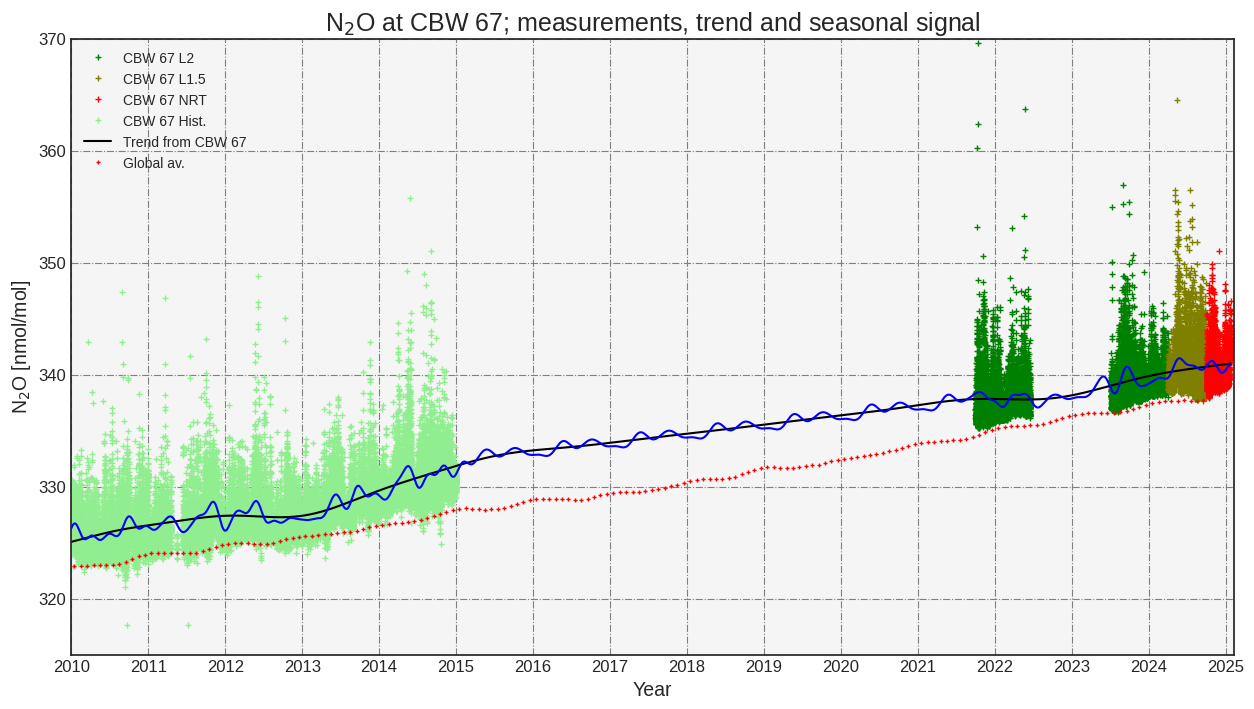

    fname         lname                orcid  \
0  Arnoud        Frumau  0000-0001-5940-0285   
1   Arjan        Hensen  0000-0002-8467-7785   
4    Alex     Vermeulen  0000-0002-8158-8787   
3     Pim  van den Bulk  0000-0002-5393-7898   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Arnoud...    70.0   
1  http://meta.icos-cp.eu/resources/people/Arjan_...    70.0   
4  http://meta.icos-cp.eu/resources/people/Alex_V...    70.0   
3  http://meta.icos-cp.eu/resources/people/Pim_Va...     0.0   

                  start                   end  wght  
0  2016-01-01T00:00:00Z                  None    30  
1  1992-01-01T00:00:00Z  2015-12-31T23:59:59Z    30  
4  2000-01-01T00:00:00Z  2014-01-01T00:00:00Z    30  
3  1992-01-01T00:00:00Z                  None   100  
Done writing  ./data/n2o/nc/n2o_cbw_tower-insitu_445_allvalid-67magl.nc
Done saving  ./data/n2o/txt/n2o_cbw_tower-insitu_445_allvalid-67magl.txt
Done saving  ./data/n2o

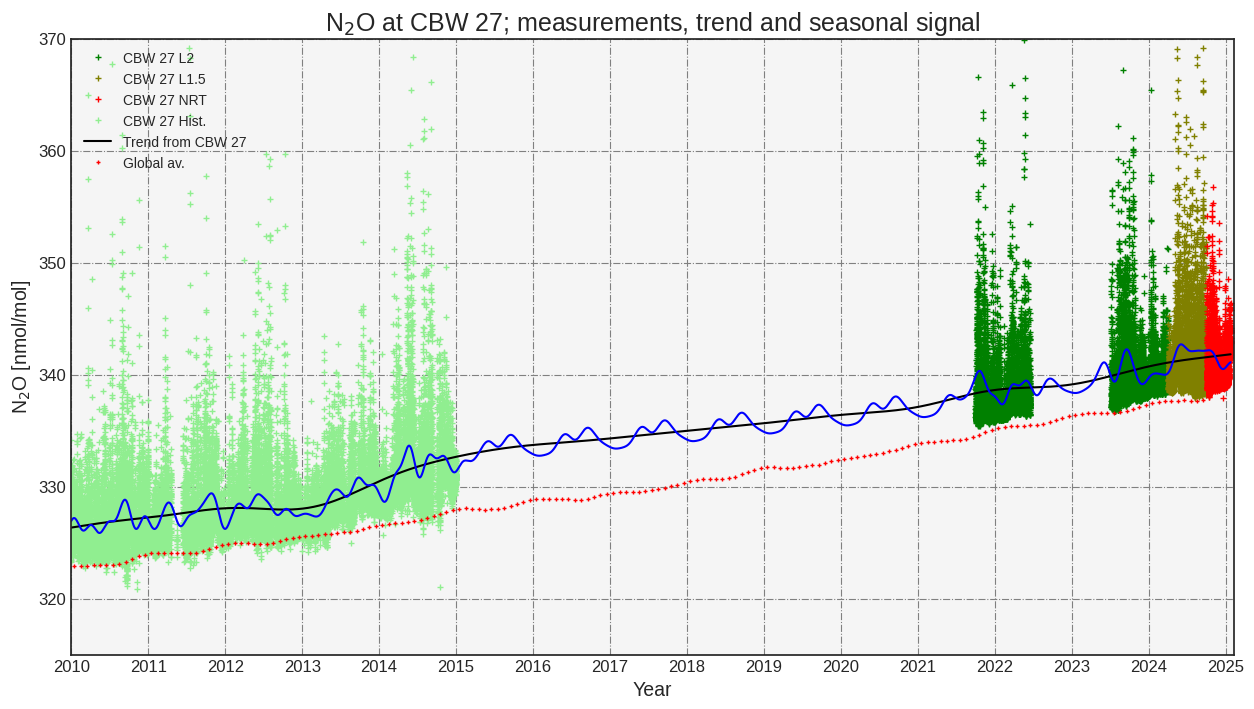

    fname         lname                orcid  \
0  Arnoud        Frumau  0000-0001-5940-0285   
1   Arjan        Hensen  0000-0002-8467-7785   
4    Alex     Vermeulen  0000-0002-8158-8787   
3     Pim  van den Bulk  0000-0002-5393-7898   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Arnoud...    70.0   
1  http://meta.icos-cp.eu/resources/people/Arjan_...    70.0   
4  http://meta.icos-cp.eu/resources/people/Alex_V...    70.0   
3  http://meta.icos-cp.eu/resources/people/Pim_Va...     0.0   

                  start                   end  wght  
0  2016-01-01T00:00:00Z                  None    30  
1  1992-01-01T00:00:00Z  2015-12-31T23:59:59Z    30  
4  2000-01-01T00:00:00Z  2014-01-01T00:00:00Z    30  
3  1992-01-01T00:00:00Z                  None   100  
Done writing  ./data/n2o/nc/n2o_cbw_tower-insitu_445_allvalid-27magl.nc
Done saving  ./data/n2o/txt/n2o_cbw_tower-insitu_445_allvalid-27magl.txt
Done saving  ./data/n2o

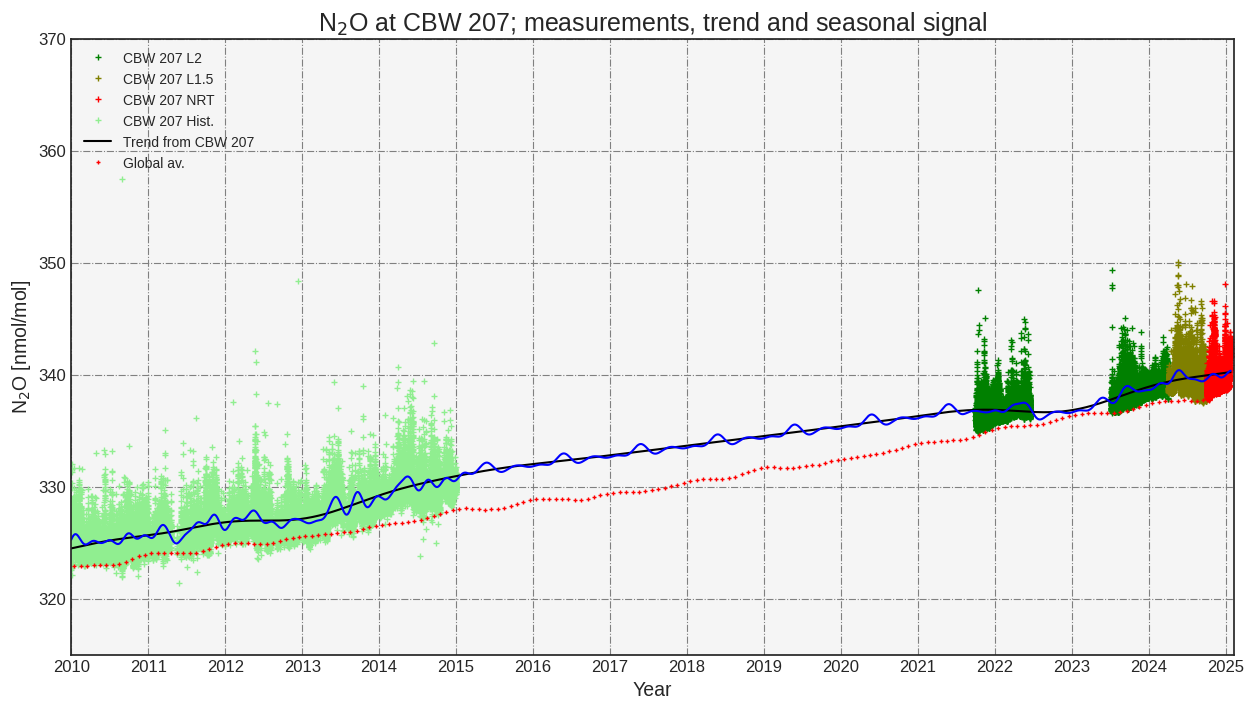

    fname         lname                orcid  \
0  Arnoud        Frumau  0000-0001-5940-0285   
1   Arjan        Hensen  0000-0002-8467-7785   
4    Alex     Vermeulen  0000-0002-8158-8787   
3     Pim  van den Bulk  0000-0002-5393-7898   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Arnoud...    70.0   
1  http://meta.icos-cp.eu/resources/people/Arjan_...    70.0   
4  http://meta.icos-cp.eu/resources/people/Alex_V...    70.0   
3  http://meta.icos-cp.eu/resources/people/Pim_Va...     0.0   

                  start                   end  wght  
0  2016-01-01T00:00:00Z                  None    30  
1  1992-01-01T00:00:00Z  2015-12-31T23:59:59Z    30  
4  2000-01-01T00:00:00Z  2014-01-01T00:00:00Z    30  
3  1992-01-01T00:00:00Z                  None   100  
Done writing  ./data/n2o/nc/n2o_cbw_tower-insitu_445_allvalid-207magl.nc
Done saving  ./data/n2o/txt/n2o_cbw_tower-insitu_445_allvalid-207magl.txt
Done saving  ./data/n

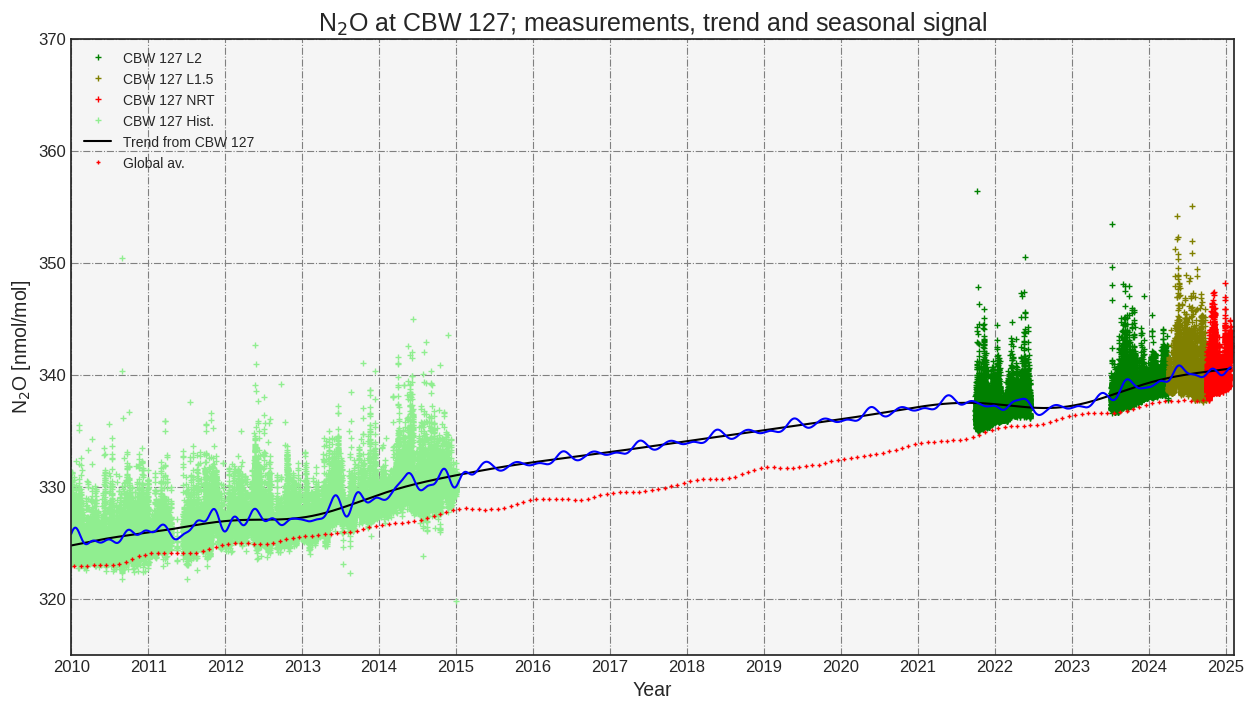

    fname         lname                orcid  \
0  Arnoud        Frumau  0000-0001-5940-0285   
1   Arjan        Hensen  0000-0002-8467-7785   
4    Alex     Vermeulen  0000-0002-8158-8787   
3     Pim  van den Bulk  0000-0002-5393-7898   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Arnoud...    70.0   
1  http://meta.icos-cp.eu/resources/people/Arjan_...    70.0   
4  http://meta.icos-cp.eu/resources/people/Alex_V...    70.0   
3  http://meta.icos-cp.eu/resources/people/Pim_Va...     0.0   

                  start                   end  wght  
0  2016-01-01T00:00:00Z                  None    30  
1  1992-01-01T00:00:00Z  2015-12-31T23:59:59Z    30  
4  2000-01-01T00:00:00Z  2014-01-01T00:00:00Z    30  
3  1992-01-01T00:00:00Z                  None   100  
Done writing  ./data/n2o/nc/n2o_cbw_tower-insitu_445_allvalid-127magl.nc
Done saving  ./data/n2o/txt/n2o_cbw_tower-insitu_445_allvalid-127magl.txt
Done saving  ./data/n

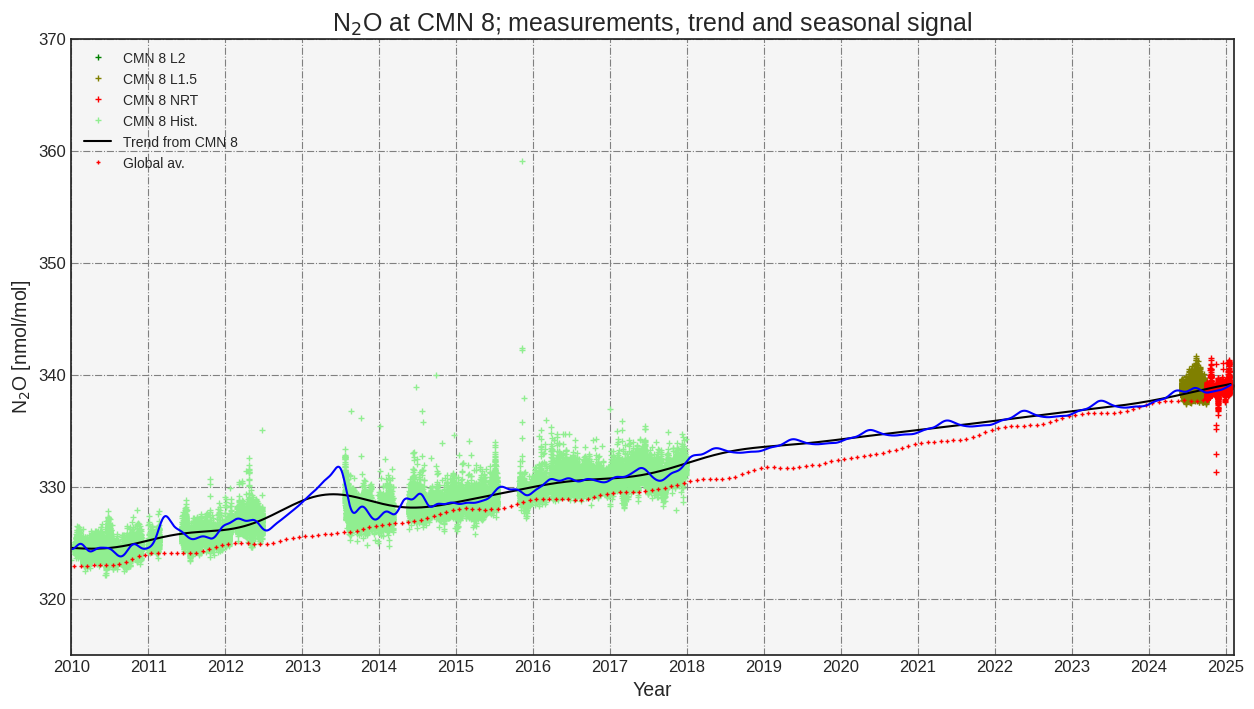

            fname          lname                orcid  \
3           Paolo  Cristofanelli  0000-0001-5666-9131   
6       Simonetta      Montaguti                        
2          Pamela      Trisolino  0000-0003-1786-5310   
7      Alessandro         Bracci  0000-0001-7047-6213   
1        Maurizio        Busetto  0000-0003-1115-6564   
0  Francescopiero      Calzolari  0000-0003-4535-9626   
4          Cosimo    Fratticioli  0000-0003-1989-6233   

                                                 uri weight  \
3  http://meta.icos-cp.eu/resources/people/Paolo_...     70   
6  http://meta.icos-cp.eu/resources/people/Simone...     20   
2  http://meta.icos-cp.eu/resources/people/Pamela...     20   
7  http://meta.icos-cp.eu/resources/people/Alessa...      0   
1  http://meta.icos-cp.eu/resources/people/Mauriz...      0   
0  http://meta.icos-cp.eu/resources/people/France...      0   
4  http://meta.icos-cp.eu/resources/people/Cosimo...      0   

                  start               

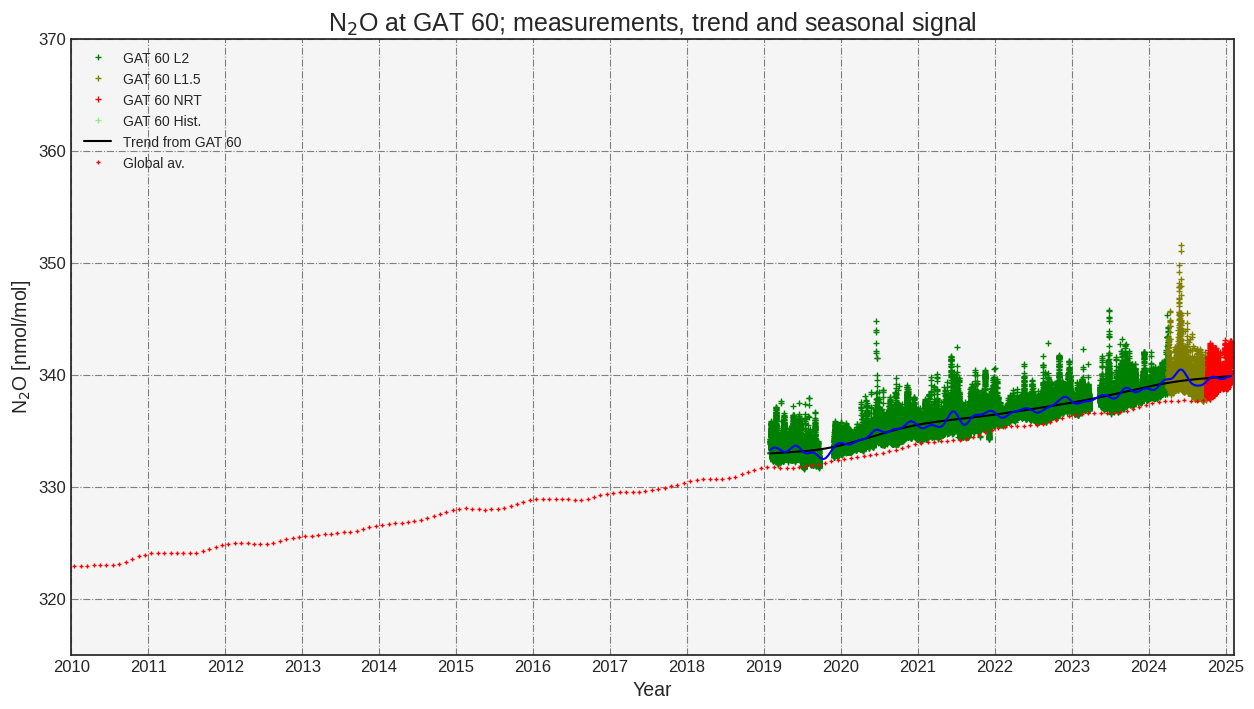

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
6  Christian      Plaß-Dülmer                        
1    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
2   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
3     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
6  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
1  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
2  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
3  http://m

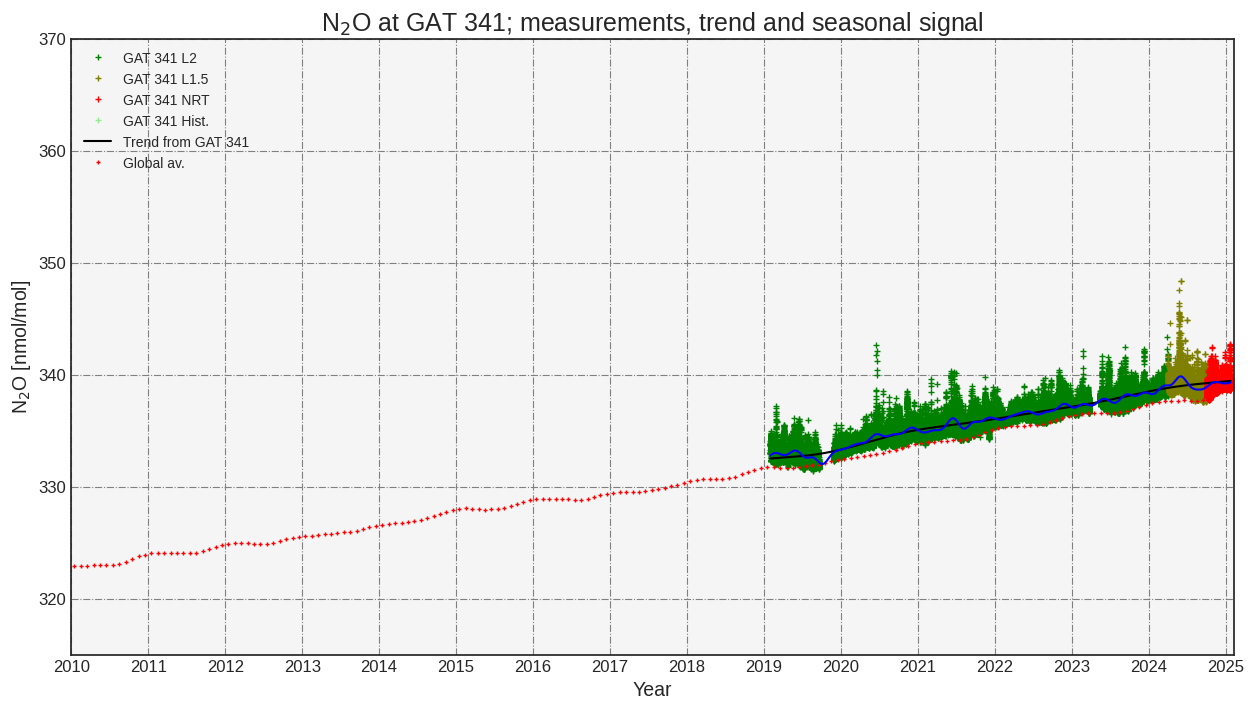

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
6  Christian      Plaß-Dülmer                        
1    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
2   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
3     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
6  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
1  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
2  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
3  http://m

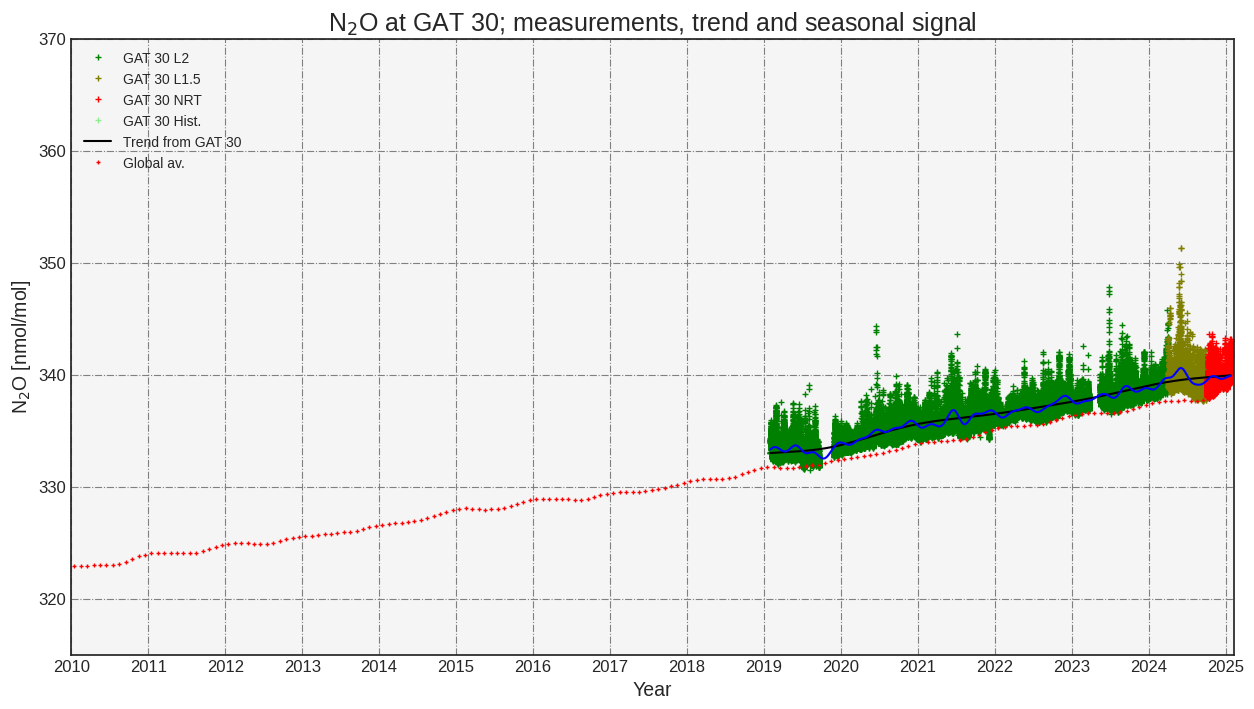

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
6  Christian      Plaß-Dülmer                        
1    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
2   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
3     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
6  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
1  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
2  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
3  http://m

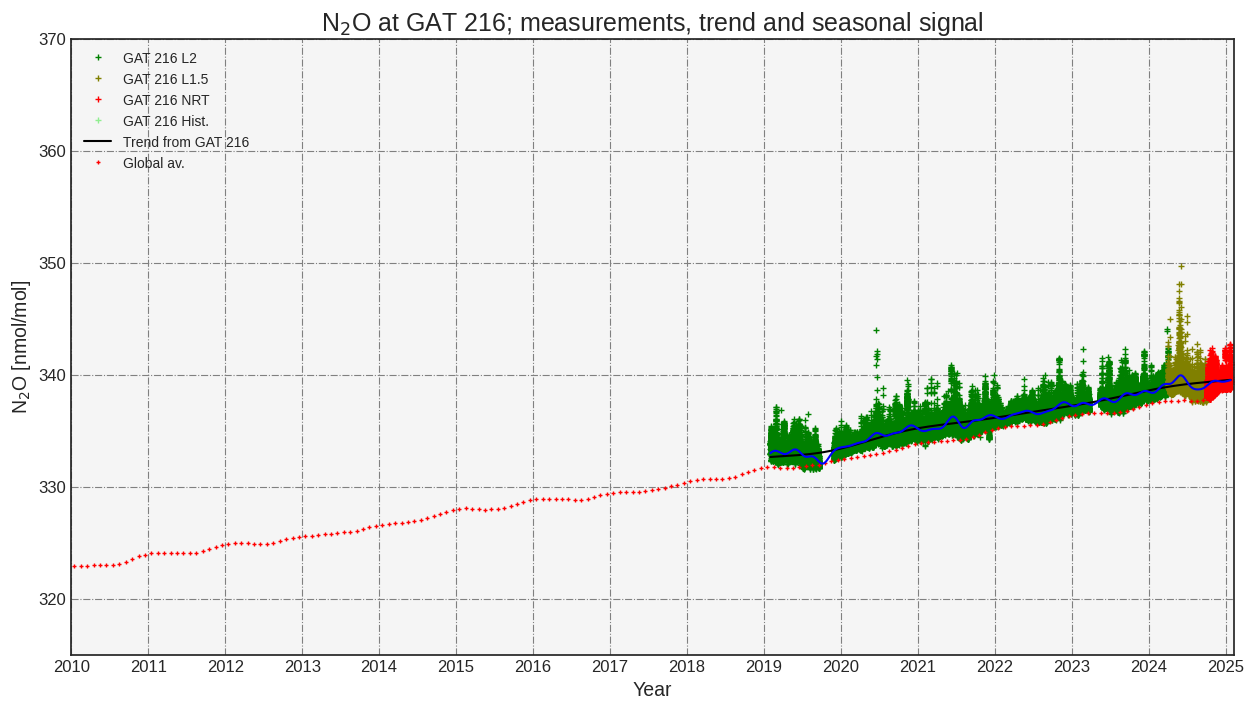

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
6  Christian      Plaß-Dülmer                        
1    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
2   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
3     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
6  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
1  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
2  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
3  http://m

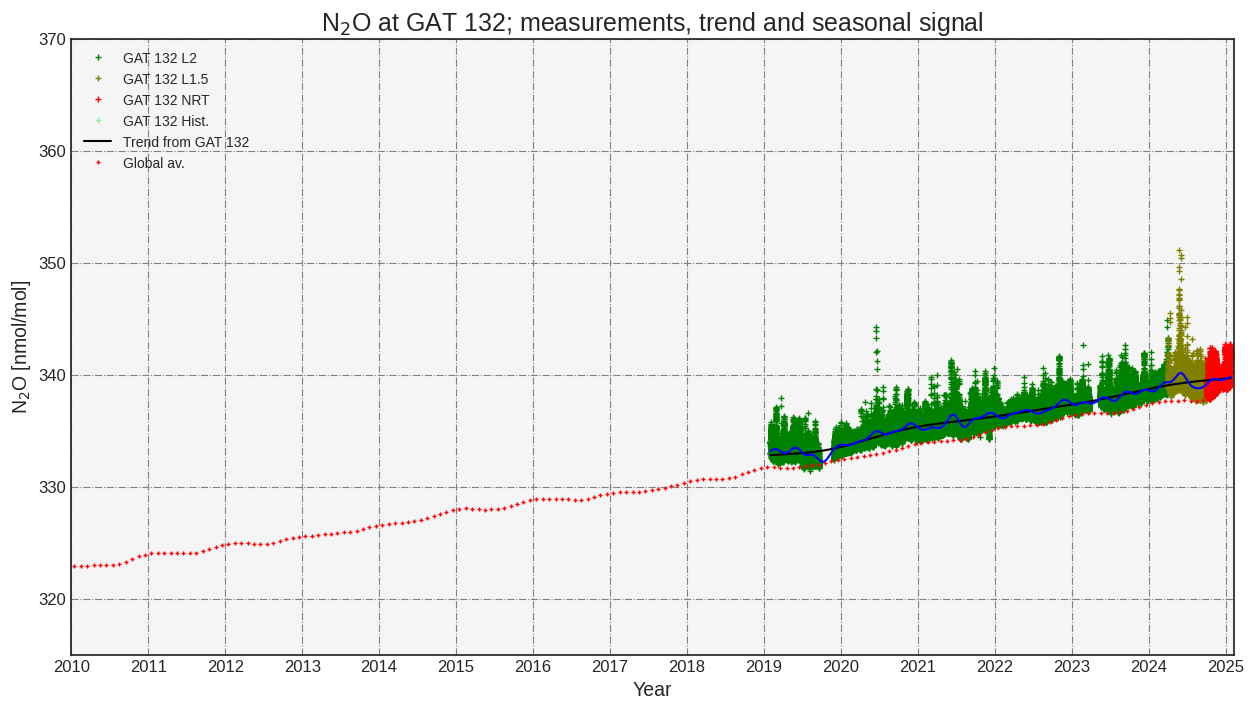

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
6  Christian      Plaß-Dülmer                        
1    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
2   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
3     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
6  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
1  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
2  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
3  http://m

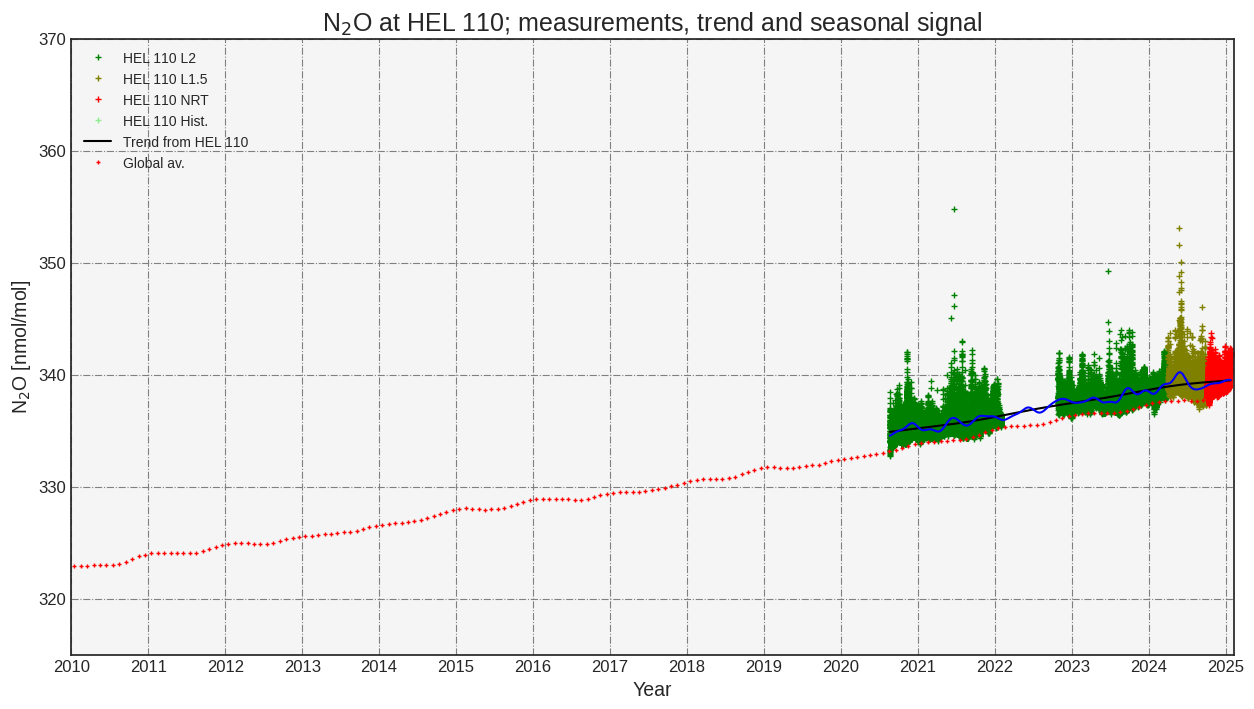

       fname            lname                orcid  \
3     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
1    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
4   Matthias         Lindauer  0000-0001-9274-8750   
5   Jennifer  Müller-Williams  0000-0002-4840-7729   
0     Marcus       Schumacher                        
6    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
2  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
1  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
4  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
5  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
0  http://m

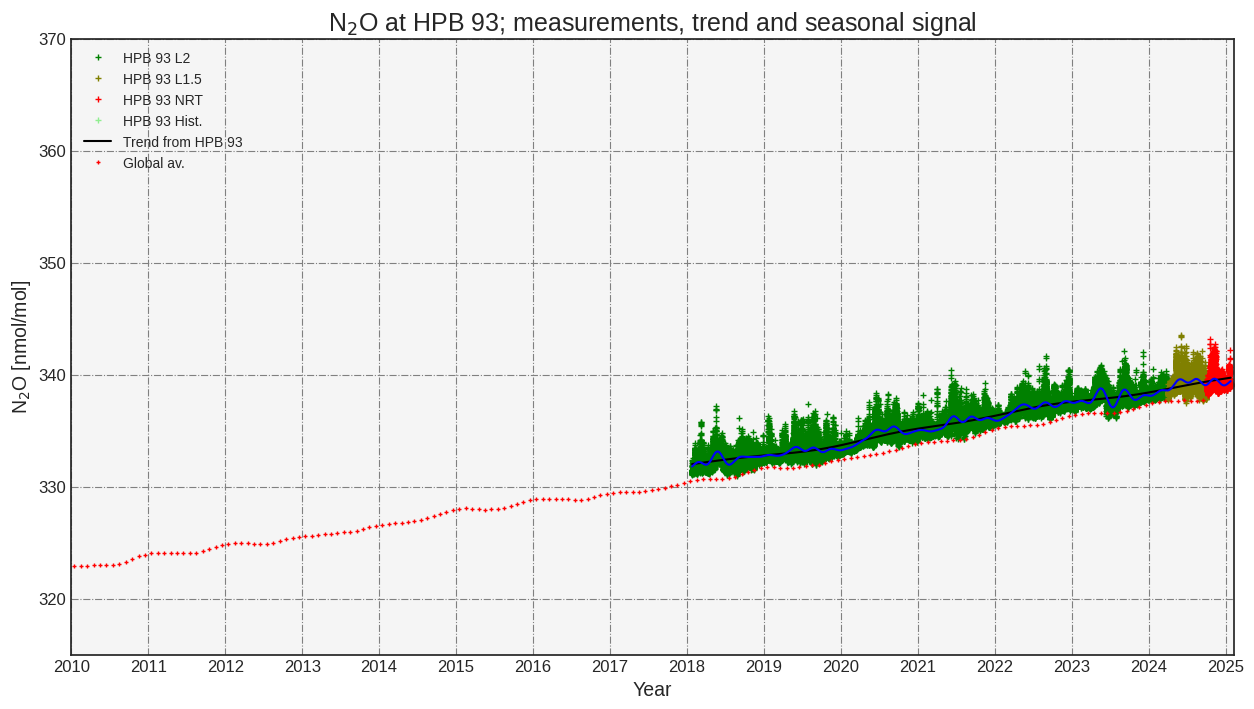

       fname            lname                orcid  \
3     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
0   Matthias         Lindauer  0000-0001-9274-8750   
5   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
6    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
2  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
0  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
5  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
1  http://m

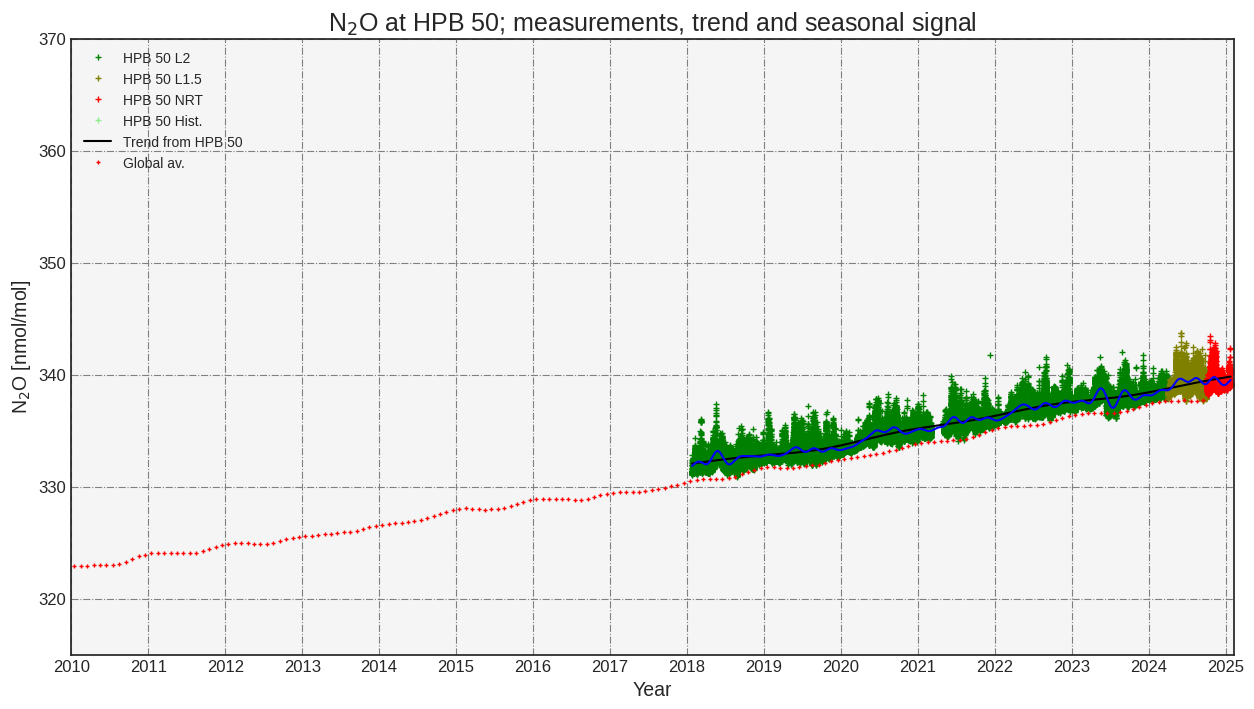

       fname            lname                orcid  \
3     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
0   Matthias         Lindauer  0000-0001-9274-8750   
5   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
6    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
2  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
0  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
5  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
1  http://m

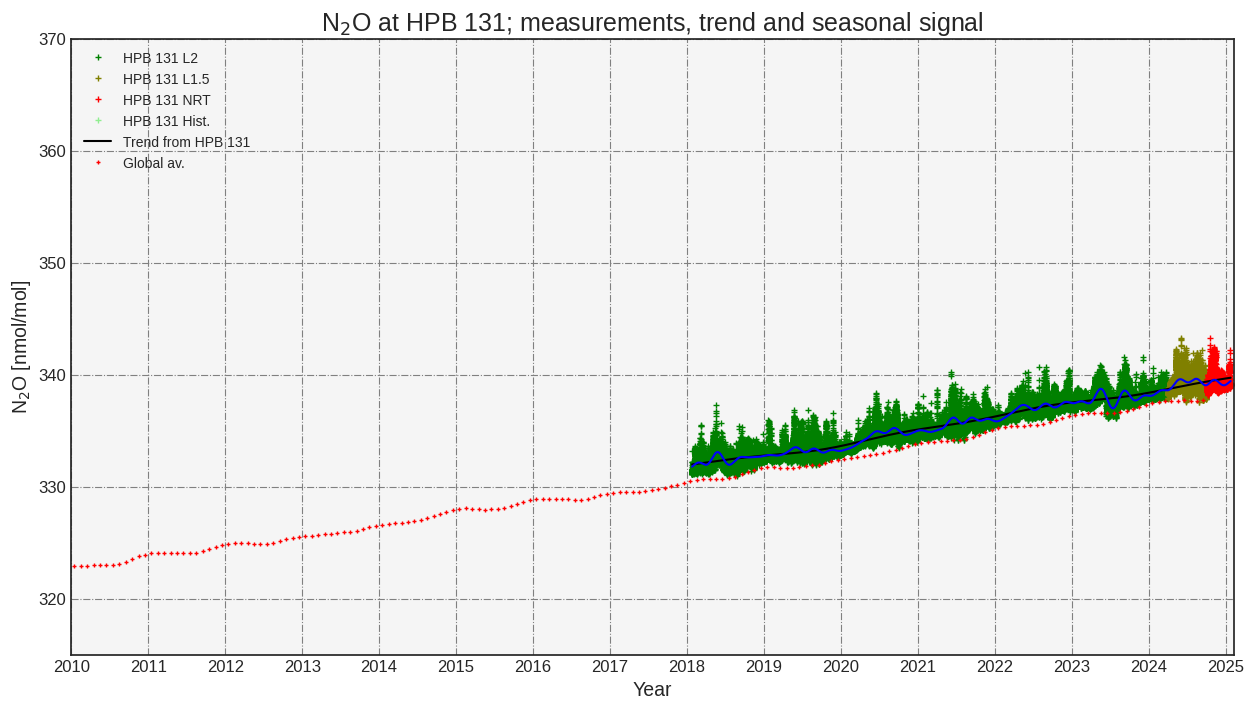

       fname            lname                orcid  \
3     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
0   Matthias         Lindauer  0000-0001-9274-8750   
5   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
6    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
2  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
0  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
5  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
1  http://m

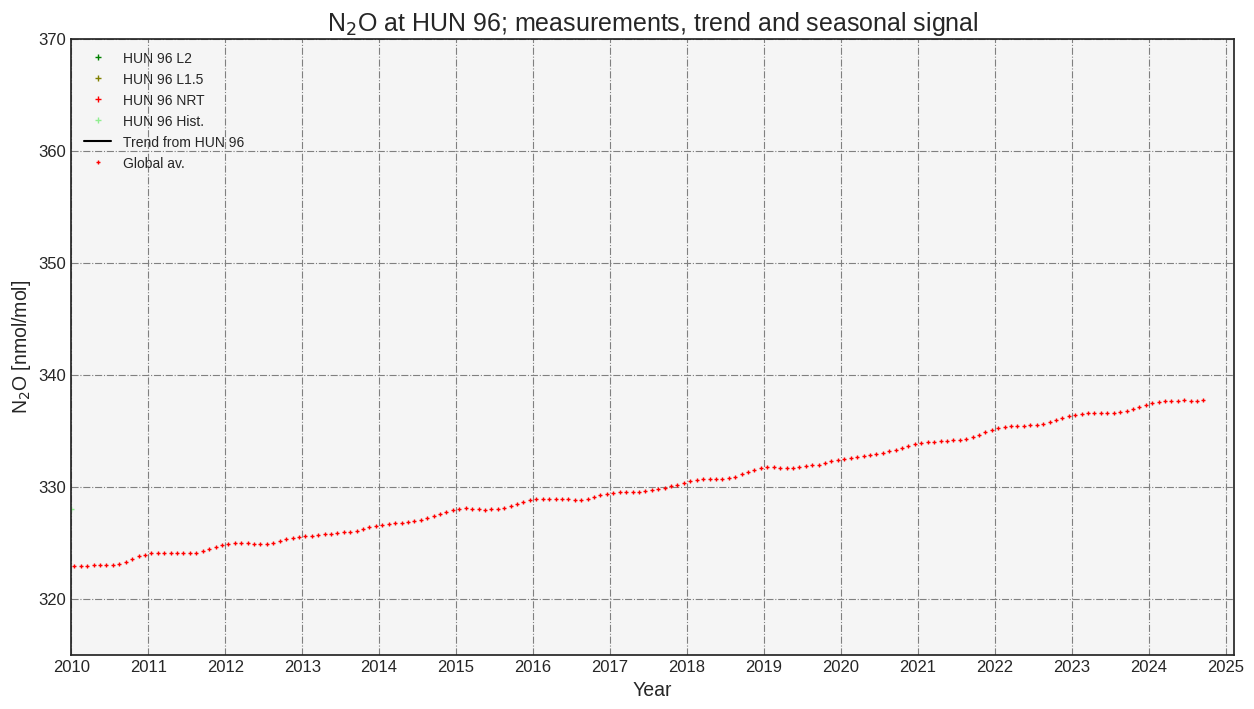

    fname    lname orcid                                                uri  \
0  Laszlo  Haszpra        http://meta.icos-cp.eu/resources/people/Laszlo...   
2  Mihály   Molnár        http://meta.icos-cp.eu/resources/people/Mih%C3...   
1  Sándor      Bán        http://meta.icos-cp.eu/resources/people/S%C3%A...   

   weight                 start   end  wght  
0    70.0                  None  None    30  
2    70.0  2023-09-04T00:00:00Z  None    30  
1     0.0  2023-09-04T00:00:00Z  None   100  
Done writing  ./data/n2o/nc/n2o_hun_surface-insitu_35_allvalid.nc
Done saving  ./data/n2o/txt/n2o_hun_surface-insitu_35_allvalid.txt
Done saving  ./data/n2o/nc/n2o_hun_surface-insitu_35_allvalid.json
IPR
IPR  Height: 16.0  Class: 2  NrFiles: 1
http://meta.icos-cp.eu/resources/cpmeta/atcN2oProduct
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22QtSxCV__84UqoUC9zjJMhveL%22%5D
hit cache for  ./cache/ICOS_ATC_OBSPACK-Europe-L2-2024_IPR_16.0_CTS_N2O.zip


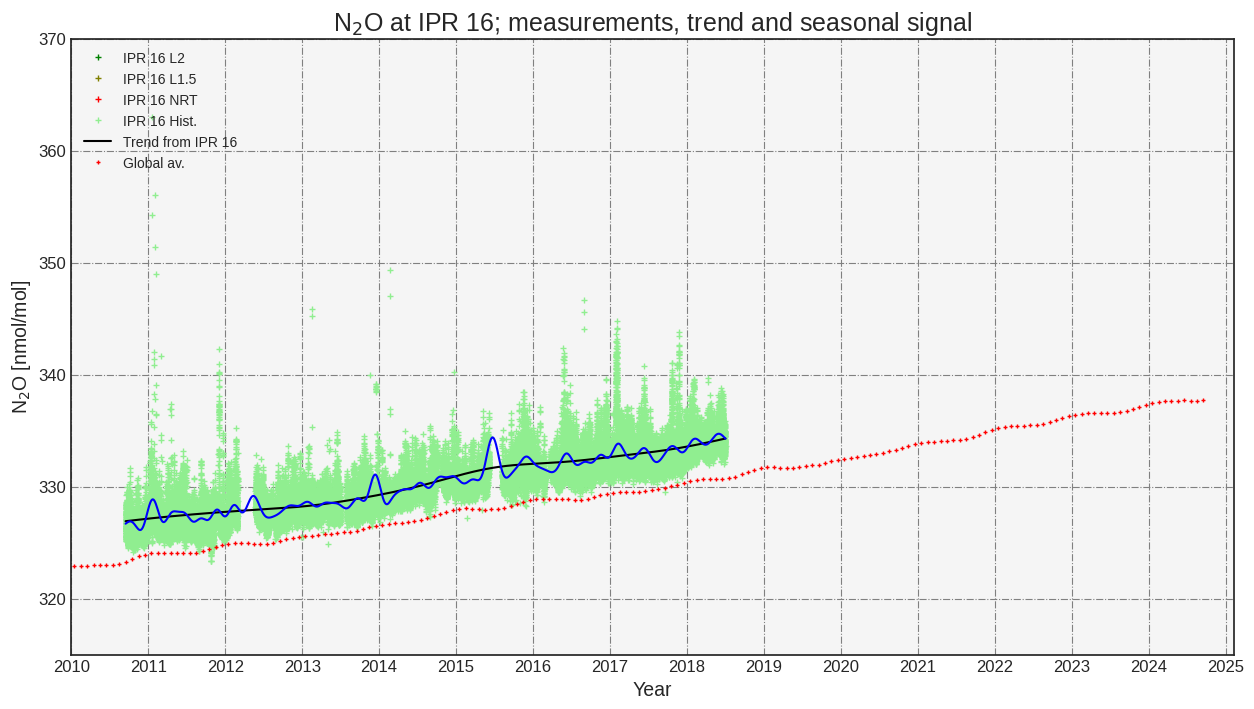

      fname        lname                orcid  \
0     Peter  Bergamaschi  0000-0003-4555-1829   
1  Giovanni        Manca  0000-0002-9376-0310   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Peter_...   100.0   
1  http://meta.icos-cp.eu/resources/people/Giovan...    70.0   

                  start                   end  wght  
0  2017-12-10T00:00:00Z  2020-12-31T23:59:59Z     0  
1  2017-12-10T00:00:00Z                  None    30  
Done writing  ./data/n2o/nc/n2o_ipr_surface-insitu_103_allvalid.nc
Done saving  ./data/n2o/txt/n2o_ipr_surface-insitu_103_allvalid.txt
Done saving  ./data/n2o/nc/n2o_ipr_surface-insitu_103_allvalid.json
IVI
IZO
IZO  Height: 29.0  Class: 2  NrFiles: 4
http://meta.icos-cp.eu/resources/cpmeta/atcN2oNrtGrowingDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22i612Oe3RJn1J-KDnBVTpG524%22%5D
hit cache for  ./cache/ICOS_ATC_NRT_IZO_2024-04-01_2025-01-22_29.0_1237_N2O.zip
http://meta.ic

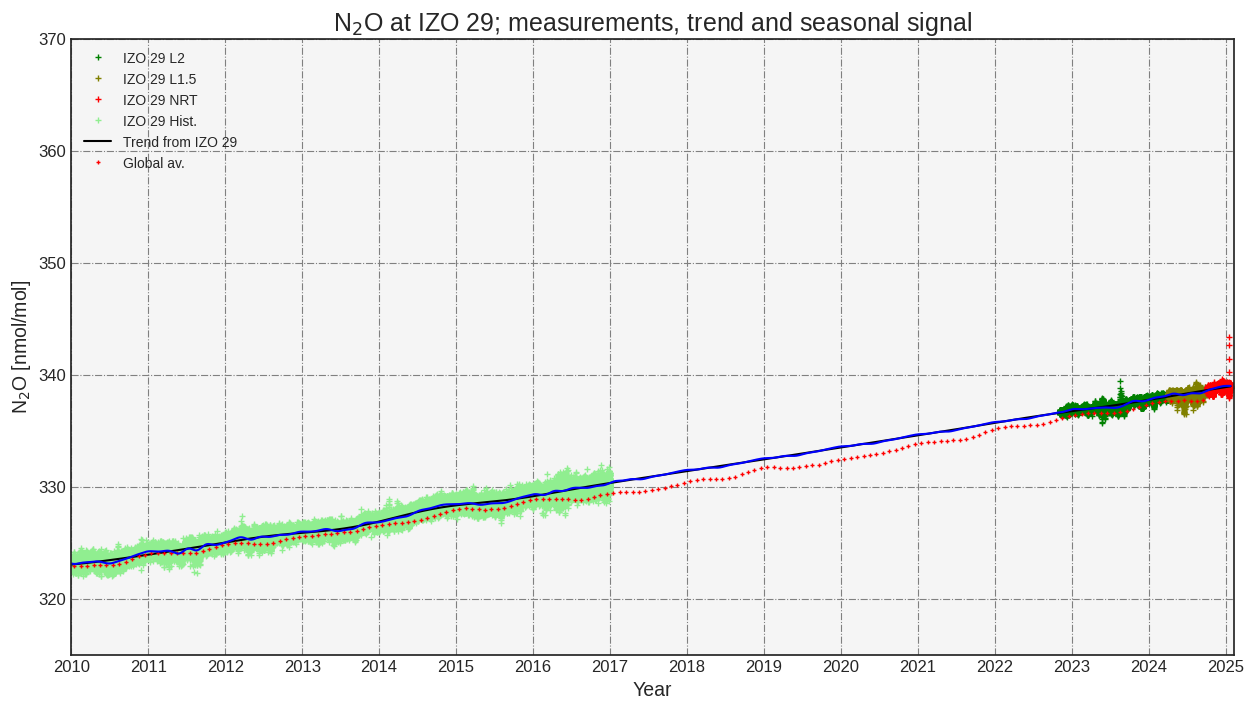

   fname          lname orcid  \
0  Pedro  Rivas-Soriano         

                                                 uri  weight start   end  wght  
0  http://meta.icos-cp.eu/resources/people/Pedro_...    70.0  None  None    30  
Done writing  ./data/n2o/nc/n2o_izo_surface-insitu_27_allvalid.nc
Done saving  ./data/n2o/txt/n2o_izo_surface-insitu_27_allvalid.txt
Done saving  ./data/n2o/nc/n2o_izo_surface-insitu_27_allvalid.json
JAR
JFJ
JFJ  Height: 13.9  Class: 1  NrFiles: 5
http://meta.icos-cp.eu/resources/cpmeta/atcN2oNrtGrowingDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22F6ZvDuetwYhVRt4gg97yIIvx%22%5D
hit cache for  ./cache/ICOS_ATC_NRT_JFJ_2024-04-01_2025-01-22_13.9_1102_N2O.zip
http://meta.icos-cp.eu/resources/cpmeta/atcGHGFastTrackNRTDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%226OSfhKBWvMUlcrEvOUpoY3i_%22%5D
hit cache for  ./cache/ICOS_ATC_L1_FAST_TRACK_L1-FastTrack-2025.1_JFJ_13.9_CTS_N2O.zip
http://meta.icos-cp.eu/resources/cpmeta/atcN2oProd

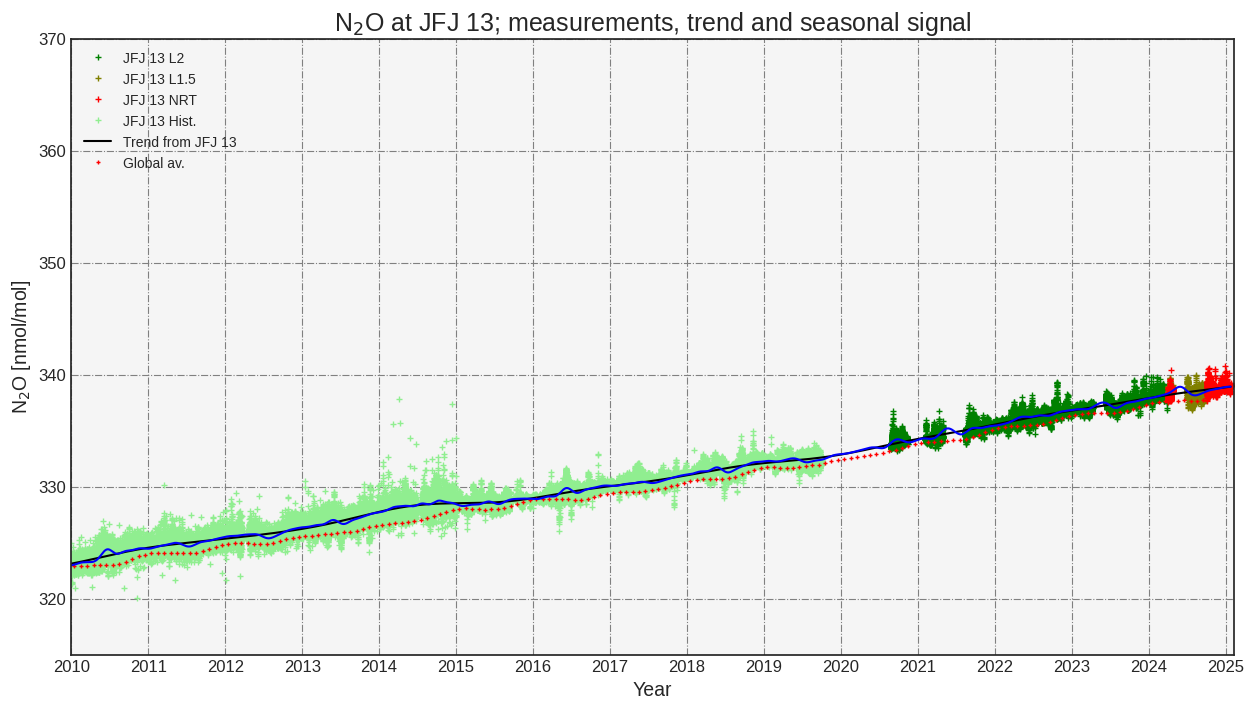

        fname        lname                orcid  \
4       Lukas   Emmenegger  0000-0002-9812-3986   
2      Markus  Leuenberger  0000-0003-4299-6793   
0      Martin  Steinbacher  0000-0002-7195-8115   
1       Franz        Conen  0000-0003-4821-5775   
5  Yves-Alain       Roulet                        
6       Lukas         Bäni                        
7       Julia      Friedli                        
3       David       Steger                        

                                                 uri  weight  \
4  http://meta.icos-cp.eu/resources/people/Lukas_...   100.0   
2  http://meta.icos-cp.eu/resources/people/Markus...   100.0   
0  http://meta.icos-cp.eu/resources/people/Martin...    70.0   
1  http://meta.icos-cp.eu/resources/people/Franz_...    40.0   
5  http://meta.icos-cp.eu/resources/people/Yves-A...    40.0   
6  http://meta.icos-cp.eu/resources/people/Lukas_...     0.0   
7  http://meta.icos-cp.eu/resources/people/Julia_...     0.0   
3  http://meta.icos-cp.eu/re

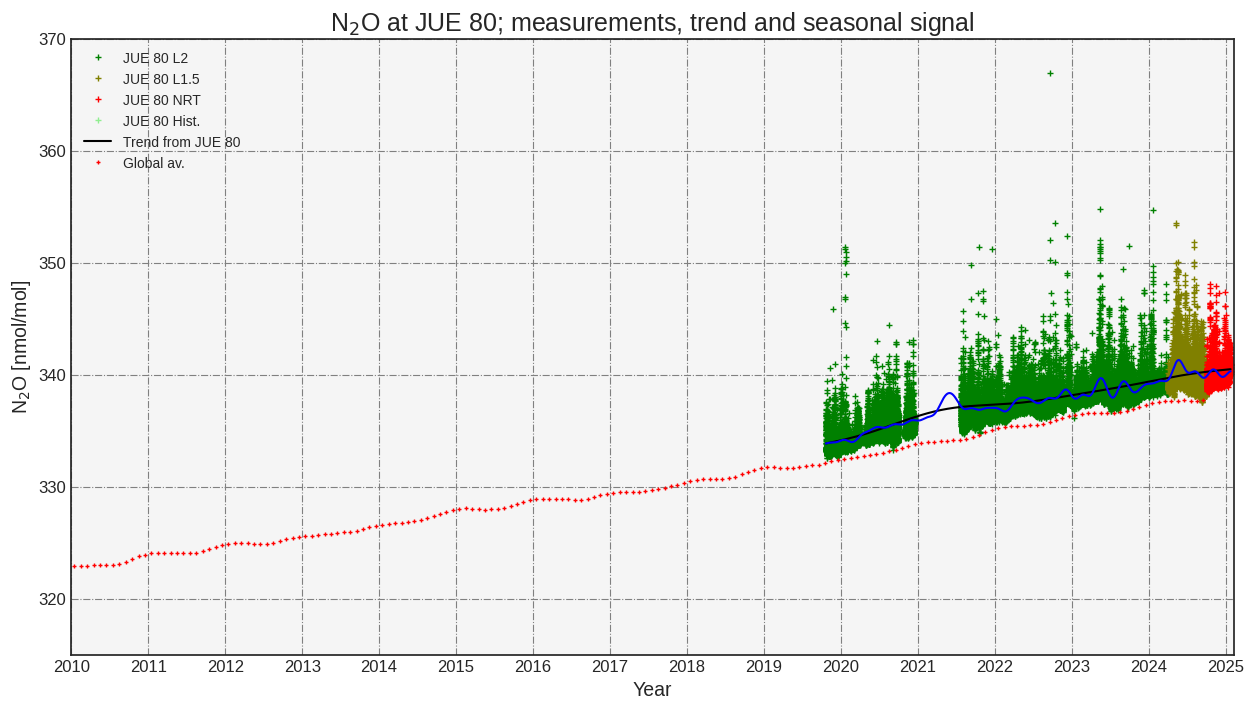

       fname            lname                orcid  \
2     Dagmar         Kubistin  0000-0002-5467-9309   
0  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
2  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
0  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
3  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
4  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
1  http://m

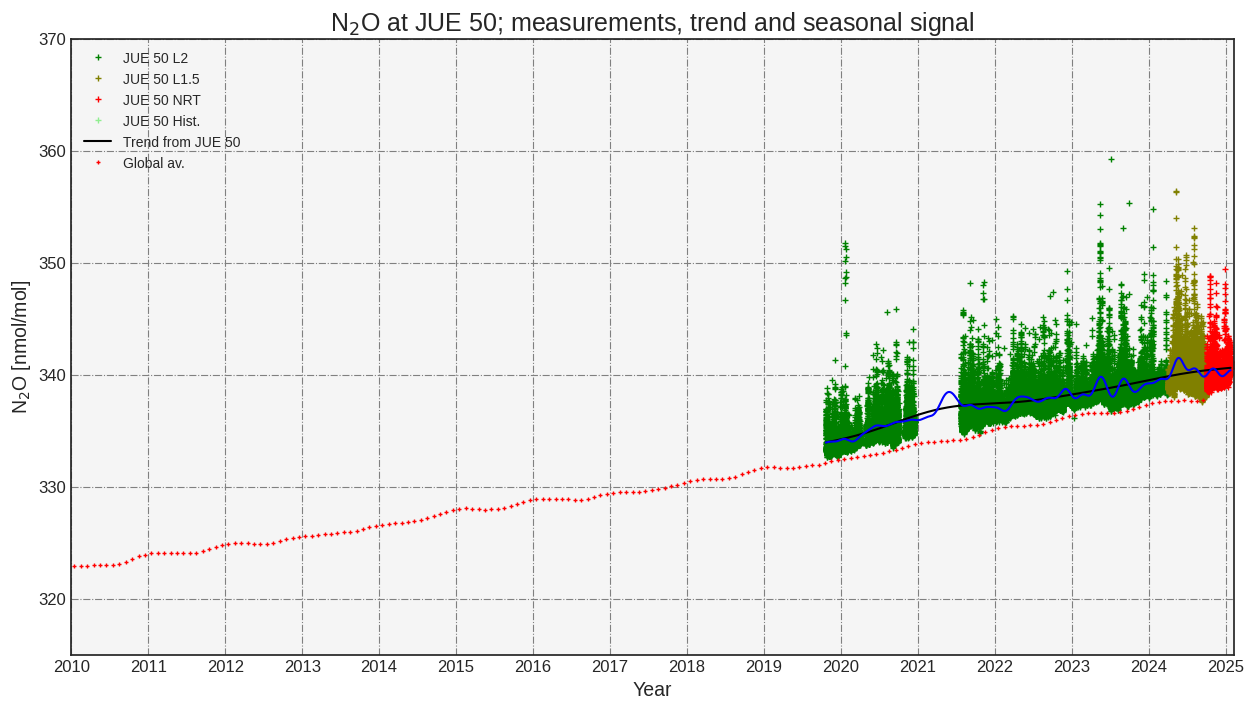

       fname            lname                orcid  \
2     Dagmar         Kubistin  0000-0002-5467-9309   
0  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
2  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
0  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
3  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
4  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
1  http://m

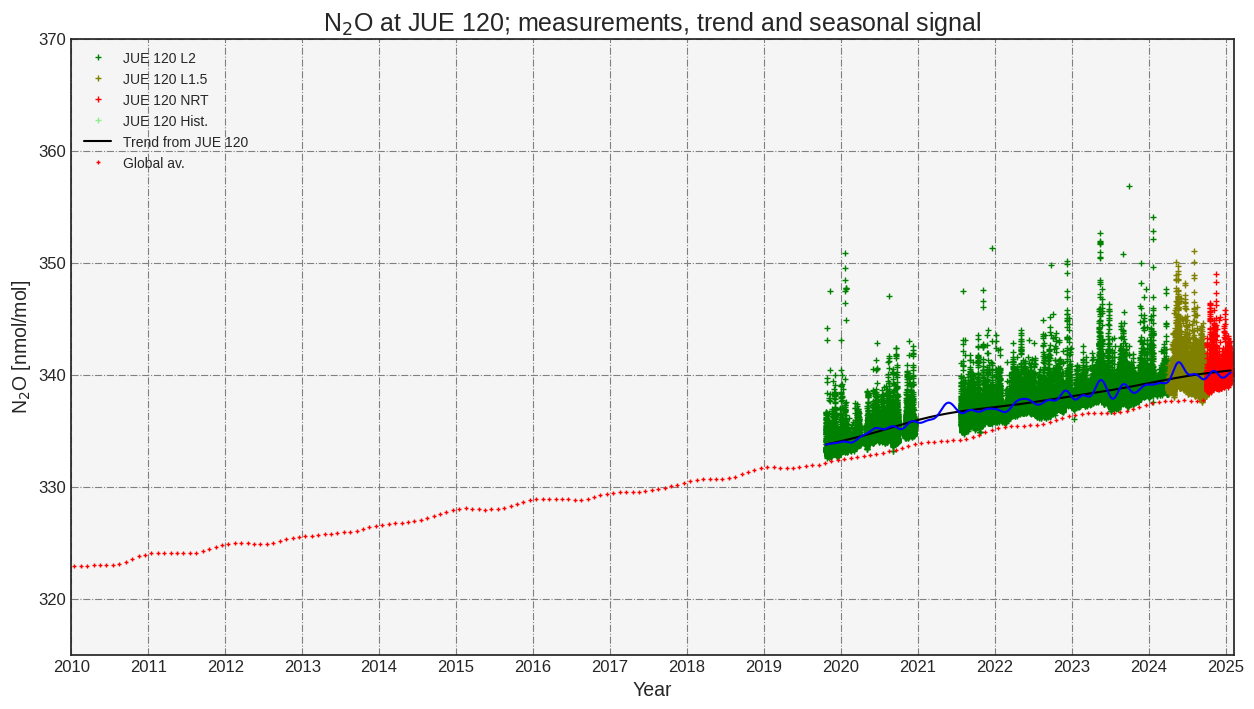

       fname            lname                orcid  \
2     Dagmar         Kubistin  0000-0002-5467-9309   
0  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
2  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
0  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
3  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
4  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
1  http://m

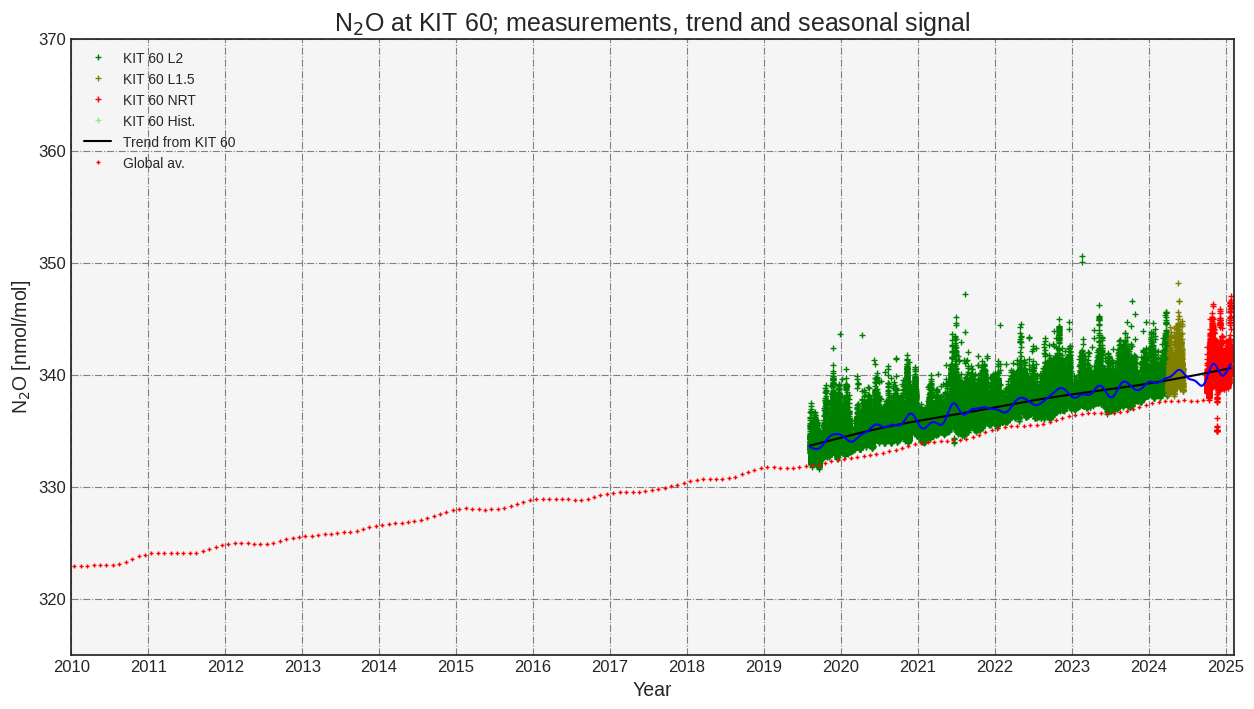

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
0    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...    100   
2  http://meta.icos-cp.eu/resources/people/Christ...    100   
5  http://meta.icos-cp.eu/resources/people/Sabrin...     70   
7  http://meta.icos-cp.eu/resources/people/Tobias...     70   
3  http://meta.icos-cp.eu/resources/people/Matthi...     70   
4  http://meta.icos-cp.eu/resources/people/Jennif...     70   
1  http://meta.ico

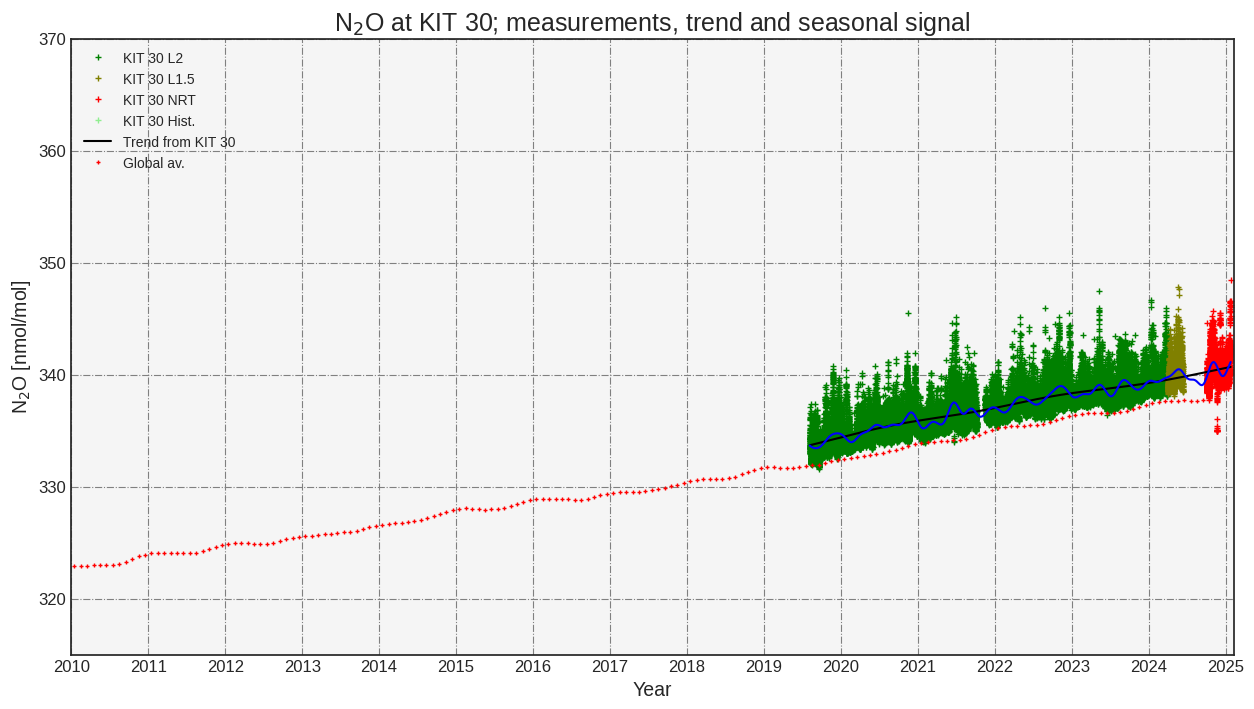

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
0    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...    100   
2  http://meta.icos-cp.eu/resources/people/Christ...    100   
5  http://meta.icos-cp.eu/resources/people/Sabrin...     70   
7  http://meta.icos-cp.eu/resources/people/Tobias...     70   
3  http://meta.icos-cp.eu/resources/people/Matthi...     70   
4  http://meta.icos-cp.eu/resources/people/Jennif...     70   
1  http://meta.ico

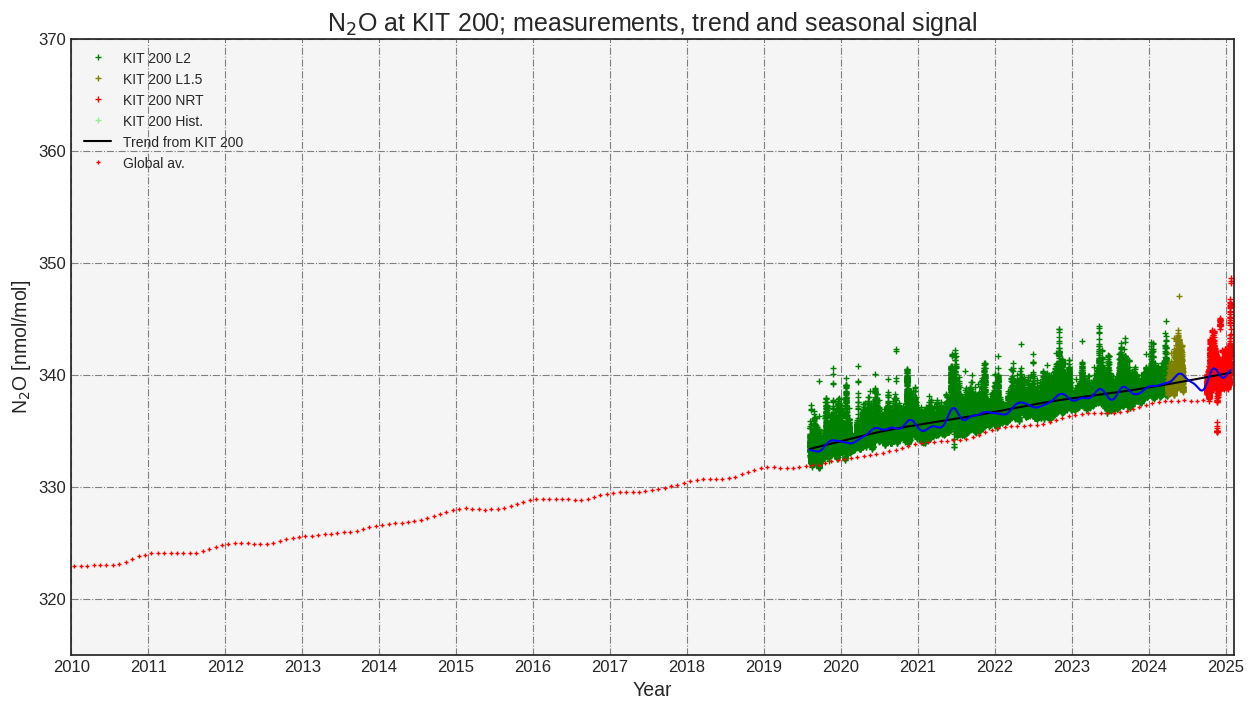

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
0    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...    100   
2  http://meta.icos-cp.eu/resources/people/Christ...    100   
5  http://meta.icos-cp.eu/resources/people/Sabrin...     70   
7  http://meta.icos-cp.eu/resources/people/Tobias...     70   
3  http://meta.icos-cp.eu/resources/people/Matthi...     70   
4  http://meta.icos-cp.eu/resources/people/Jennif...     70   
1  http://meta.ico

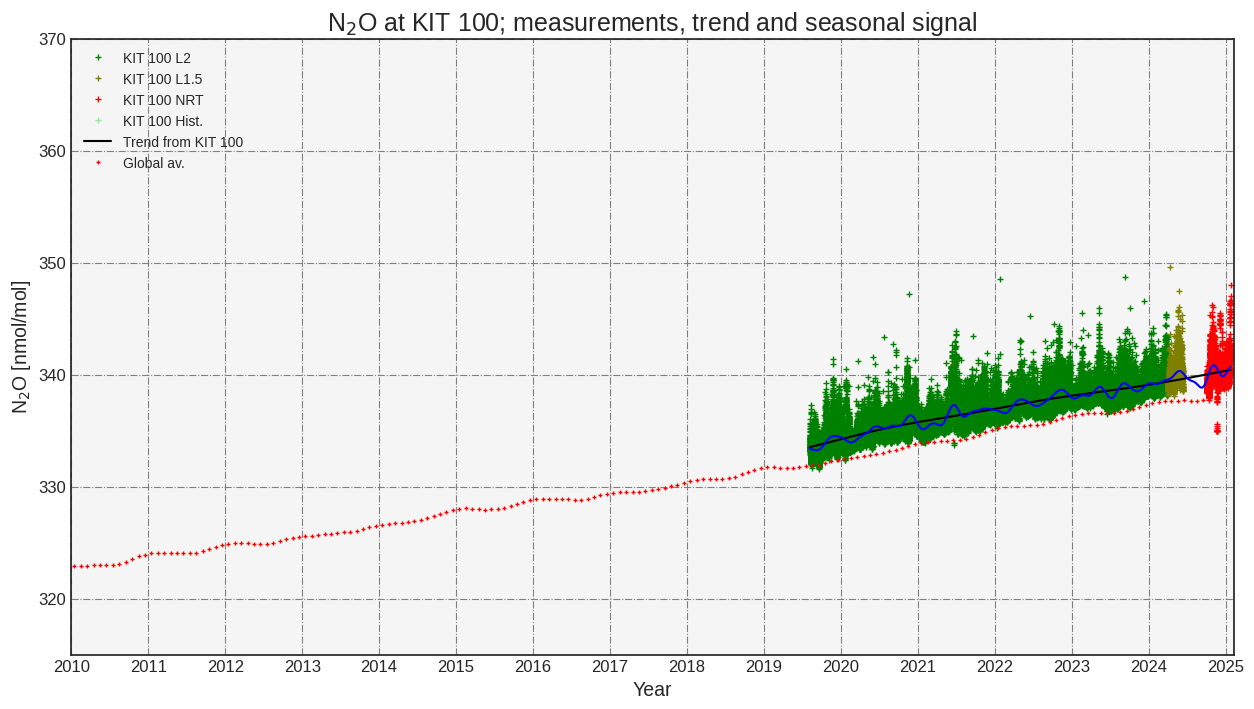

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
2  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
3   Matthias         Lindauer  0000-0001-9274-8750   
4   Jennifer  Müller-Williams  0000-0002-4840-7729   
1     Marcus       Schumacher                        
0    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...    100   
2  http://meta.icos-cp.eu/resources/people/Christ...    100   
5  http://meta.icos-cp.eu/resources/people/Sabrin...     70   
7  http://meta.icos-cp.eu/resources/people/Tobias...     70   
3  http://meta.icos-cp.eu/resources/people/Matthi...     70   
4  http://meta.icos-cp.eu/resources/people/Jennif...     70   
1  http://meta.ico

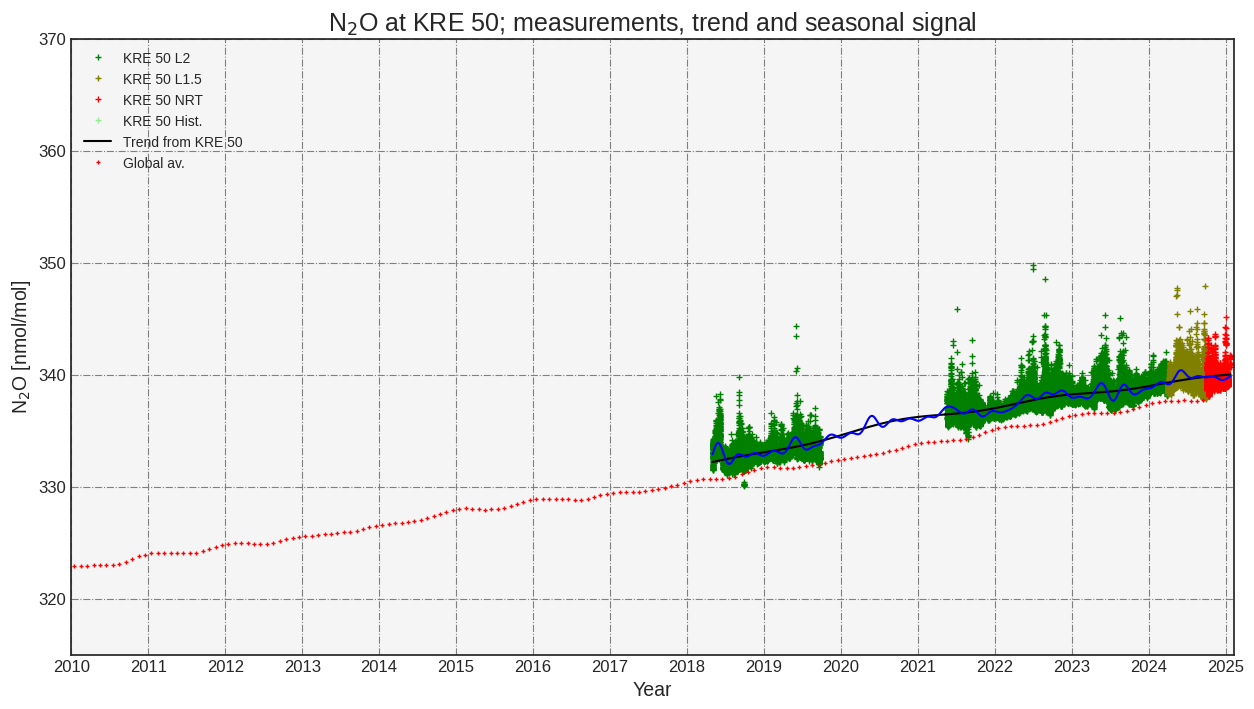

       fname      lname                orcid  \
3  Michal V.      Marek  0000-0003-3349-8987   
1   Gabriela    Vítková  0000-0002-1022-0256   
2   Kateřina  Komínková  0000-0003-4001-9999   
0  Vlastimil      Hanuš                        

                                                 uri weight  \
3  http://meta.icos-cp.eu/resources/people/Michal...    100   
1  http://meta.icos-cp.eu/resources/people/Gabrie...     70   
2  http://meta.icos-cp.eu/resources/people/Kate%C...     20   
0  http://meta.icos-cp.eu/resources/people/Vlasti...      0   

                  start   end  wght  
3  2017-04-12T00:00:00Z  None     0  
1  2017-04-12T00:00:00Z  None    30  
2  2017-04-12T00:00:00Z  None    80  
0  2017-04-12T00:00:00Z  None   100  
Done writing  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-50magl.nc
Done saving  ./data/n2o/txt/n2o_kre_tower-insitu_441_allvalid-50magl.txt
Done saving  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-50magl.json
KRE  Height: 250.0  Class: 1  NrFil

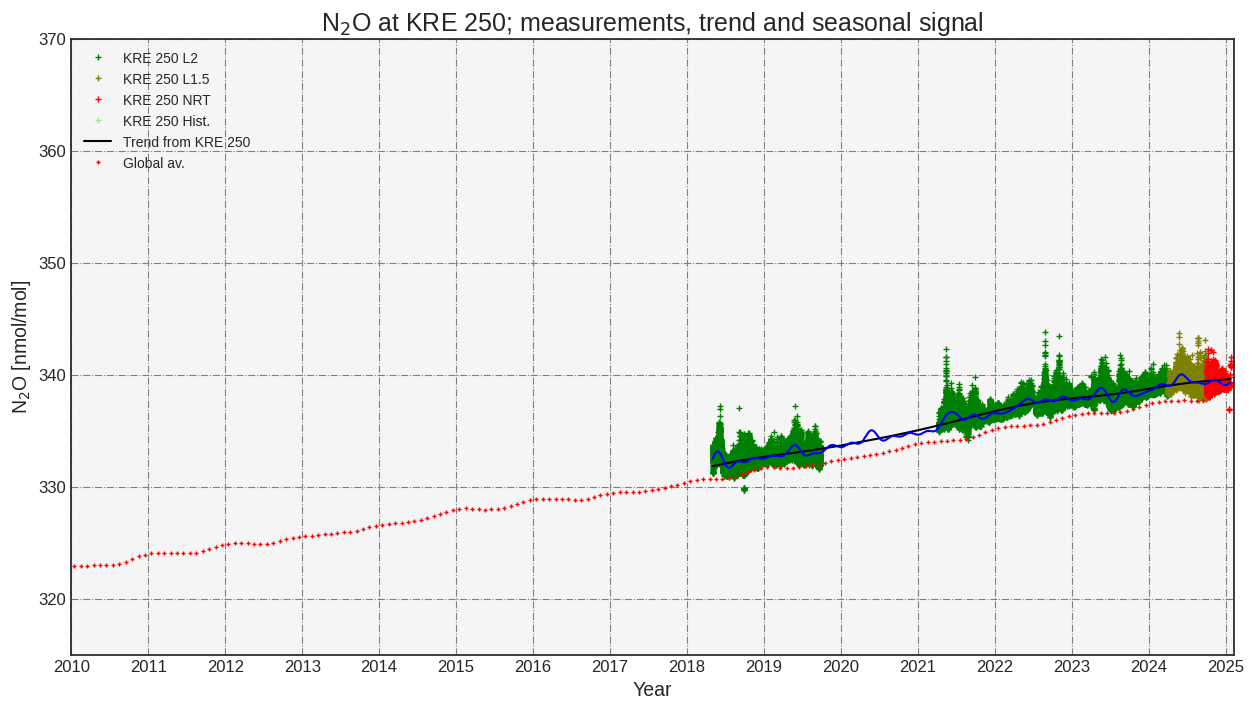

       fname      lname                orcid  \
3  Michal V.      Marek  0000-0003-3349-8987   
1   Gabriela    Vítková  0000-0002-1022-0256   
2   Kateřina  Komínková  0000-0003-4001-9999   
0  Vlastimil      Hanuš                        

                                                 uri weight  \
3  http://meta.icos-cp.eu/resources/people/Michal...    100   
1  http://meta.icos-cp.eu/resources/people/Gabrie...     70   
2  http://meta.icos-cp.eu/resources/people/Kate%C...     20   
0  http://meta.icos-cp.eu/resources/people/Vlasti...      0   

                  start   end  wght  
3  2017-04-12T00:00:00Z  None     0  
1  2017-04-12T00:00:00Z  None    30  
2  2017-04-12T00:00:00Z  None    80  
0  2017-04-12T00:00:00Z  None   100  
Done writing  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-250magl.nc
Done saving  ./data/n2o/txt/n2o_kre_tower-insitu_441_allvalid-250magl.txt
Done saving  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-250magl.json
KRE  Height: 125.0  Class: 1  Nr

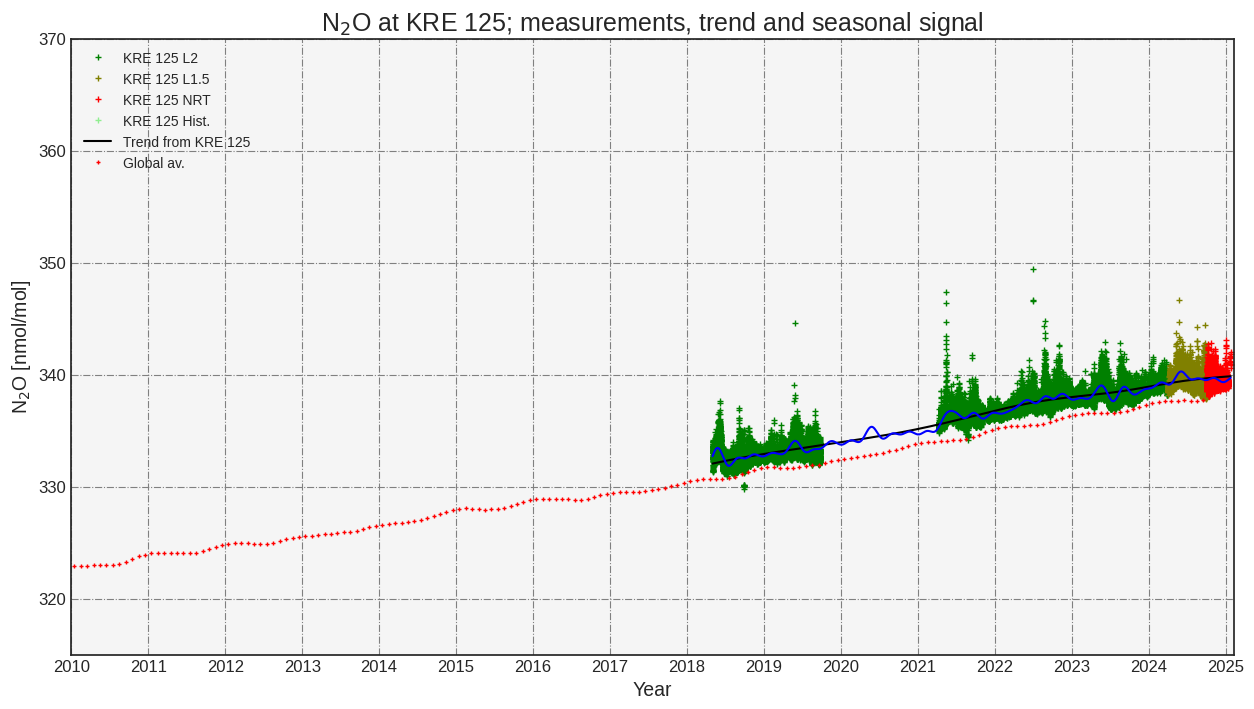

       fname      lname                orcid  \
3  Michal V.      Marek  0000-0003-3349-8987   
1   Gabriela    Vítková  0000-0002-1022-0256   
2   Kateřina  Komínková  0000-0003-4001-9999   
0  Vlastimil      Hanuš                        

                                                 uri weight  \
3  http://meta.icos-cp.eu/resources/people/Michal...    100   
1  http://meta.icos-cp.eu/resources/people/Gabrie...     70   
2  http://meta.icos-cp.eu/resources/people/Kate%C...     20   
0  http://meta.icos-cp.eu/resources/people/Vlasti...      0   

                  start   end  wght  
3  2017-04-12T00:00:00Z  None     0  
1  2017-04-12T00:00:00Z  None    30  
2  2017-04-12T00:00:00Z  None    80  
0  2017-04-12T00:00:00Z  None   100  
Done writing  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-125magl.nc
Done saving  ./data/n2o/txt/n2o_kre_tower-insitu_441_allvalid-125magl.txt
Done saving  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-125magl.json
KRE  Height: 10.0  Class: 1  NrF

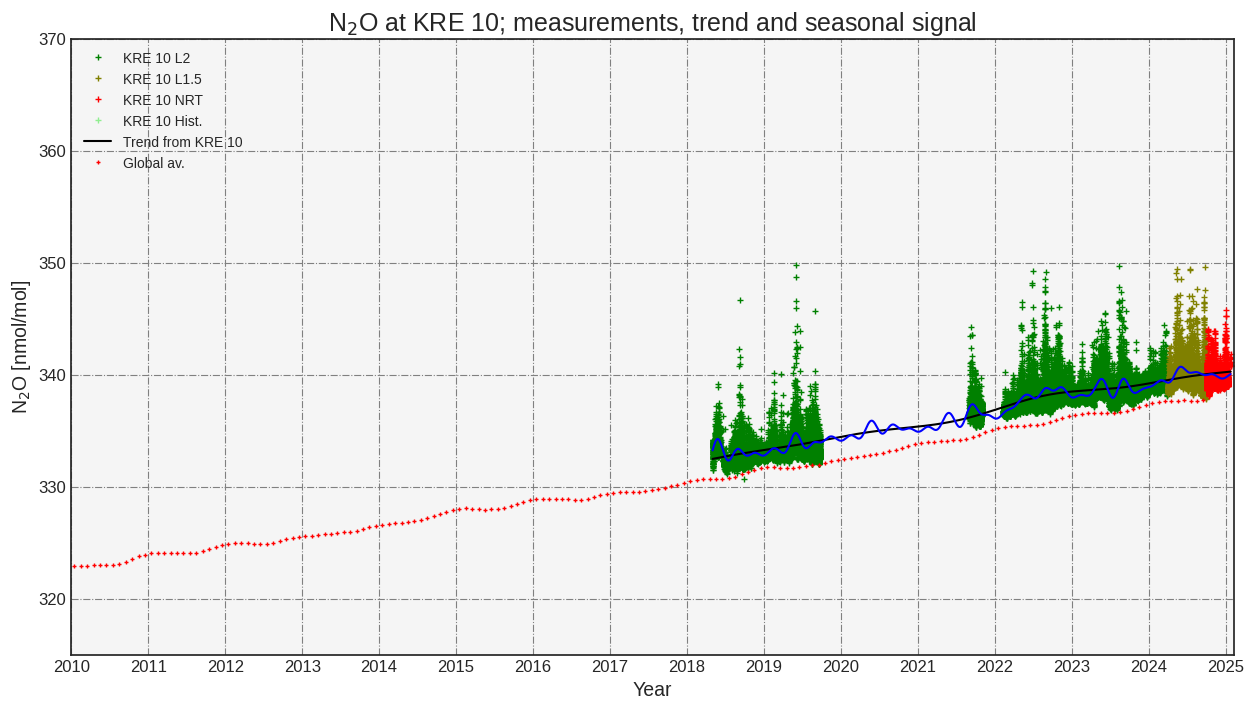

       fname      lname                orcid  \
3  Michal V.      Marek  0000-0003-3349-8987   
1   Gabriela    Vítková  0000-0002-1022-0256   
2   Kateřina  Komínková  0000-0003-4001-9999   
0  Vlastimil      Hanuš                        

                                                 uri weight  \
3  http://meta.icos-cp.eu/resources/people/Michal...    100   
1  http://meta.icos-cp.eu/resources/people/Gabrie...     70   
2  http://meta.icos-cp.eu/resources/people/Kate%C...     20   
0  http://meta.icos-cp.eu/resources/people/Vlasti...      0   

                  start   end  wght  
3  2017-04-12T00:00:00Z  None     0  
1  2017-04-12T00:00:00Z  None    30  
2  2017-04-12T00:00:00Z  None    80  
0  2017-04-12T00:00:00Z  None   100  
Done writing  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-10magl.nc
Done saving  ./data/n2o/txt/n2o_kre_tower-insitu_441_allvalid-10magl.txt
Done saving  ./data/n2o/nc/n2o_kre_tower-insitu_441_allvalid-10magl.json
LHW
LIN
LIN  Height: 98.0  Class: 1

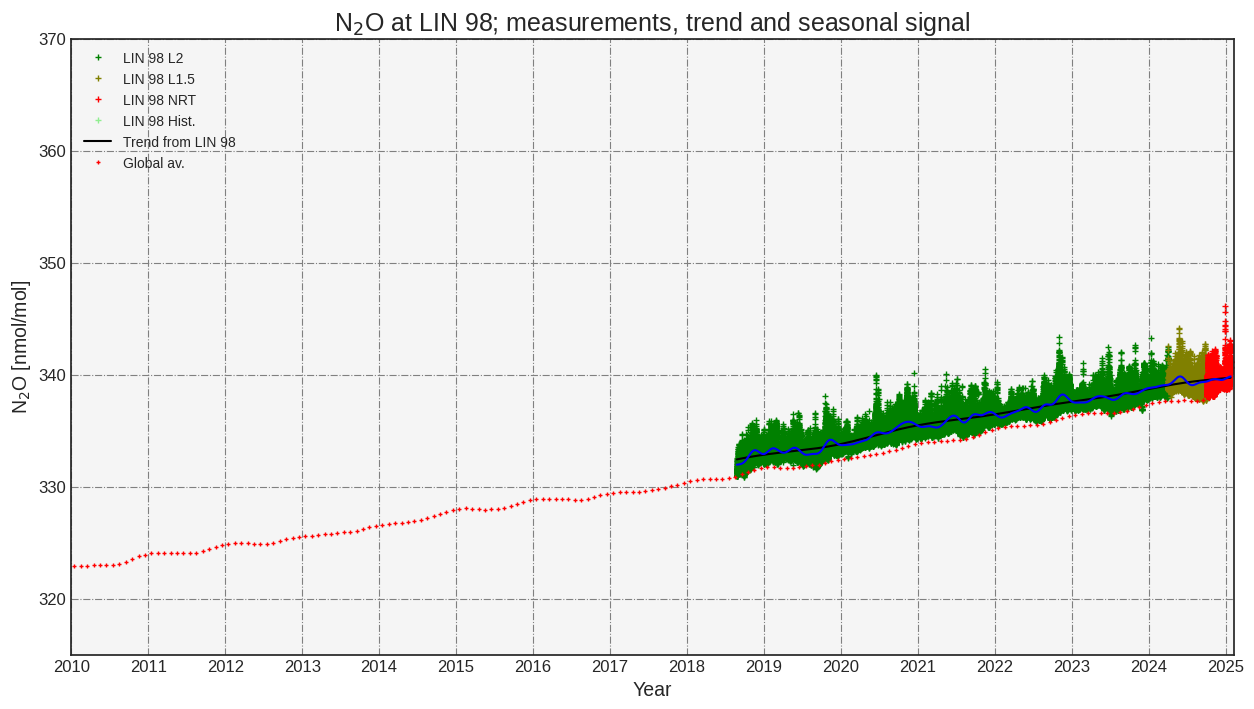

       fname            lname                orcid  \
0     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
5   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
1    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
5  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

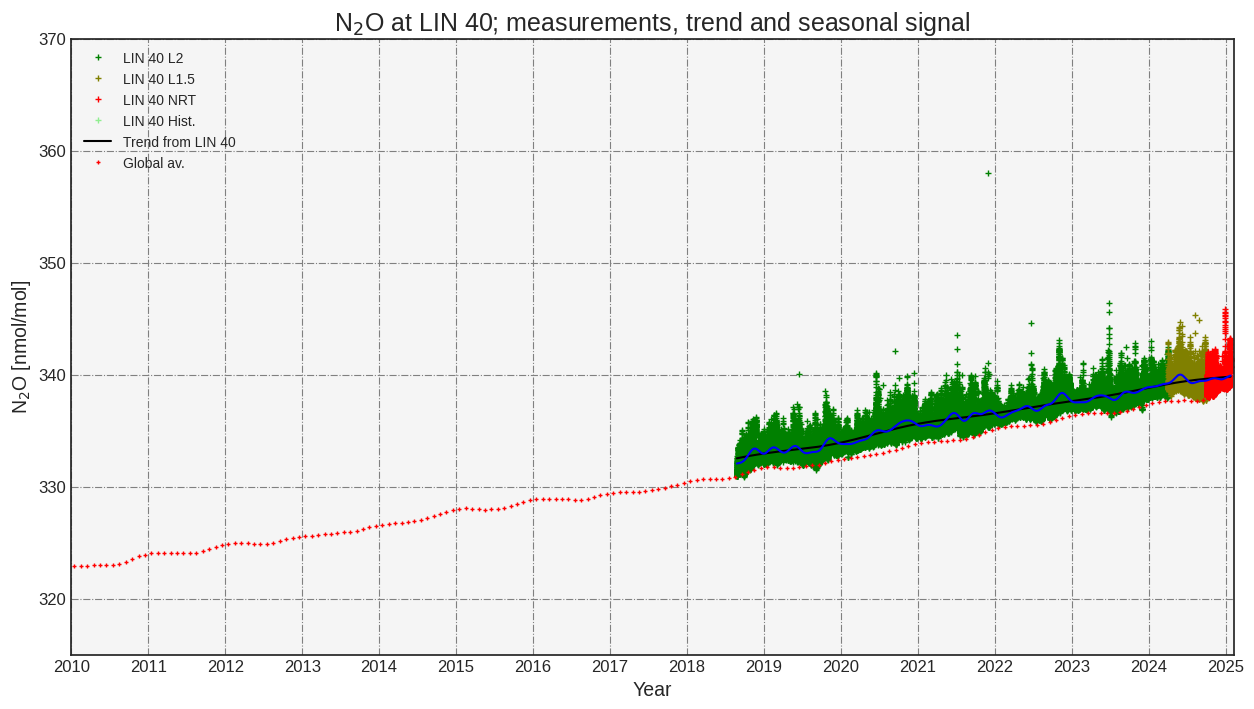

       fname            lname                orcid  \
0     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
5   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
1    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
5  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

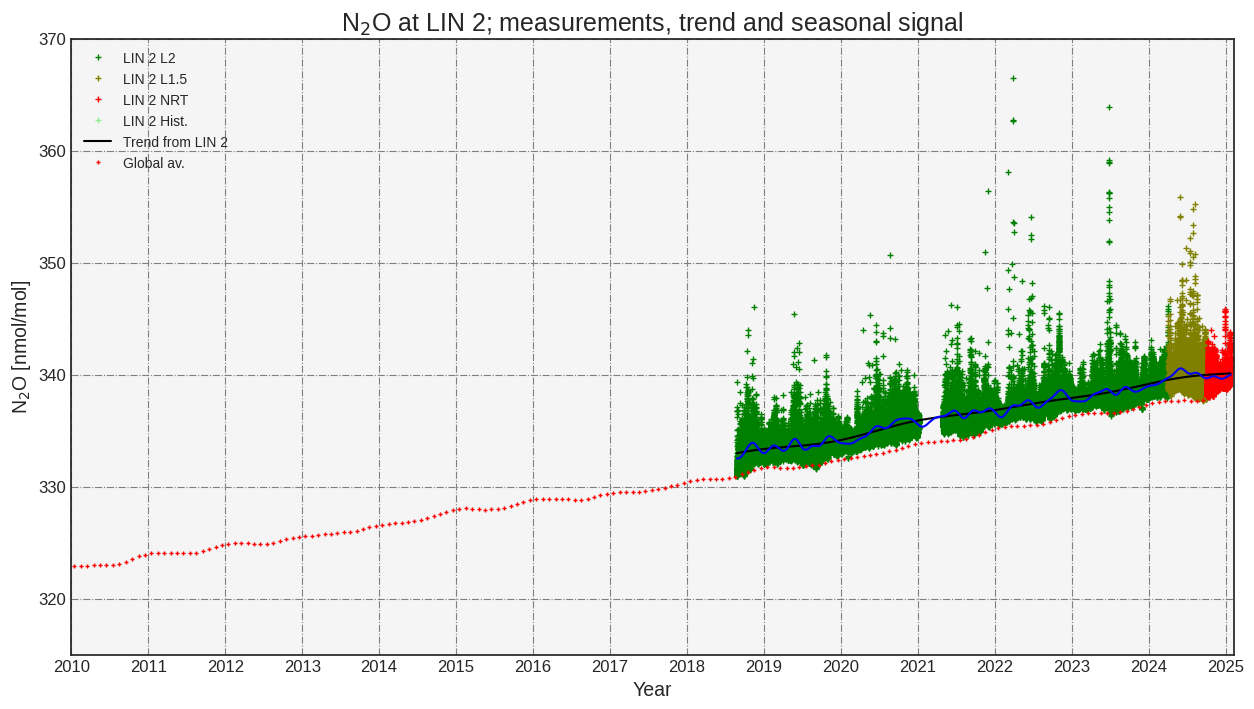

       fname            lname                orcid  \
0     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
5   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
1    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
5  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

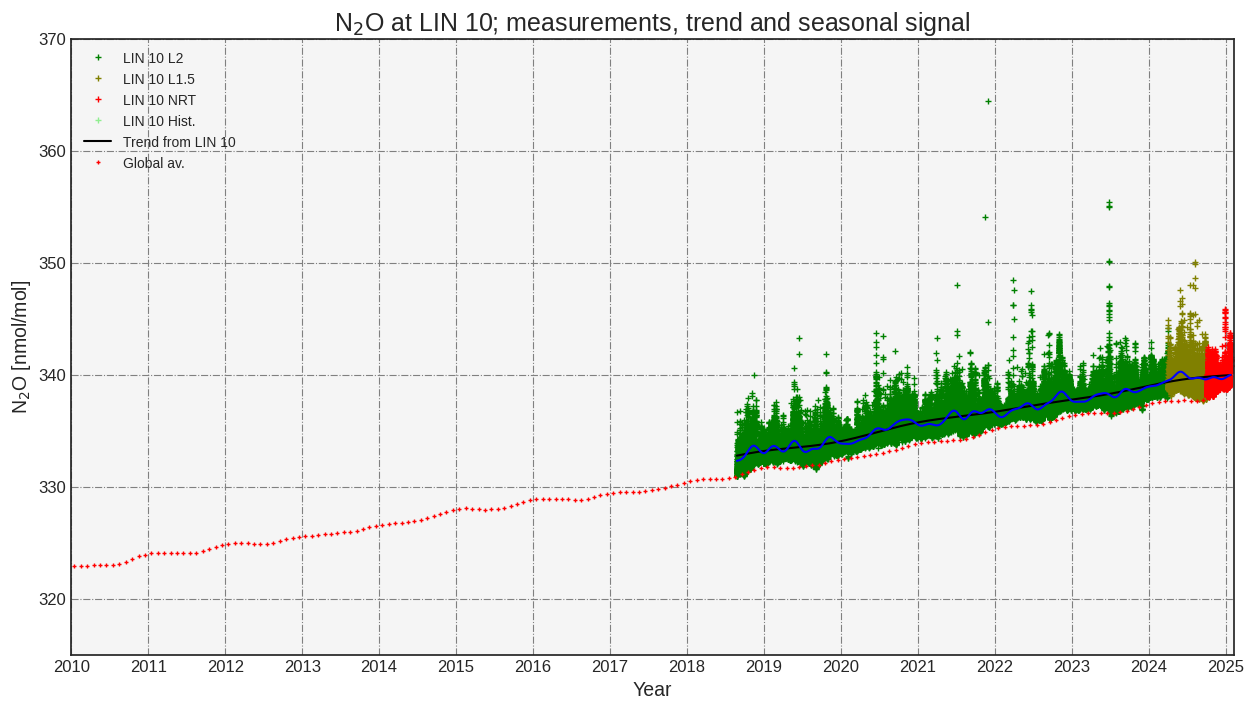

       fname            lname                orcid  \
0     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
6    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
5   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
1    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
6  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
5  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

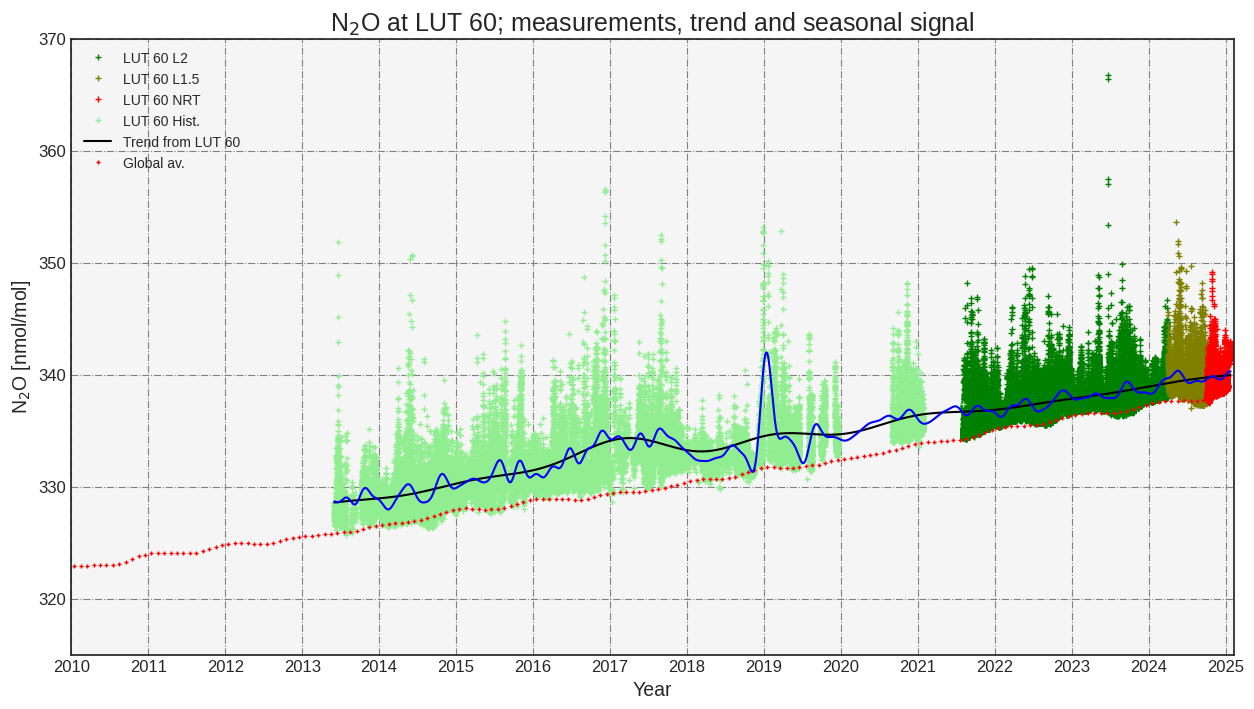

    fname     lname                orcid  \
1  Huilin      Chen  0000-0002-1573-6673   
0    Bert  Scheeren  0000-0001-6333-8402   

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Huilin...    70.0   
0  http://meta.icos-cp.eu/resources/people/Bert_S...    70.0   

                  start                   end  wght  
1  2018-08-13T11:00:00Z  2023-09-30T00:00:00Z    30  
0  2018-08-13T11:00:00Z                  None    30  
Done writing  ./data/n2o/nc/n2o_lut_surface-insitu_44_allvalid.nc
Done saving  ./data/n2o/txt/n2o_lut_surface-insitu_44_allvalid.txt
Done saving  ./data/n2o/nc/n2o_lut_surface-insitu_44_allvalid.json
MHD
MLH
NOR
OHP
OPE
OPE  Height: 50.0  Class: 1  NrFiles: 4
http://meta.icos-cp.eu/resources/cpmeta/atcN2oNrtGrowingDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22Spcin9O35Tne0WWvfAyJTFvX%22%5D
hit cache for  ./cache/ICOS_ATC_NRT_OPE_2024-04-01_2025-01-22_50.0_967_N2O.zip
http://meta.icos-cp.e

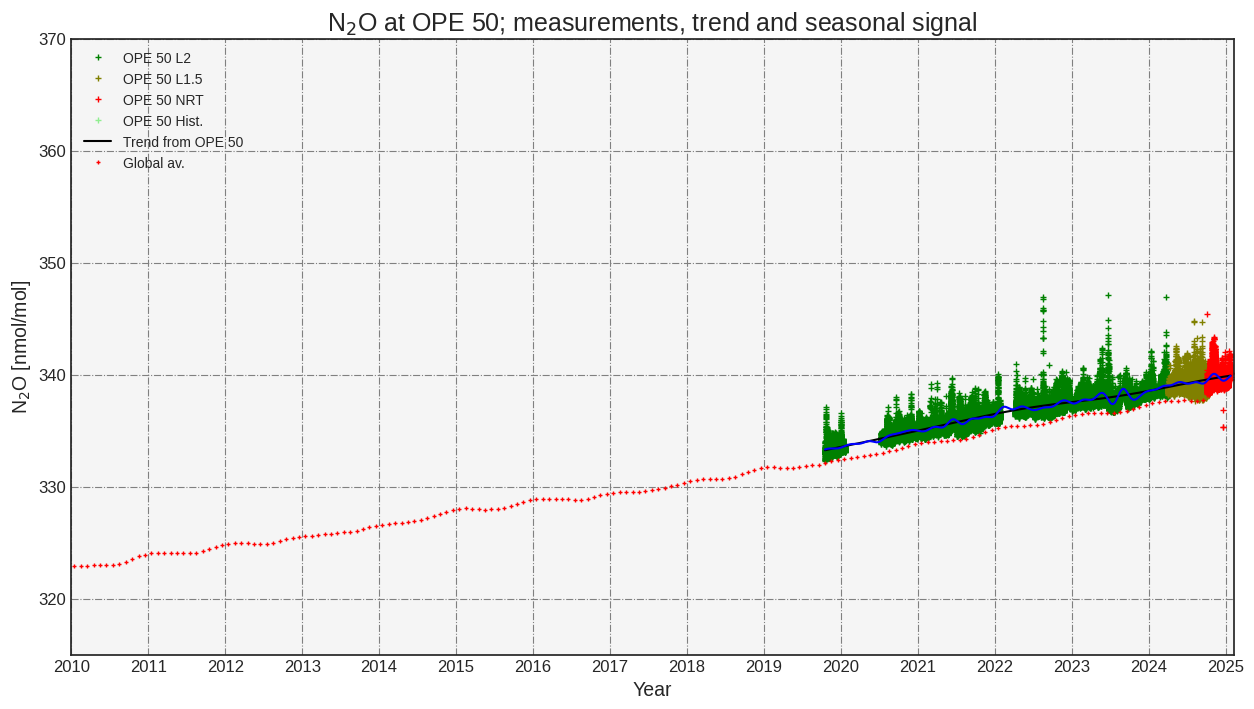

       fname     lname                orcid  \
5     Michel   Ramonet  0000-0003-1157-1186   
1  Sébastien     Conil  0000-0001-6767-821X   
3       Marc  Delmotte  0000-0003-3805-818X   
4    Olivier   Laurent  0000-0002-2029-6262   
6     Morgan     Lopez  0000-0003-1725-3410   
0      Julie     Helle                        
2    Laurent  Langrene                        

                                                 uri weight  \
5  http://meta.icos-cp.eu/resources/people/Michel...    100   
1  http://meta.icos-cp.eu/resources/people/S%C3%A...     70   
3  http://meta.icos-cp.eu/resources/people/Marc_D...     20   
4  http://meta.icos-cp.eu/resources/people/Olivie...     20   
6  http://meta.icos-cp.eu/resources/people/Morgan...     20   
0  http://meta.icos-cp.eu/resources/people/Julie_...      0   
2  http://meta.icos-cp.eu/resources/people/Lauren...      0   

                  start                   end  wght  
5  2016-03-16T00:00:00Z                  None     0  
1  2016-08

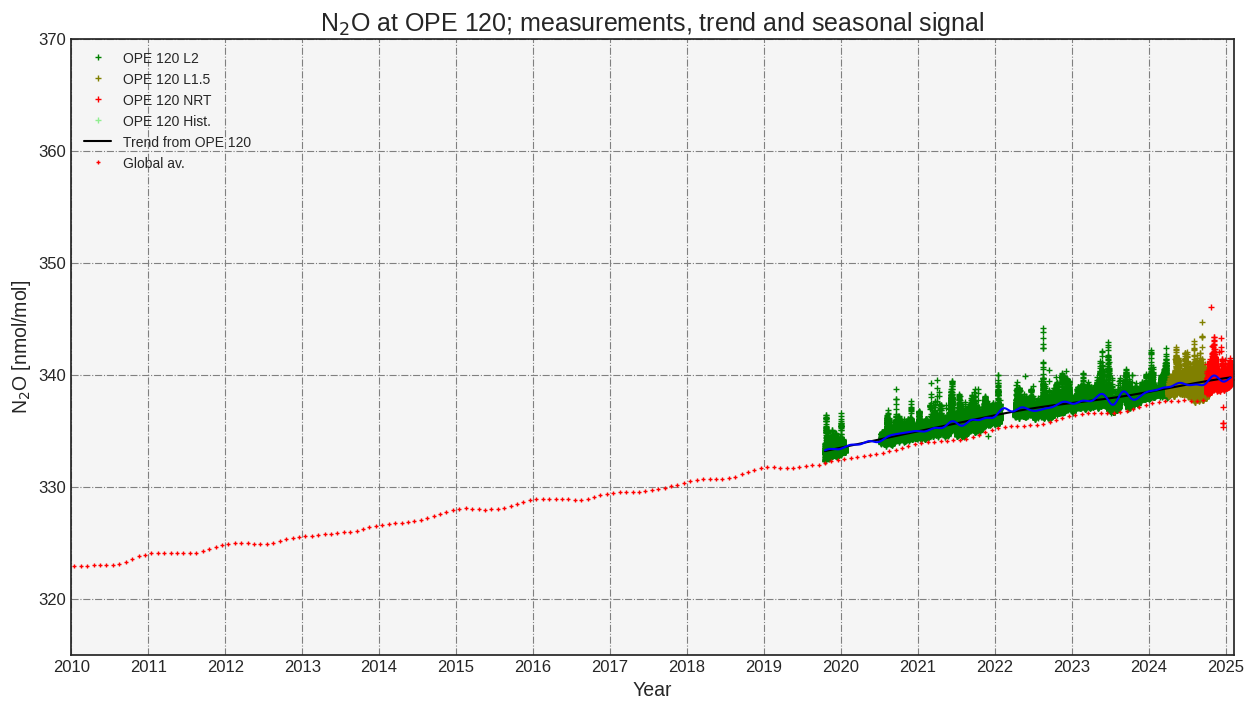

       fname     lname                orcid  \
5     Michel   Ramonet  0000-0003-1157-1186   
1  Sébastien     Conil  0000-0001-6767-821X   
3       Marc  Delmotte  0000-0003-3805-818X   
4    Olivier   Laurent  0000-0002-2029-6262   
6     Morgan     Lopez  0000-0003-1725-3410   
0      Julie     Helle                        
2    Laurent  Langrene                        

                                                 uri weight  \
5  http://meta.icos-cp.eu/resources/people/Michel...    100   
1  http://meta.icos-cp.eu/resources/people/S%C3%A...     70   
3  http://meta.icos-cp.eu/resources/people/Marc_D...     20   
4  http://meta.icos-cp.eu/resources/people/Olivie...     20   
6  http://meta.icos-cp.eu/resources/people/Morgan...     20   
0  http://meta.icos-cp.eu/resources/people/Julie_...      0   
2  http://meta.icos-cp.eu/resources/people/Lauren...      0   

                  start                   end  wght  
5  2016-03-16T00:00:00Z                  None     0  
1  2016-08

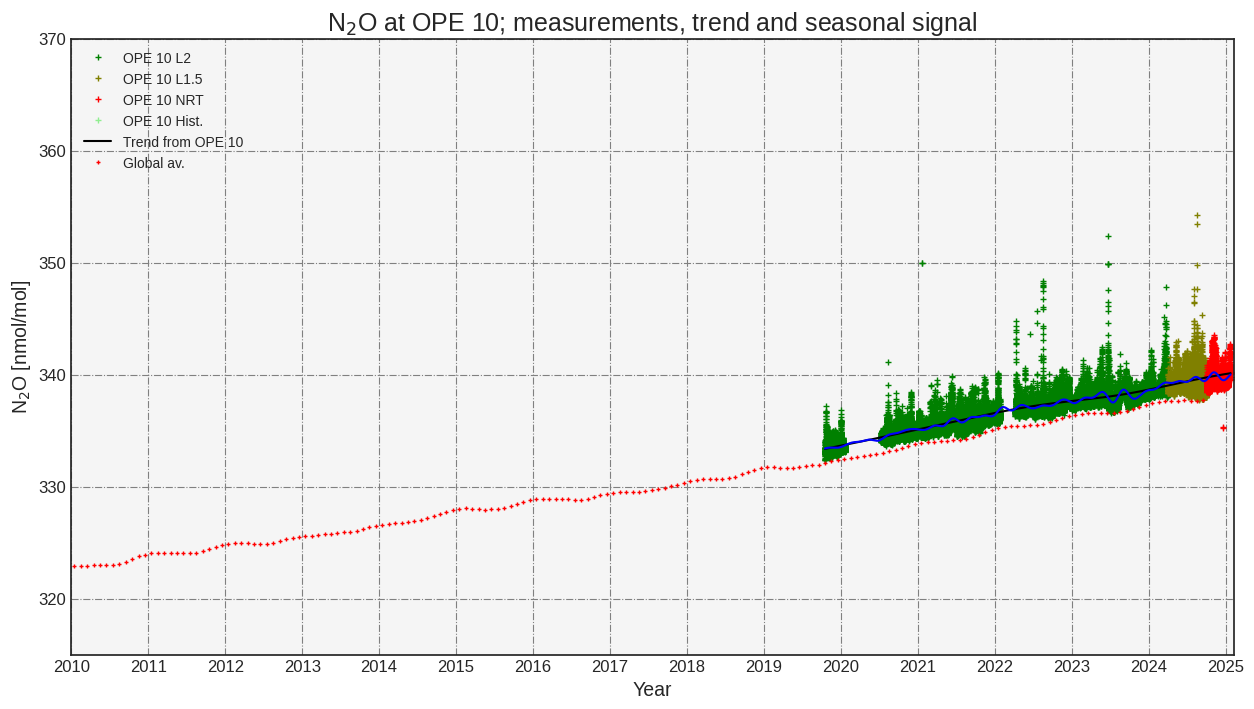

       fname     lname                orcid  \
5     Michel   Ramonet  0000-0003-1157-1186   
1  Sébastien     Conil  0000-0001-6767-821X   
3       Marc  Delmotte  0000-0003-3805-818X   
4    Olivier   Laurent  0000-0002-2029-6262   
6     Morgan     Lopez  0000-0003-1725-3410   
0      Julie     Helle                        
2    Laurent  Langrene                        

                                                 uri weight  \
5  http://meta.icos-cp.eu/resources/people/Michel...    100   
1  http://meta.icos-cp.eu/resources/people/S%C3%A...     70   
3  http://meta.icos-cp.eu/resources/people/Marc_D...     20   
4  http://meta.icos-cp.eu/resources/people/Olivie...     20   
6  http://meta.icos-cp.eu/resources/people/Morgan...     20   
0  http://meta.icos-cp.eu/resources/people/Julie_...      0   
2  http://meta.icos-cp.eu/resources/people/Lauren...      0   

                  start                   end  wght  
5  2016-03-16T00:00:00Z                  None     0  
1  2016-08

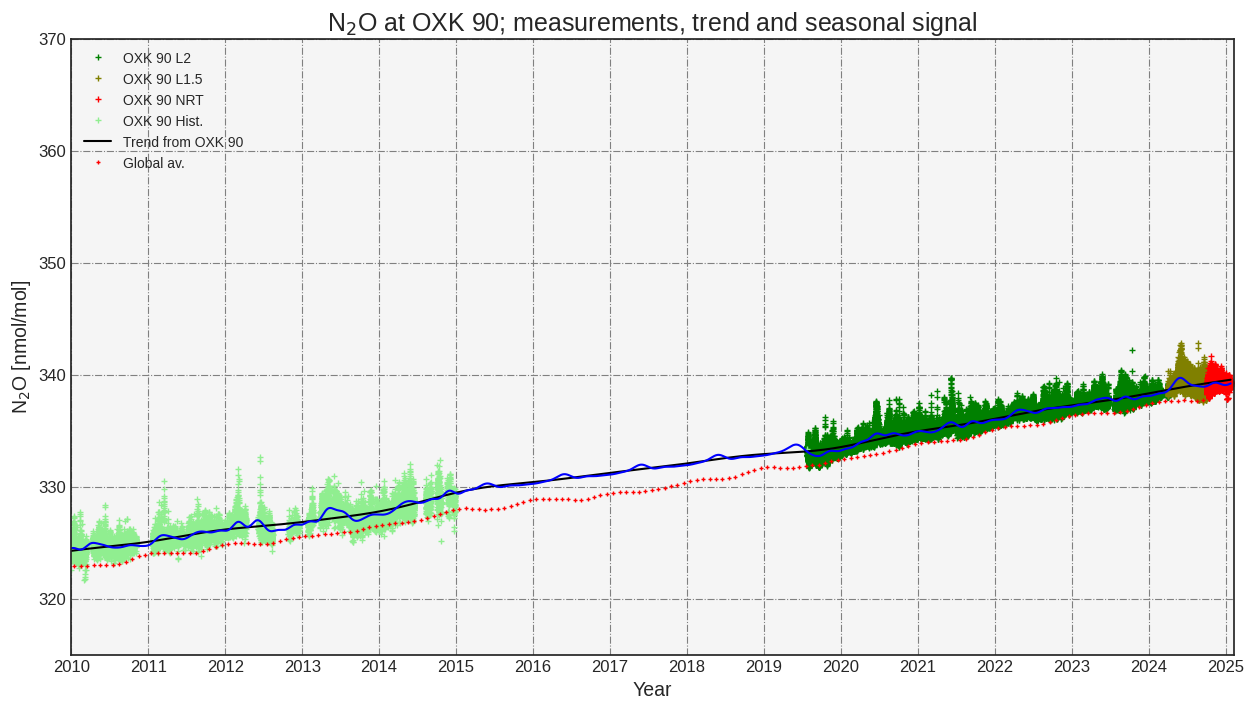

       fname            lname                orcid  \
1     Dagmar         Kubistin  0000-0002-5467-9309   
0  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
0  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
5  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

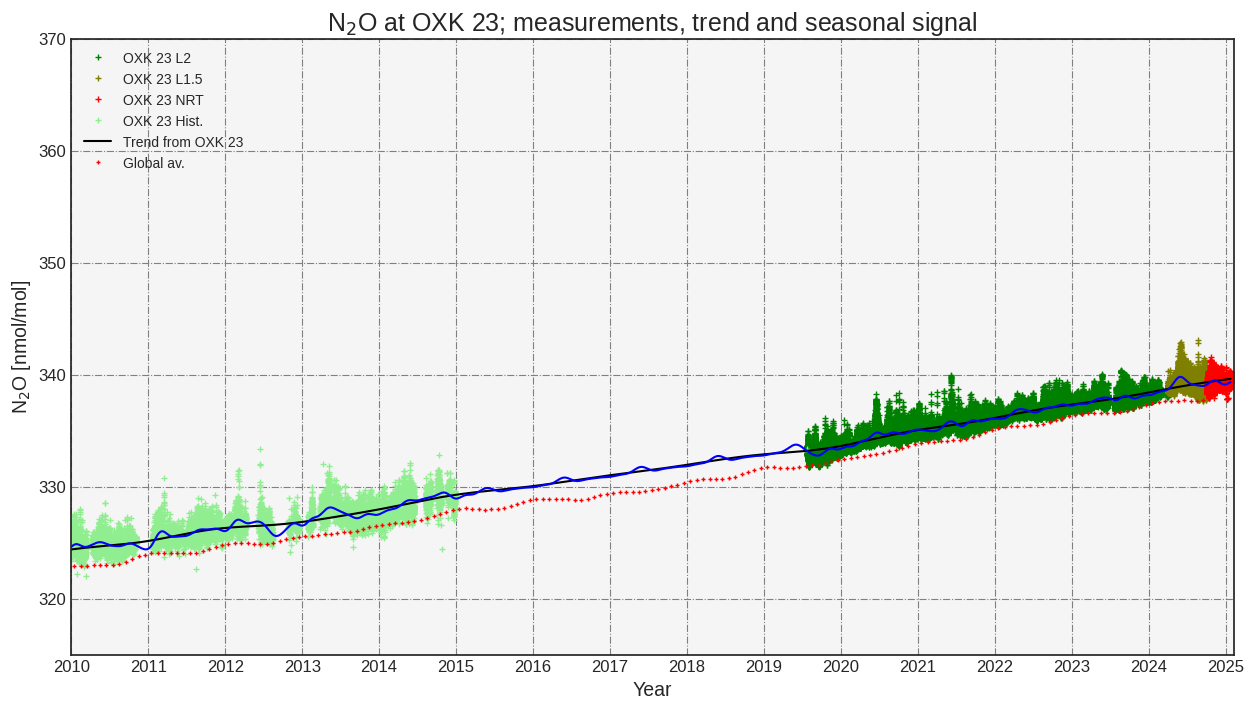

       fname            lname                orcid  \
1     Dagmar         Kubistin  0000-0002-5467-9309   
0  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
0  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
5  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

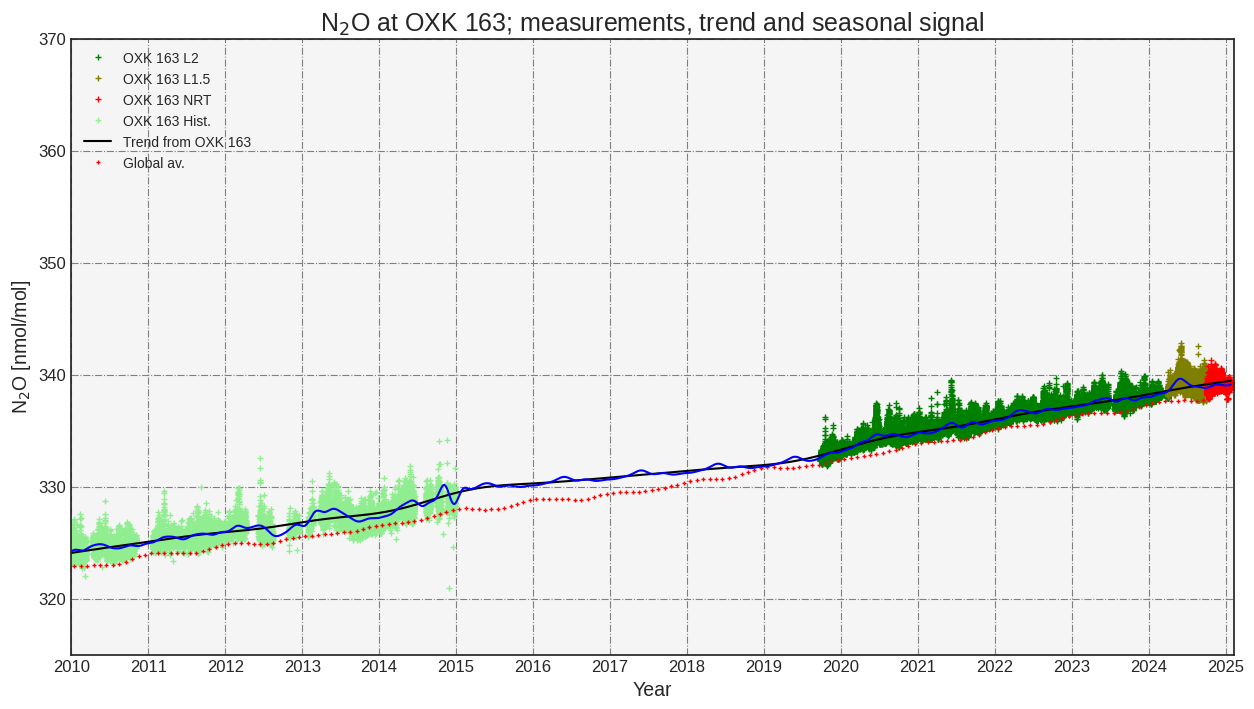

       fname            lname                orcid  \
1     Dagmar         Kubistin  0000-0002-5467-9309   
0  Christian      Plaß-Dülmer                        
5    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
4    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
0  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
5  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

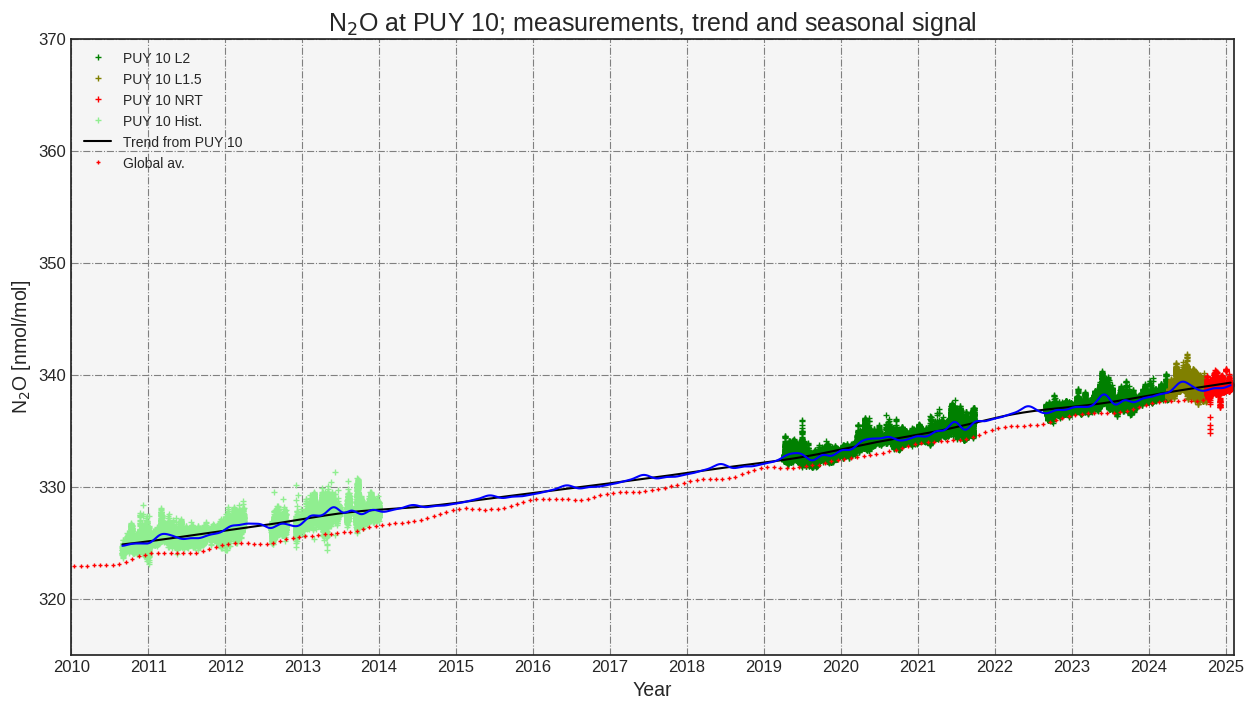

       fname      lname                orcid  \
1    Aurélie     Colomb  0000-0002-2595-3911   
4     Michel    Ramonet  0000-0003-1157-1186   
3    Camille  Yver-Kwok  0000-0002-2181-2863   
0       Marc   Delmotte  0000-0003-3805-818X   
5     Morgan      Lopez  0000-0003-1725-3410   
2  Jean-Marc     Pichon                        

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Aur%C3...   100.0   
4  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
3  http://meta.icos-cp.eu/resources/people/Camill...    70.0   
0  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
5  http://meta.icos-cp.eu/resources/people/Morgan...    20.0   
2  http://meta.icos-cp.eu/resources/people/Jean-M...    20.0   

                  start                   end  wght  
1  2016-05-01T00:00:00Z                  None     0  
4  2016-03-16T00:00:00Z                  None     0  
3  2016-05-01T00:00:00Z                  None    30 

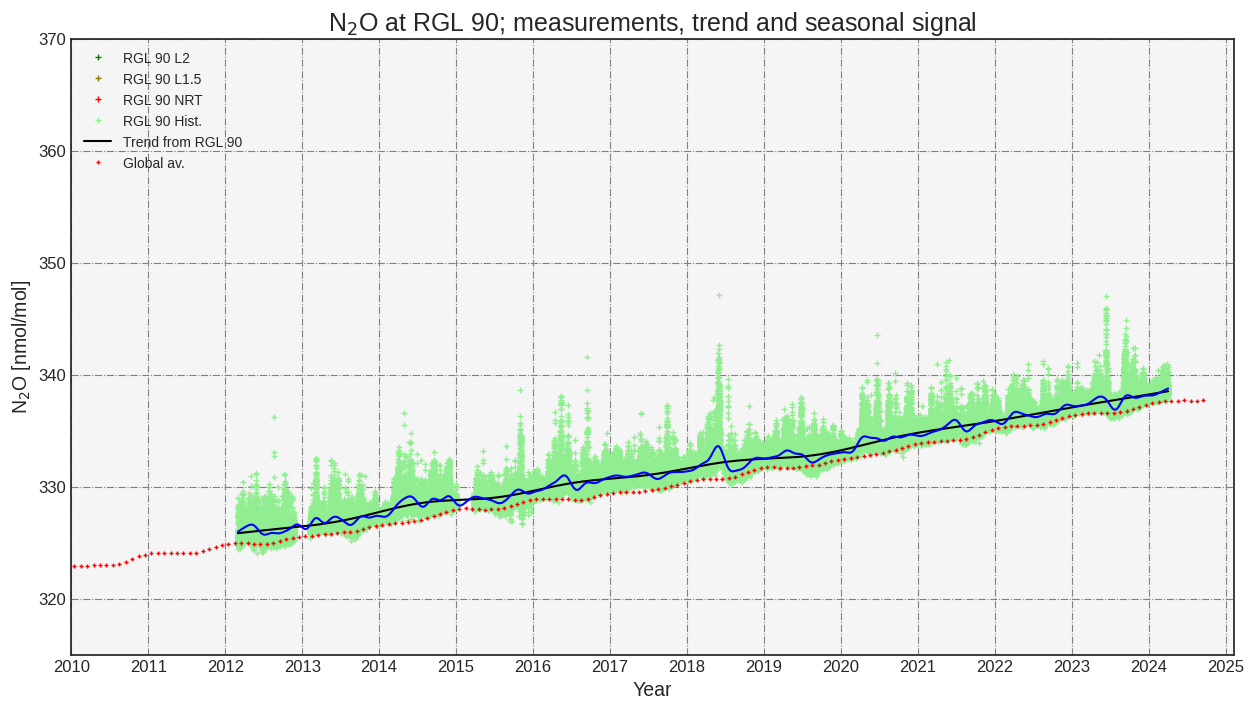

    fname      lname                orcid  \
1   Simon  O'Doherty  0000-0002-4051-6760   
0  Joseph       Pitt  0000-0002-8660-5136   
2  Kieran    Stanley  0000-0003-3388-0932   

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Simon_...   100.0   
0  http://meta.icos-cp.eu/resources/people/Joseph...    70.0   
2  http://meta.icos-cp.eu/resources/people/Kieran...    20.0   

                  start   end  wght  
1  2022-07-01T00:00:00Z  None     0  
0  2021-08-09T00:00:00Z  None    30  
2  2022-05-01T00:00:00Z  None    80  
Done writing  ./data/n2o/nc/n2o_rgl_surface-insitu_160_allvalid.nc
Done saving  ./data/n2o/txt/n2o_rgl_surface-insitu_160_allvalid.txt
Done saving  ./data/n2o/nc/n2o_rgl_surface-insitu_160_allvalid.json
ROC
RUN
SAC
SAC  Height: 60.0  Class: 1  NrFiles: 4
http://meta.icos-cp.eu/resources/cpmeta/atcN2oNrtGrowingDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22kWAInuCVPtXocZcqN1tvvBlH%22%5D
hit

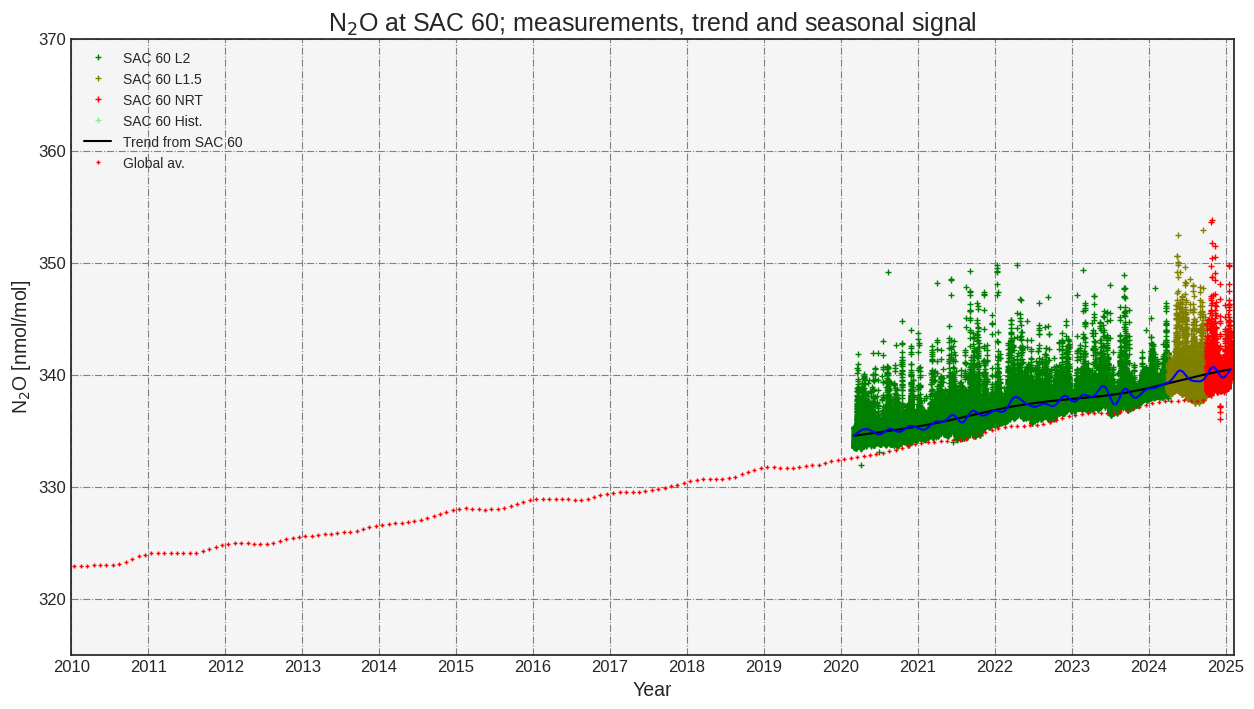

          fname          lname                orcid  \
3        Michel        Ramonet  0000-0003-1157-1186   
4        Victor          Kazan                        
8          Marc       Delmotte  0000-0003-3805-818X   
7        Morgan          Lopez  0000-0003-1725-3410   
5         Marta  Fuente-Lastra                        
2       Virgile       Legendre                        
6         Dylan          Lopez                        
1         Zineb       Mandrick                        
9  Louis-Jeremy      Rigouleau                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
4  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
8  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
7  http://meta.icos-cp.eu/resources/people/Morgan...    20.0   
5  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
2  http://meta.icos-cp.eu/resources/people/Virgil...     0.0   
6

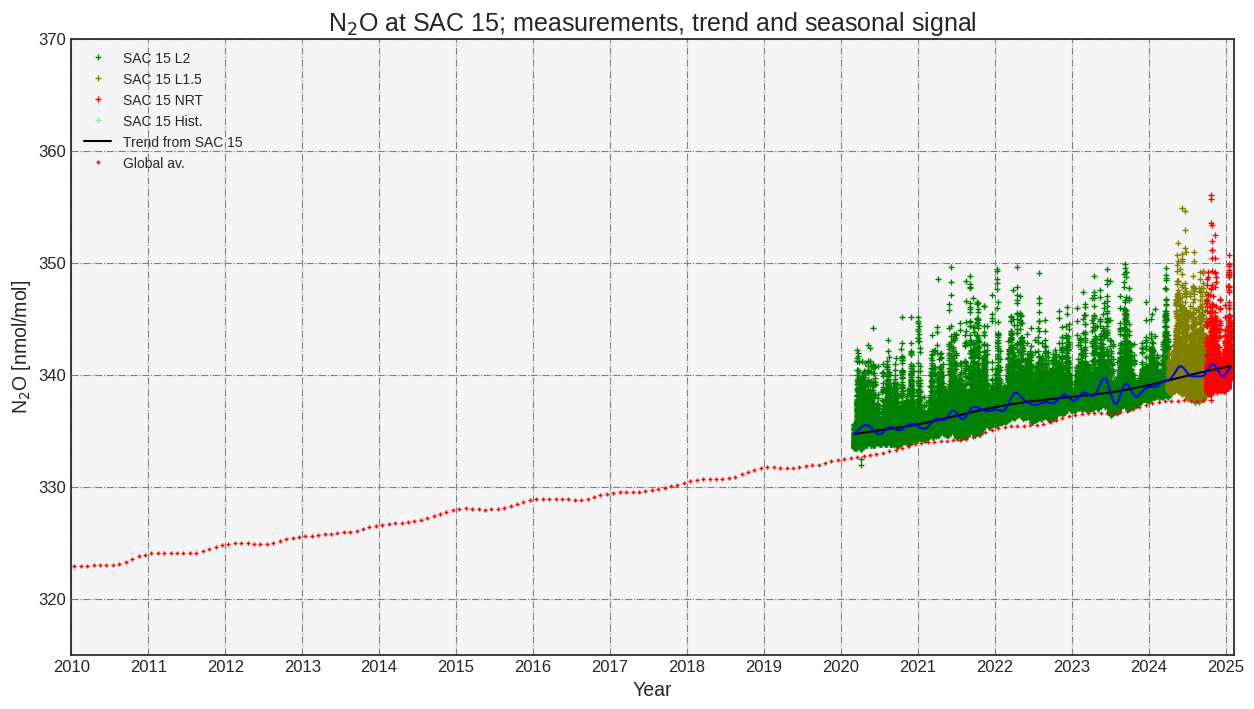

          fname          lname                orcid  \
3        Michel        Ramonet  0000-0003-1157-1186   
4        Victor          Kazan                        
8          Marc       Delmotte  0000-0003-3805-818X   
7        Morgan          Lopez  0000-0003-1725-3410   
5         Marta  Fuente-Lastra                        
2       Virgile       Legendre                        
6         Dylan          Lopez                        
1         Zineb       Mandrick                        
9  Louis-Jeremy      Rigouleau                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
4  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
8  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
7  http://meta.icos-cp.eu/resources/people/Morgan...    20.0   
5  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
2  http://meta.icos-cp.eu/resources/people/Virgil...     0.0   
6

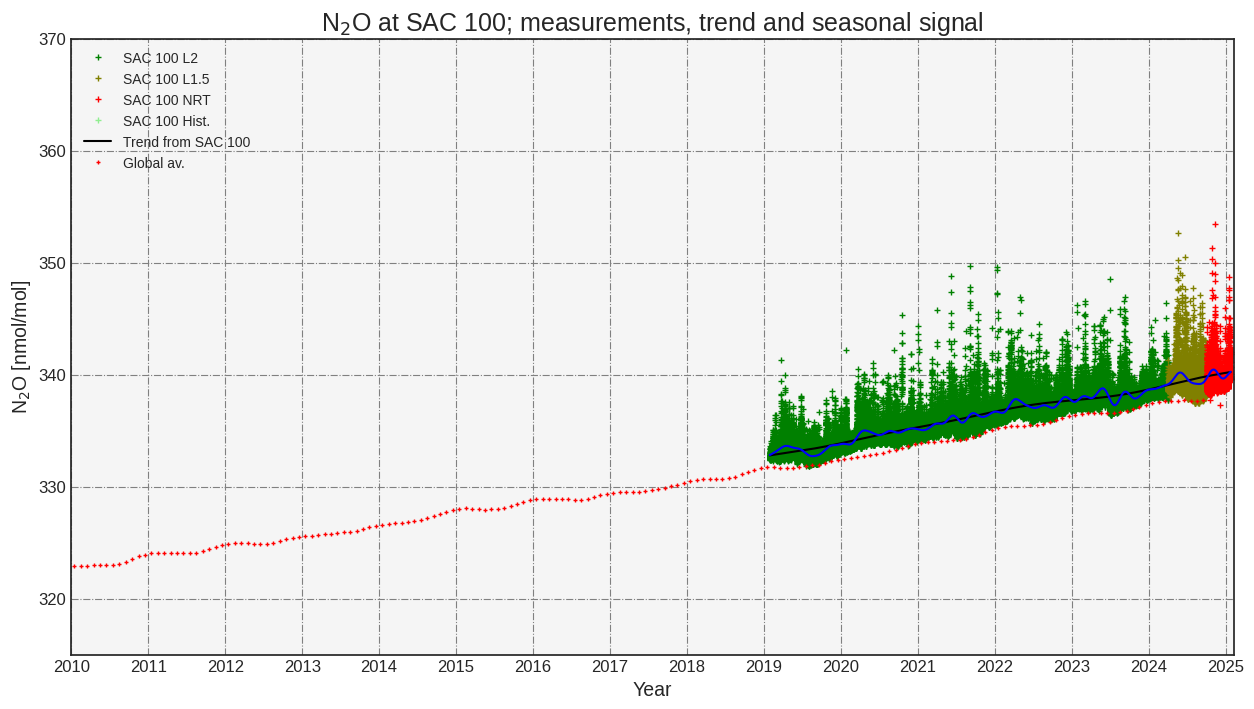

          fname          lname                orcid  \
3        Michel        Ramonet  0000-0003-1157-1186   
4        Victor          Kazan                        
8          Marc       Delmotte  0000-0003-3805-818X   
7        Morgan          Lopez  0000-0003-1725-3410   
5         Marta  Fuente-Lastra                        
2       Virgile       Legendre                        
6         Dylan          Lopez                        
1         Zineb       Mandrick                        
9  Louis-Jeremy      Rigouleau                        

                                                 uri  weight  \
3  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
4  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
8  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
7  http://meta.icos-cp.eu/resources/people/Morgan...    20.0   
5  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
2  http://meta.icos-cp.eu/resources/people/Virgil...     0.0   
6

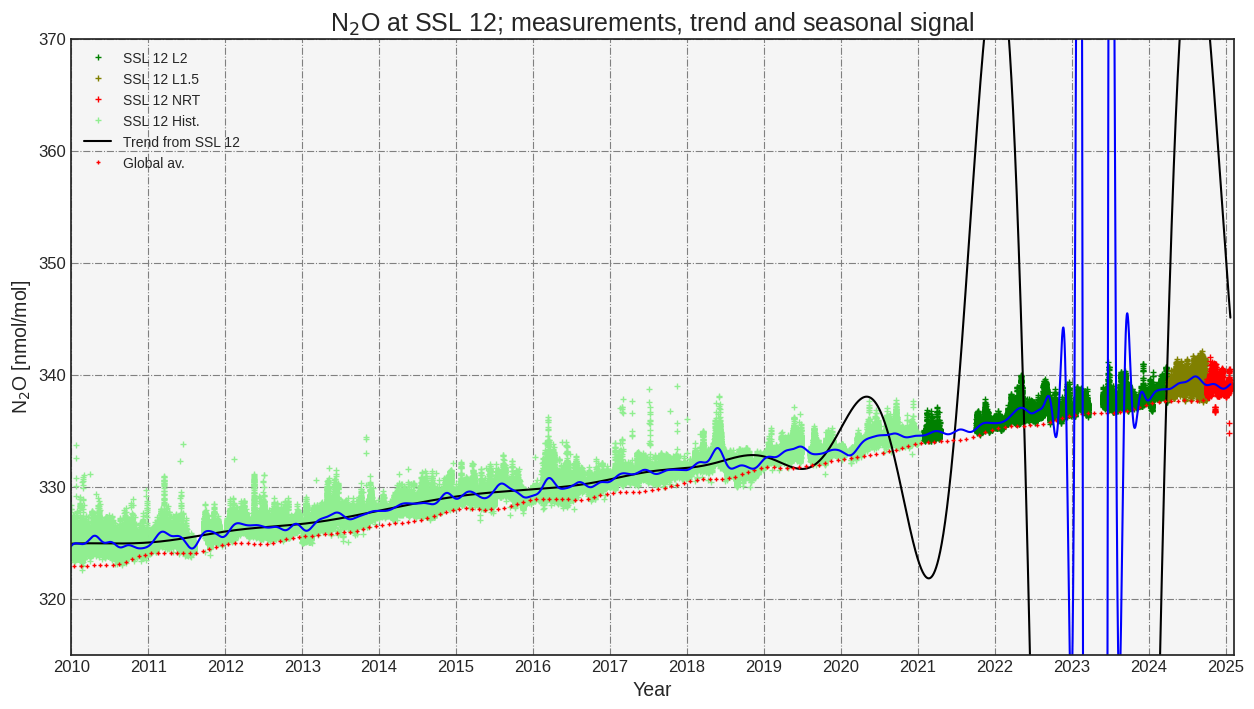

     fname      lname                orcid  \
1  Martina    Schmidt  0000-0002-4648-769X   
2    Antje   Hoheisel                        
0    Frank  Meinhardt                        
3   Cédric     Couret  0000-0002-1874-9883   
4   Julian  Grossmann                        

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/Martin...   100.0   
2  http://meta.icos-cp.eu/resources/people/Antje_...    70.0   
0  http://meta.icos-cp.eu/resources/people/Frank_...    70.0   
3  http://meta.icos-cp.eu/resources/people/C%C3%A...     0.0   
4  http://meta.icos-cp.eu/resources/people/Julian...     0.0   

                  start   end  wght  
1  2021-01-01T00:00:00Z  None     0  
2  2021-09-29T00:00:00Z  None    30  
0  2021-01-01T00:00:00Z  None    30  
3  2023-08-08T00:00:00Z  None   100  
4                  None  None   100  
Done writing  ./data/n2o/nc/n2o_ssl_surface-insitu_23_allvalid.nc
Done saving  ./data/n2o/txt/n2o_ssl_surface-

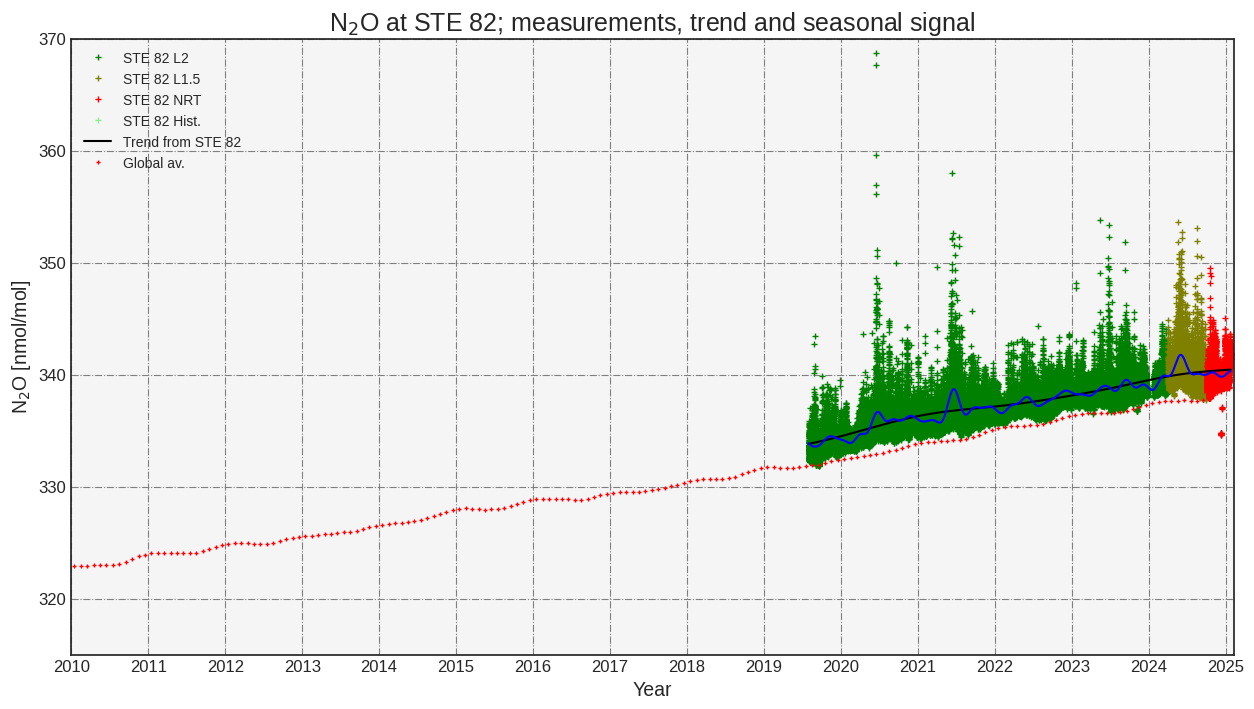

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
0    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
1   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
0  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
1  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

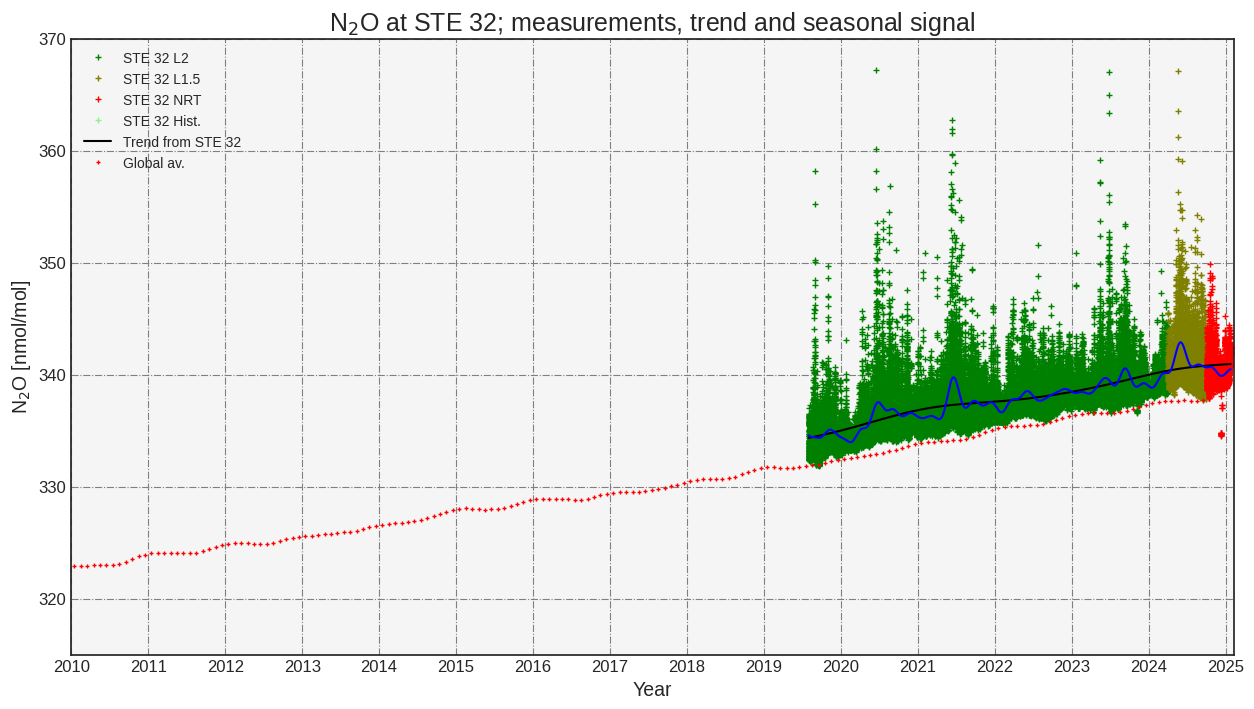

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
0    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
1   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
0  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
1  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

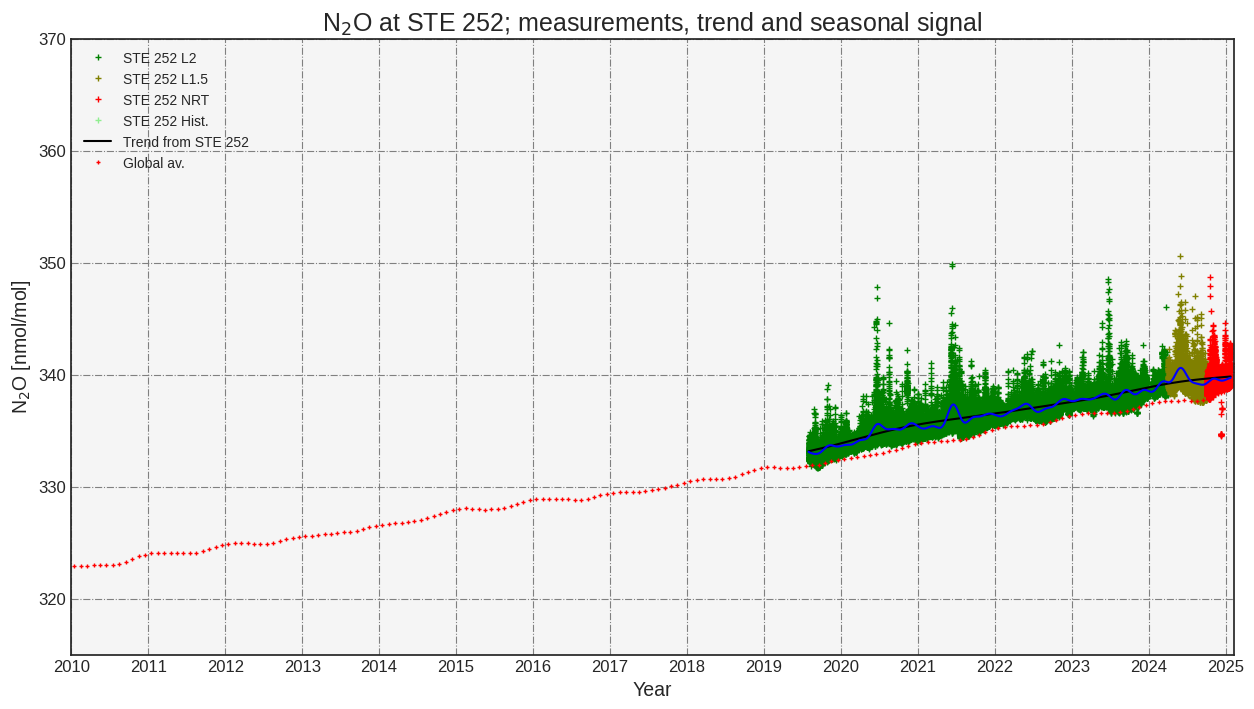

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
0    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
1   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
0  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
1  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

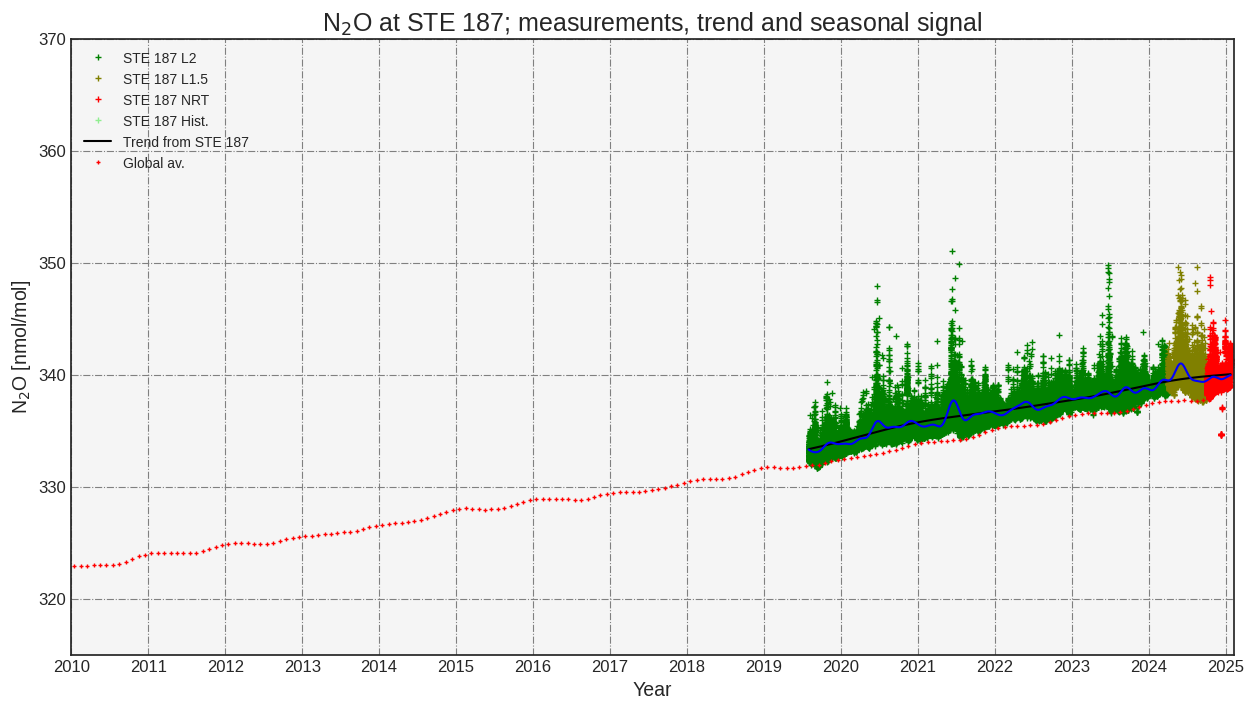

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
0    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
1   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
0  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
1  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

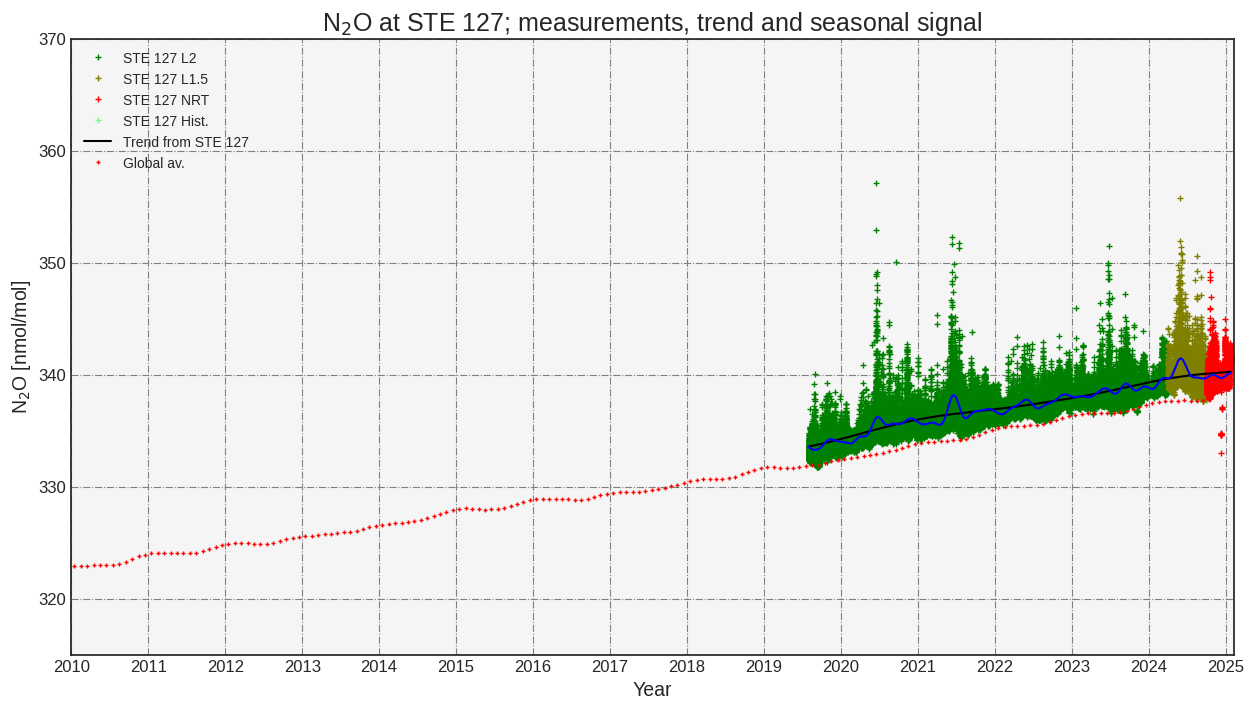

       fname            lname                orcid  \
6     Dagmar         Kubistin  0000-0002-5467-9309   
4  Christian      Plaß-Dülmer                        
0    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
1   Matthias         Lindauer  0000-0001-9274-8750   
3   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
5    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
6  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
4  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
0  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
1  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
3  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

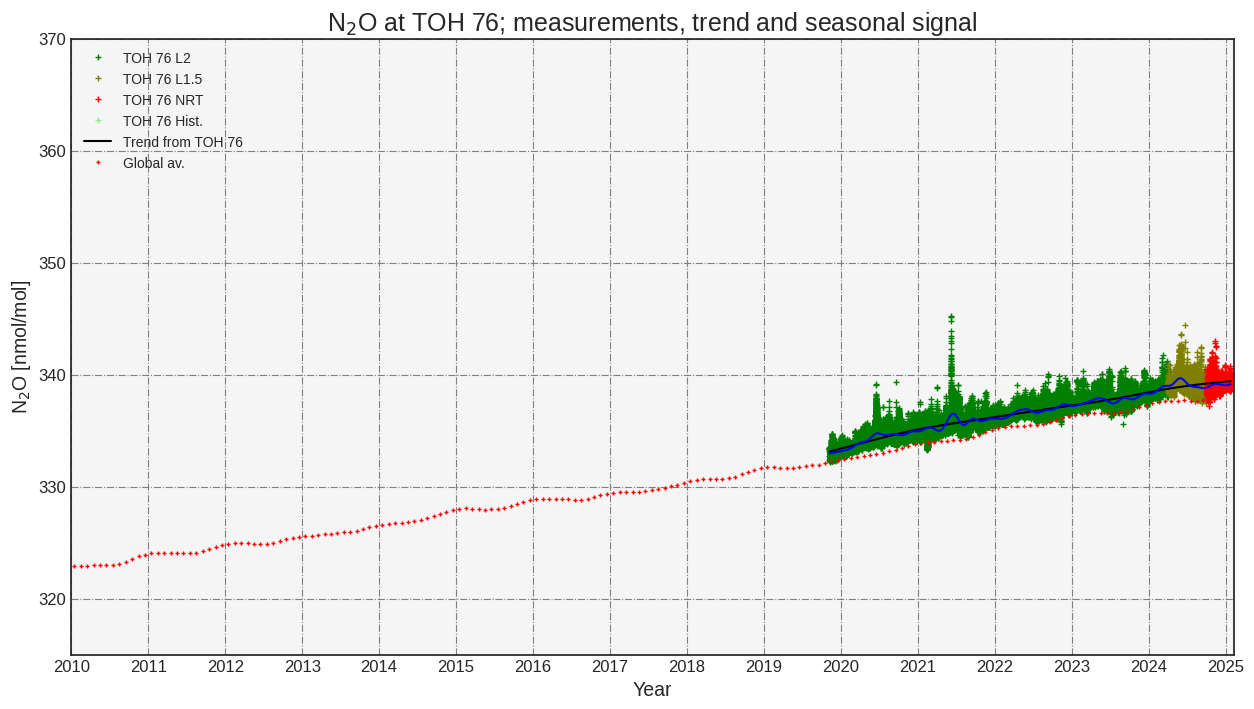

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
1  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
3    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
1  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

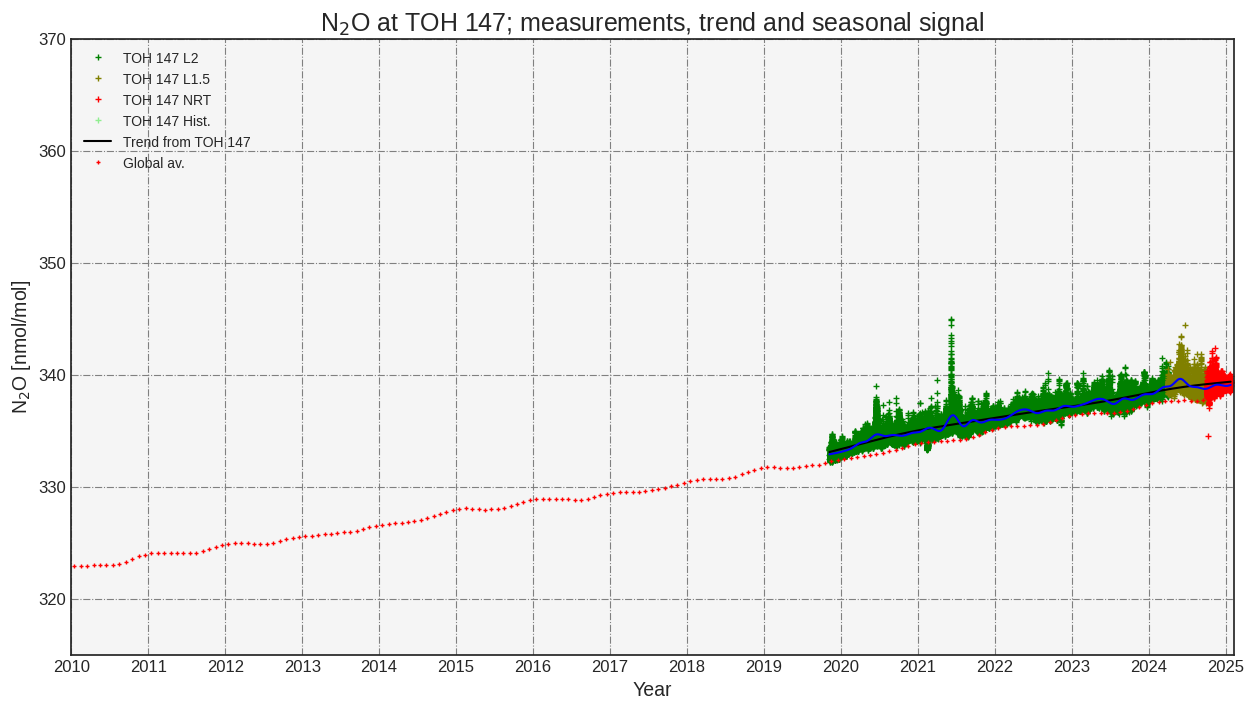

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
1  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
3    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
1  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

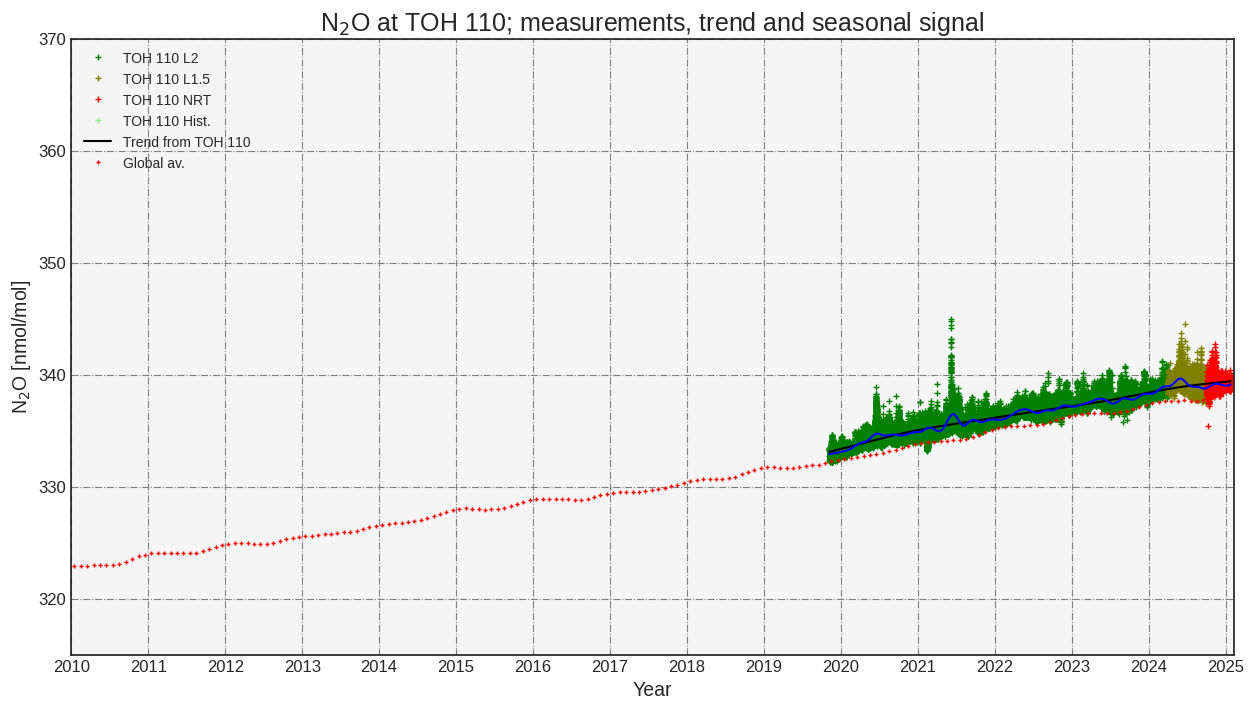

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
1  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
3    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
1  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

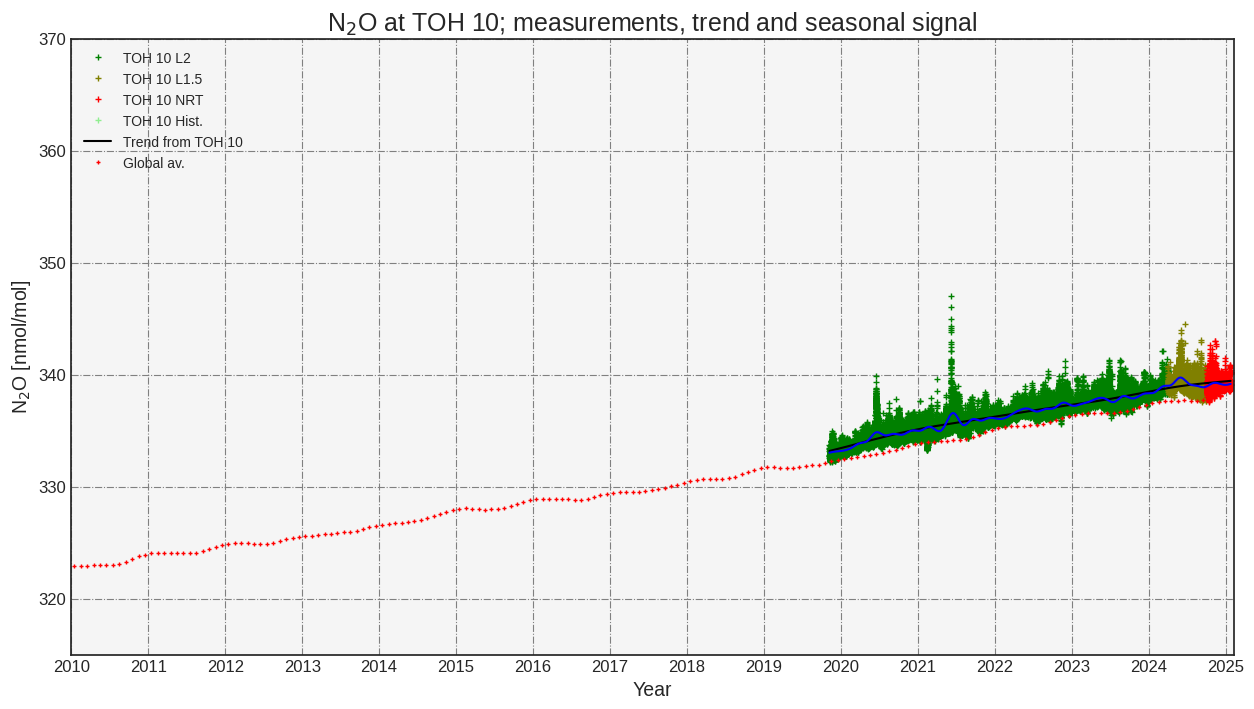

       fname            lname                orcid  \
5     Dagmar         Kubistin  0000-0002-5467-9309   
1  Christian      Plaß-Dülmer                        
4    Sabrina           Arnold  0000-0001-6797-1715   
7     Tobias           Kneuer  0000-0002-5621-3780   
6   Matthias         Lindauer  0000-0001-9274-8750   
0   Jennifer  Müller-Williams  0000-0002-4840-7729   
2     Marcus       Schumacher                        
3    Dietmar         Weyrauch                        
8      Elena        Zwerschke                        

                                                 uri  weight  \
5  http://meta.icos-cp.eu/resources/people/Dagmar...   100.0   
1  http://meta.icos-cp.eu/resources/people/Christ...   100.0   
4  http://meta.icos-cp.eu/resources/people/Sabrin...    70.0   
7  http://meta.icos-cp.eu/resources/people/Tobias...    70.0   
6  http://meta.icos-cp.eu/resources/people/Matthi...    70.0   
0  http://meta.icos-cp.eu/resources/people/Jennif...    70.0   
2  http://m

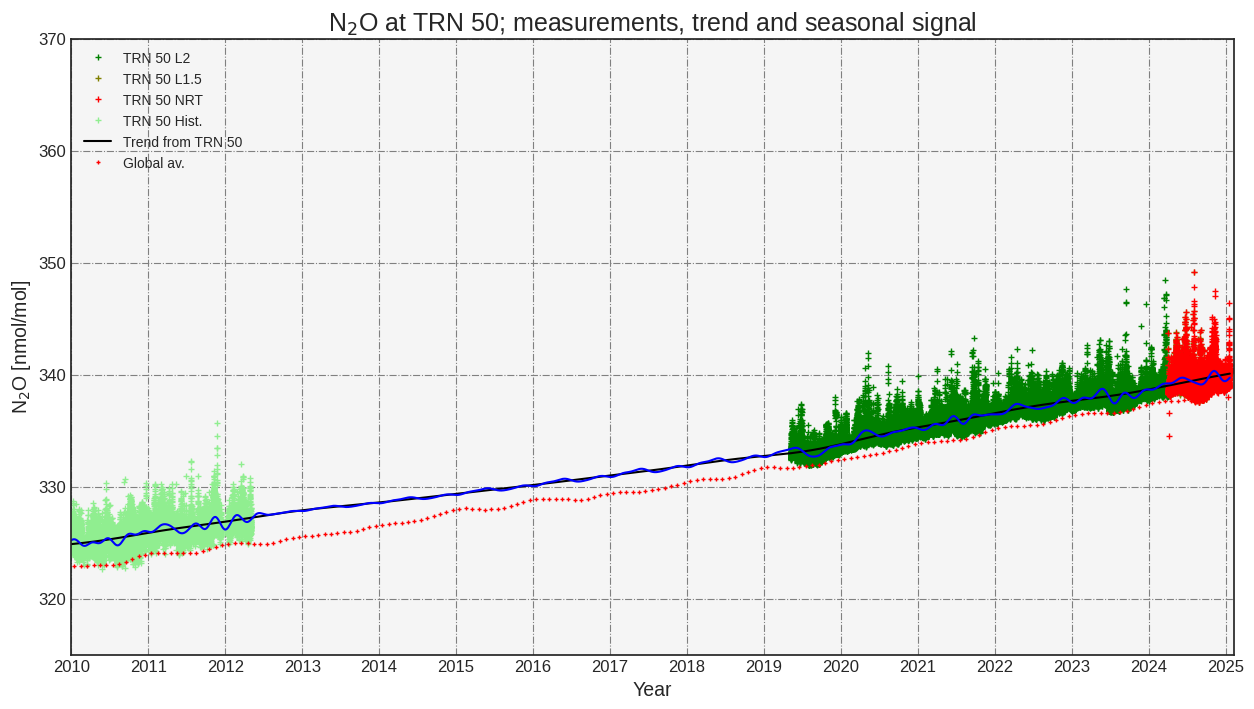

     fname          lname                orcid  \
0   Michel        Ramonet  0000-0003-1157-1186   
1   Morgan          Lopez  0000-0003-1725-3410   
9   Victor          Kazan                        
7     Marc       Delmotte  0000-0003-3805-818X   
4    Marta  Fuente-Lastra                        
8    Dylan          Lopez                        
6  Camille      Yver-Kwok  0000-0002-2181-2863   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
1  http://meta.icos-cp.eu/resources/people/Morgan...    70.0   
9  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
7  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
4  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
8  http://meta.icos-cp.eu/resources/people/Dylan_...     0.0   
6  http://meta.icos-cp.eu/resources/people/Camill...     0.0   

                  start                   end  wght  
0  2016-03-16T00:00:00Z         

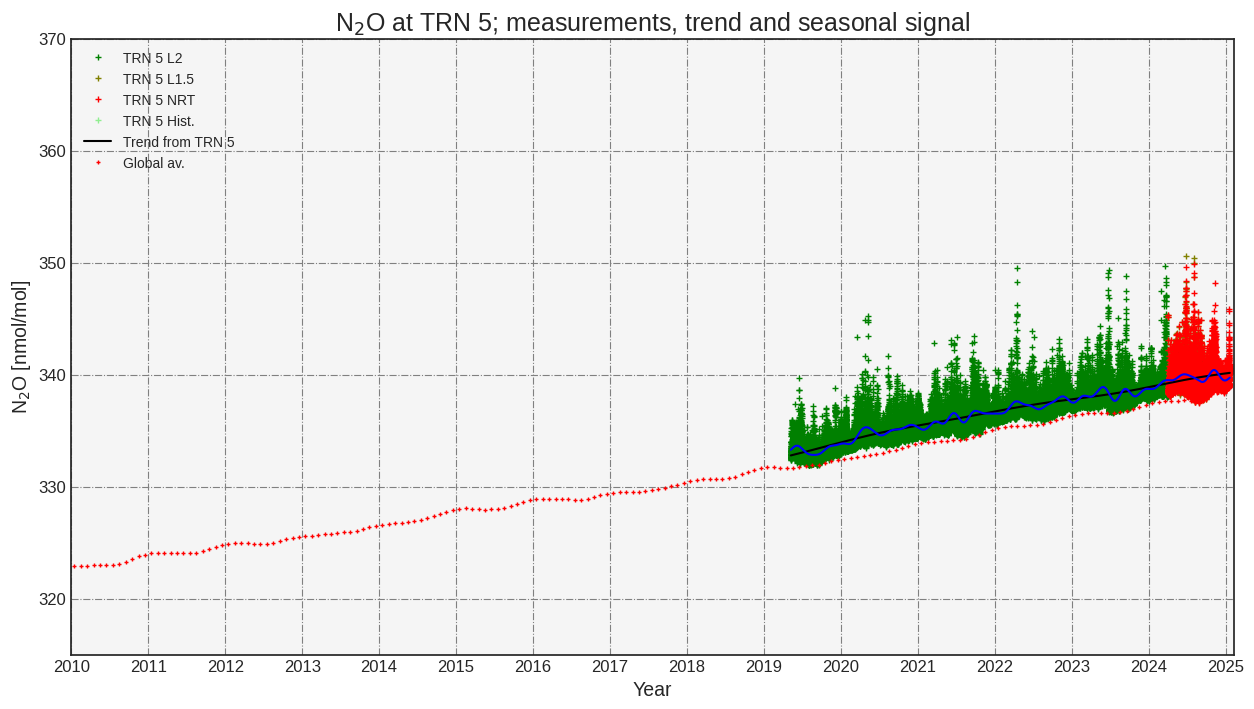

     fname          lname                orcid  \
0   Michel        Ramonet  0000-0003-1157-1186   
1   Morgan          Lopez  0000-0003-1725-3410   
9   Victor          Kazan                        
7     Marc       Delmotte  0000-0003-3805-818X   
4    Marta  Fuente-Lastra                        
8    Dylan          Lopez                        
6  Camille      Yver-Kwok  0000-0002-2181-2863   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
1  http://meta.icos-cp.eu/resources/people/Morgan...    70.0   
9  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
7  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
4  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
8  http://meta.icos-cp.eu/resources/people/Dylan_...     0.0   
6  http://meta.icos-cp.eu/resources/people/Camill...     0.0   

                  start                   end  wght  
0  2016-03-16T00:00:00Z         

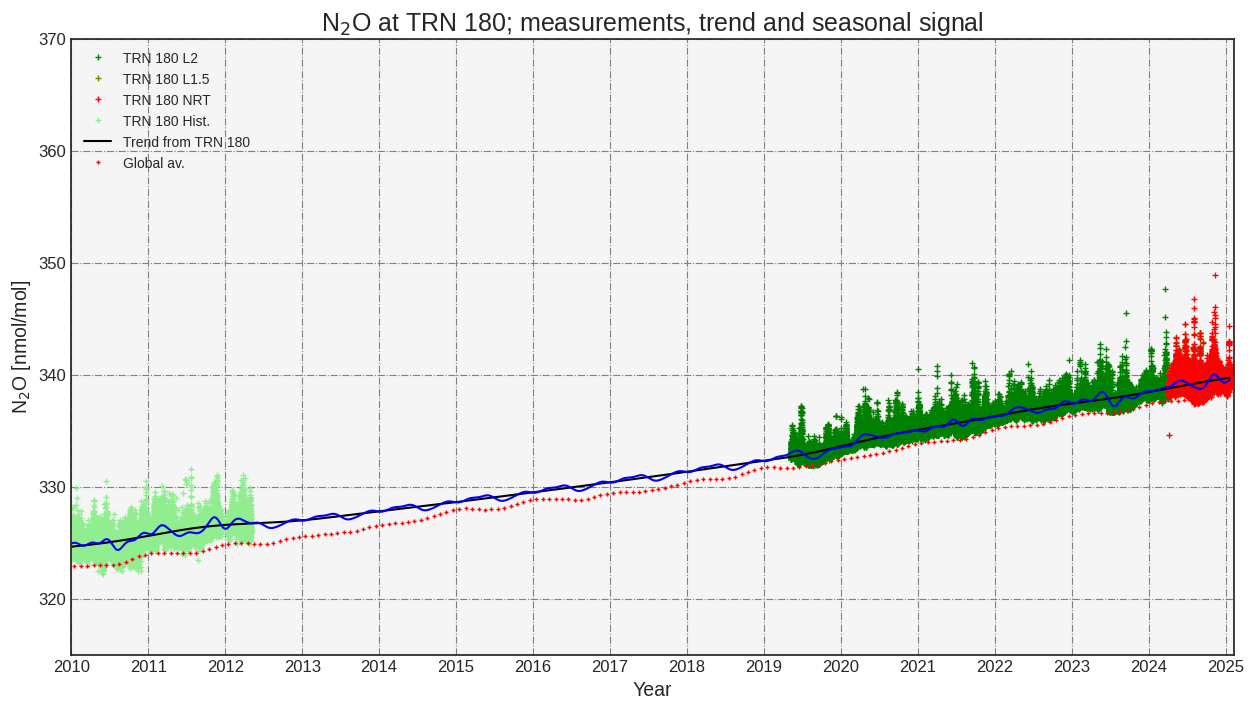

     fname          lname                orcid  \
0   Michel        Ramonet  0000-0003-1157-1186   
1   Morgan          Lopez  0000-0003-1725-3410   
9   Victor          Kazan                        
7     Marc       Delmotte  0000-0003-3805-818X   
4    Marta  Fuente-Lastra                        
8    Dylan          Lopez                        
6  Camille      Yver-Kwok  0000-0002-2181-2863   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
1  http://meta.icos-cp.eu/resources/people/Morgan...    70.0   
9  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
7  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
4  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
8  http://meta.icos-cp.eu/resources/people/Dylan_...     0.0   
6  http://meta.icos-cp.eu/resources/people/Camill...     0.0   

                  start                   end  wght  
0  2016-03-16T00:00:00Z         

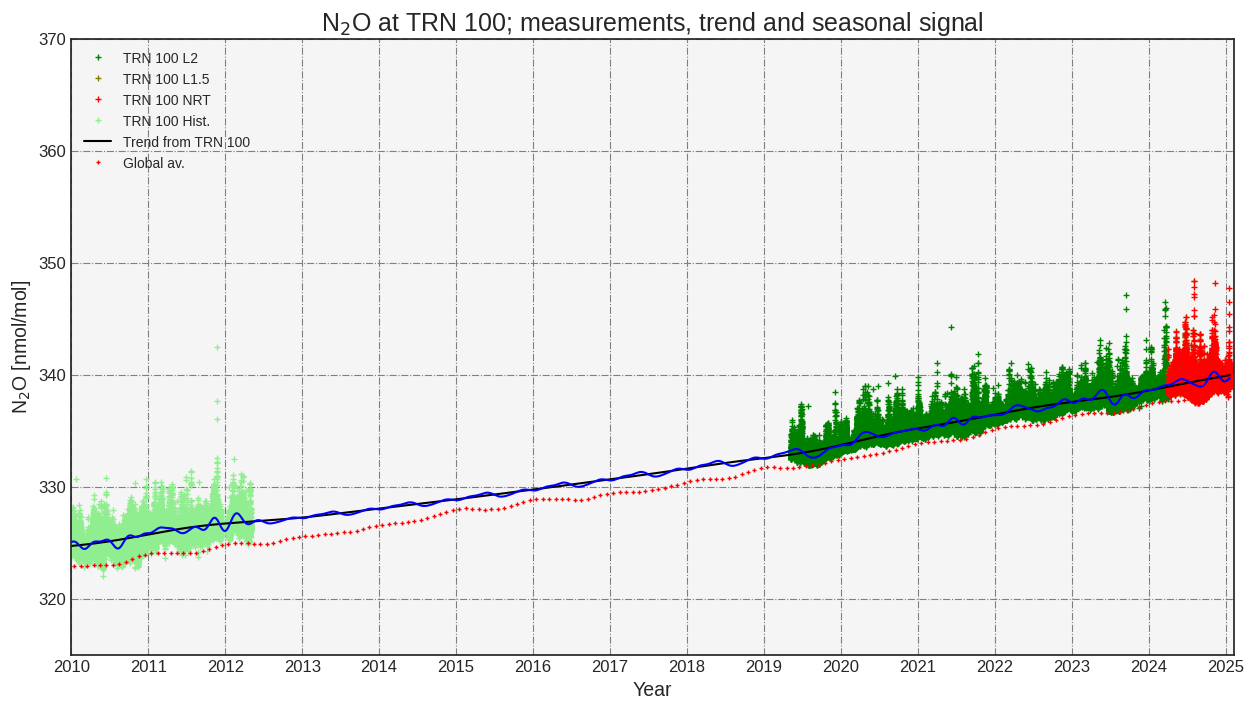

     fname          lname                orcid  \
0   Michel        Ramonet  0000-0003-1157-1186   
1   Morgan          Lopez  0000-0003-1725-3410   
9   Victor          Kazan                        
7     Marc       Delmotte  0000-0003-3805-818X   
4    Marta  Fuente-Lastra                        
8    Dylan          Lopez                        
6  Camille      Yver-Kwok  0000-0002-2181-2863   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Michel...   100.0   
1  http://meta.icos-cp.eu/resources/people/Morgan...    70.0   
9  http://meta.icos-cp.eu/resources/people/Victor...    40.0   
7  http://meta.icos-cp.eu/resources/people/Marc_D...    20.0   
4  http://meta.icos-cp.eu/resources/people/Marta_...     0.0   
8  http://meta.icos-cp.eu/resources/people/Dylan_...     0.0   
6  http://meta.icos-cp.eu/resources/people/Camill...     0.0   

                  start                   end  wght  
0  2016-03-16T00:00:00Z         

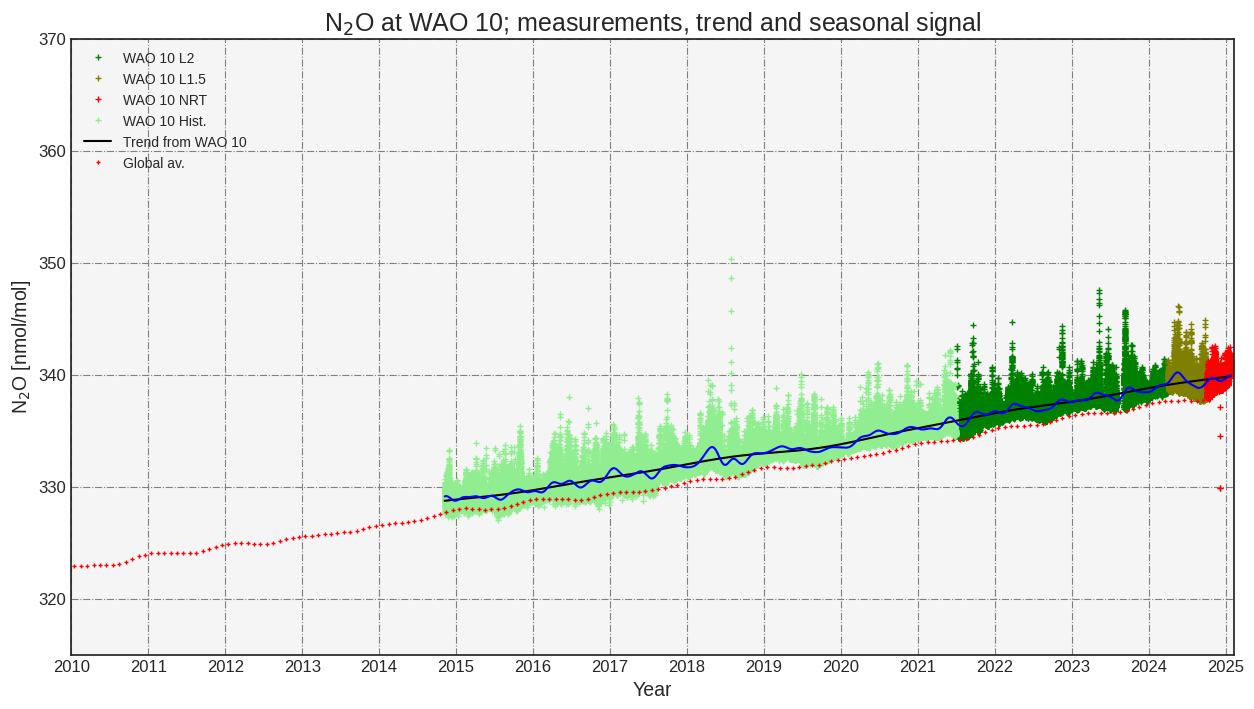

    fname    lname                orcid  \
0   Grant  Forster  0000-0003-1783-9307   
1  Andrew  Manning  0000-0001-6952-7773   

                                                 uri  weight  \
0  http://meta.icos-cp.eu/resources/people/Grant_...    70.0   
1  http://meta.icos-cp.eu/resources/people/Andrew...    70.0   

                  start   end  wght  
0  1900-01-01T00:00:00Z  None    30  
1                  None  None    30  
Done writing  ./data/n2o/nc/n2o_wao_surface-insitu_13_allvalid.nc
Done saving  ./data/n2o/txt/n2o_wao_surface-insitu_13_allvalid.txt
Done saving  ./data/n2o/nc/n2o_wao_surface-insitu_13_allvalid.json
WES
XIC
ZEP
ZOT
ZSF
ZSF  Height: 3.0  Class: 2  NrFiles: 4
http://meta.icos-cp.eu/resources/cpmeta/atcN2oNrtGrowingDataObject
url: https://data.icos-cp.eu/licence_accept?ids=%5B%22zcNduG56KSZvny7lqF3YMO9E%22%5D
hit cache for  ./cache/ICOS_ATC_NRT_ZSF_2024-04-01_2025-01-22_3.0_1482_N2O.zip
http://meta.icos-cp.eu/resources/cpmeta/atcGHGFastTrackNRTDataObject
url:

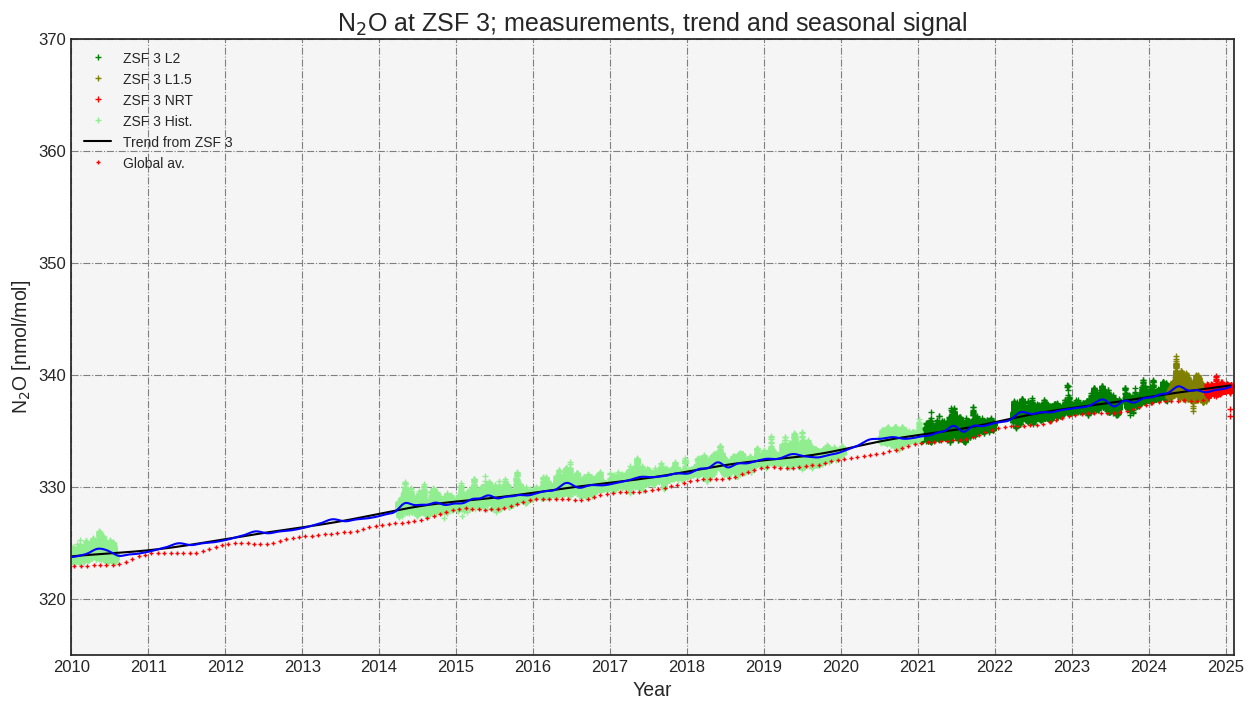

     fname     lname                orcid  \
1   Cédric    Couret  0000-0002-1874-9883   
0  Martina   Schmidt  0000-0002-4648-769X   
2  Michael  Elsasser                        

                                                 uri  weight  \
1  http://meta.icos-cp.eu/resources/people/C%C3%A...    70.0   
0  http://meta.icos-cp.eu/resources/people/Martin...    20.0   
2  http://meta.icos-cp.eu/resources/people/Michae...     0.0   

                  start   end  wght  
1  2021-01-15T00:00:00Z  None    30  
0  2021-01-01T00:00:00Z  None    80  
2  2022-10-05T00:00:00Z  None   100  
Done writing  ./data/n2o/nc/n2o_zsf_surface-insitu_25_allvalid.nc
Done saving  ./data/n2o/txt/n2o_zsf_surface-insitu_25_allvalid.txt
Done saving  ./data/n2o/nc/n2o_zsf_surface-insitu_25_allvalid.json
ZUG


In [45]:
# And now the real work starts!
runall(info,gas=gas,process=True,doTxt=True) 

# The End of producing the files

In [46]:
produced

,fname,folder,station,hgh,hash,Handle
0,n2o_cbw_tower-insitu_445_allvalid-67magl,./data/n2o/nc/,CBW,67.0,,
1,n2o_cbw_tower-insitu_445_allvalid-27magl,./data/n2o/nc/,CBW,27.0,,
2,n2o_cbw_tower-insitu_445_allvalid-207magl,./data/n2o/nc/,CBW,207.0,,
3,n2o_cbw_tower-insitu_445_allvalid-127magl,./data/n2o/nc/,CBW,127.0,,
4,n2o_cmn_surface-insitu_443_allvalid,./data/n2o/nc/,CMN,8.0,,
...,...,...,...,...,...,...
57,n2o_trn_tower-insitu_11_allvalid-5magl,./data/n2o/nc/,TRN,5.0,,
58,n2o_trn_tower-insitu_11_allvalid-180magl,./data/n2o/nc/,TRN,180.0,,
59,n2o_trn_tower-insitu_11_allvalid-100magl,./data/n2o/nc/,TRN,100.0,,
60,n2o_wao_surface-insitu_13_allvalid,./data/n2o/nc/,WAO,10.0,,


In [35]:
# Optionally we can submit all individual netcdf files to carbon portal
import getpass

password = getpass.getpass(prompt='Password: ')
param = f'mail=alex.vermeulen@nateko.lu.se&password={password}'

cpauthUrl='https://cpauth.icos-cp.eu/password/login'
payload={'mail': "alex.vermeulen@nateko.lu.se",'password': password}
loginresp = requests.post(cpauthUrl, data=payload)
print(loginresp.cookies)

!curl --cookie-jar cookies.txt --data "$param" https://cpauth.icos-cp.eu/password/login 

Password:  ········


<RequestsCookieJar[<Cookie cpauthToken=WzE3Mzc3NTIzMzE4OTksImFsZXgudmVybWV1bGVuQG5hdGVrby5sdS5zZSIsIlBhc3N3b3JkIl0eMGUCMAn+1b1J+m9M9FszeZpaL2ylSY9VFhR0E7RyrzMa3drQgql2Mmd0lqQaUTBxQdAqjgIxAIdh5t0ZbrBxq9fKKkXhFOmejVH5KS9LbAvzBwCQIVBitpA+zWaxe38bCQJs627FdQ== for .icos-cp.eu/>]>
OK

In [47]:
for i,row in produced.iterrows():
    res=step1(loginresp.cookies,row['folder']+row['fname']+'.json')
    if res.status_code==200:
        hash=res.text
        if "https://data.icos-cp.eu/objects/" in hash:
            print(row.fname,': succes step1, URI: ', hash)
            uri=hash
            hash=hash.replace("https://data.icos-cp.eu/objects/","")
            produced.loc[i,'hash']=hash
            
            res2=step2(row['folder']+row['fname']+'.nc',uri)
            print(res2)        
        else:
            print(row.fname,' step 1 status 200 but hash returned is wrong:',hash)
    else:
        print(row.fname,': step 1 error: ',res.status_code)
        print('       ',res.text)
    
# finally save produced file to store data for later deprecation of older versions
produced.to_csv(gas+'_FT2025.1_list.csv')

n2o_cbw_tower-insitu_445_allvalid-67magl : succes step1, URI:  https://data.icos-cp.eu/objects/aDcmq3GXMS1kIKbcHoayuiiU


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 1453k  100    30  100 1453k     11   554k  0:00:02  0:00:02 --:--:--  554k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0

11676/aDcmq3GXMS1kIKbcHoayuiiU
n2o_cbw_tower-insitu_445_allvalid-27magl : succes step1, URI:  https://data.icos-cp.eu/objects/mH04tVRQYcLzcsCZ6PbP4Eiu


100 1464k  100    30  100 1464k     20   996k  0:00:01  0:00:01 --:--:--  997k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0

11676/mH04tVRQYcLzcsCZ6PbP4Eiu
n2o_cbw_tower-insitu_445_allvalid-207magl : succes step1, URI:  https://data.icos-cp.eu/objects/tYb46d8Oar89YPd9EEGgdxCI


100 1454k  100    30  100 1454k     23  1123k  0:00:01  0:00:01 --:--:-- 1122k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0

... (116 outputs left out)

11676/n6bPhPA4su2o-AcMXbWH5Qor
n2o_zsf_surface-insitu_25_allvalid : succes step1, URI:  https://data.icos-cp.eu/objects/bLMmna5GMYn4EjdF8rKA0D3s


100 2129k    0     0  100 2129k      0   965k  0:00:02  0:00:02 --:--:--  965k

11676/bLMmna5GMYn4EjdF8rKA0D3s


100 2129k  100    30  100 2129k     10   757k  0:00:03  0:00:02  0:00:01  757k


In [ ]:
The End!

In [ ]:
# This can be skipped
specs=['atcCo2Product','atcCo2L2DataObject','atcGHGFastTrackNRTDataObject','atcCo2NrtGrowingDataObject']
info = pd.DataFrame()
flist=getfilelist(specs)
for i,file in flist.iterrows():
    update_progress((i+1)/len(flist),'Getting file metadata')
    data = newfileinfo(file['dobj'])
    useFile = False
    for i in data['specificInfo']['columns']:
        if gas in i['label']: 
            useFile = True
    if useFile:
        info=info.append({'uri':file['dobj'],
                 'fileName':data['fileName'],
                 'stationId':data['specificInfo']['acquisition']['station']['id'],
                 'hgh':data['specificInfo']['acquisition']['samplingHeight'],
                 'level':data['specification']['dataLevel'],
                 'specification':data['specification'][ 'self']['uri']
                },ignore_index=True)
info

In [ ]:
# testing the download of the 3 datafiles for station HTM 150m
#df=Get_ICOS_ATM_product(Dobj('https://data.icos-cp.eu/objects/c4n8iAVYPvsw5bUcHNPB1h-J'),0,False)
#df=Get_ICOS_ATM_product(Dobj('https://data.icos-cp.eu/objects/MmLWYVI8zTZQqvGiN1q6Ka3G'),1,False)
#df=Get_ICOS_ATM_product(Dobj('https://data.icos-cp.eu/objects/MEzylUF7JJ4NC24fBKA1eFDZ'),2,False)

df=Get_ICOS_ATM_product(Dobj('https://data.icos-cp.eu/objects/cShY_3eOEPNcm7XQ_JPa9gEQ'),0,False)
df

In [ ]:
citations=['Lehner, I., Mölder, M., ICOS RI, 2022. ICOS ATC NRT CO2 growing time series, Norunda (58.0 m), 2022-03-01–2022-08-11, https://hdl.handle.net/11676/OWn3UmYhLZ3DTh1-9s-tWKxO', 
           'Lehner, I., Mölder, M., ICOS RI, 2022. ICOS ATC CO2 Release, Norunda (58.0 m), 2017-04-01–2022-02-28, https://hdl.handle.net/11676/8PcD9MOxmwAOrWnpndzI54dr']
for i in [0,len(citations)-1]:
    print(citations[i])

In [ ]:
stat=station.getIdList(project='all', sort='name')
for i,st in stat.iterrows():
    if st.theme in ['AS','ATMO']:
        print(st[1], st[2], st.country, st.lat, st.lon, st.project, st.uri)

In [ ]:
init()
addRoles('AS_ZEP')
addRoles('AS_HTM')
contribs=contribs.sort_values('weight')
for i,role in contribs.iterrows():
    print(role.fname,role.lname,role.weight)
contribs

In [ ]:
contribs.loc[contribs['weight'] == '100', 'weight'] = '99'
contribs.loc[contribs['roleName'] == 'Engineer', 'weight'] = '00'
contribs = contribs.sort_values('weight', ascending=False).drop_duplicates(subset=['fname', 'lname'])
for i,role in contribs.iterrows():
    print(role.fname,role.lname,role.weight)

In [ ]:
stations=station.getIdList(project='all')
print('Nr stations: ',len(stations))
n=0
for i,stat in stations.iterrows():
    if stat.theme in ['AS','ATMO']:
        n=n+1
        print(stat[2],stat.theme)
print('Nr ATM stations: ',n)

In [ ]:
list=getfilelist()
info=pd.DataFrame()
for i,dobj in list.iterrows():
    inf=getfileinfo(dobj.dobj)
    info=info.append(inf) 

In [ ]:
list=getfilelist()
print(list)

In [ ]:
test=Dobj('c4n8iAVYPvsw5bUcHNPB1h-J')
print(test.colNames)
test.data.plot(x='TIMESTAMP', y='co2', grid=True)

In [ ]:
meta=Dobj('HdgDiYSy-uxV6y61pPCY4t3M').meta
authors=meta['references']['authors']
for author in authors:
    print(author['firstName'],author['lastName'])
try:
    print(meta['specificInfo']['acquisition']['station']['responsibleOrganization']['name'])
    print(meta['specificInfo']['acquisition']['station']['responsibleOrganization']['self']['label'])
except:
    print('No organisation info')
print('https://hdl.handle.net/'+meta['pid'])
try:
    print('https://doi.org/'+meta['doi'])
except:
    print('no DOI')
print(meta['references']['citationString'])
meta

In [ ]:
#data=info[info['stationId']=='JFJ']
meta=Dobj('AL0PWC5CNeG2fWXWyTriLG6_').meta
meta

In [ ]:
meta['specificInfo']['columns'][1]['label']=='co2'

In [ ]:
usefile=False
for i in meta['specificInfo']['columns']:
    if i['label']=='co2': usefile=True

In [ ]:
# test JSON datacite formatters
print('"creators": [',
      instituteDataciteJson('ICOS RI')+
      ','+personDataciteJson('Alex','Vermeulen','0000-0000-0000-0000','ICOS Carbon Portal','DataCollector')+
      ','+instituteDataciteJson('Carbon Portal','DataCurator' )+
      ','+instituteDataciteJson('ICOS ATC')+
      ','+instituteDataciteJson('ICOS FCL')+
      ','+instituteDataciteJson('ICOS CAL')+
      ' ]\n')

In [ ]:
info

In [ ]:
with open('authors_n2o.json', 'w') as f:
    print(citation(collectionContribs,False),file=f)
with open('contributors_n2o.json', 'w') as g:
    print(citation(collectionContribs,True),file=g)

In [ ]:
attr1 = {'test': 1,'test2':2}
attr2 = {'test3': 3,'test4':4}
attr3 = {'test5': 5,'test6':6}
attr1.update(attr2)
attr1.update(attr3)
print(attr1)

In [ ]:
defcitations = [doiCitation('10.18160/KCYX-HA35'),doiCitation('10.18160/ERE9-9D85'),doiCitation('10.18160/ATM_NRT_CO2_CH4')]
citations=defcitations
attr={}
for i in range(0,len(citations)):
    print(i+1)
    attr.update({'dataset_provider_citation_'+str(i+1) : citations[i]})
print(attr)

In [ ]:
from icoscp.station import station
stationlist=station.getIdList(project='all')
for i, stat in stationlist.iterrows():
    if (stat.theme in ['AS','ATMO']): 
        print(stat.name,stat.id,stat.uri,stat[2])

In [ ]:
global colnames

init()
df = pd.read_csv('./ICOS_ATC_L2_L2-2019.1_TRN_180.0_CTS.CO2',comment='#',header=None,names=colnames[2],delimiter=';',usecols=range(0,nrcols[2]-1))           
df.rename({'DecimalDate':'JulDate'}, axis='columns', inplace=True)
df['Datetime'] = [t2dt(i) for i in df['JulDate']]    
df = df.set_index('Datetime')
df.drop(['Year','Month','Day','Hour','Minute'], axis=1, inplace = True)

def tocomp(dat,minutesdiff=-30):
    dat=dat+dt.timedelta(seconds=1)+dt.timedelta(minutes=minutesdiff)
    return [dat.year,dat.month,dat.day,dat.hour,dat.minute,0]

timcomp = [tocomp(i) for i in df.index]


In [ ]:
init()
s=ICOSstations[ICOSstations.Hist=='BRM']
print(s)
print(s.NOAALabNr.values[0],s.Long_name.values[0],s.NOAA_Lab_name.values[0],s.URL.values[0])


In [ ]:
debug=True

In [ ]:
def createAuthorJson(contribInfo: None) -> str:
    namelist='{authors : ['
    first=True
    for i,p in contribInfo.iterrows():
        if first==True:
            namelist=namelist+p.uri
        first=False
        namelist=namelist+',\n\t'+p.uri
    namelist=namelist+']\n},\n'
    first=True
    namelist=namelist+'{contributors : ['
    for i,p in contribInfo.iterrows():
        if first==True:
            namelist=namelist+p.uri
        first=False
        namelist=namelist+',\n\t'+p.uri
    namelist=namelist+']\n}\n'
    return namelist
    
list=createAuthorJson(collectionContribs)
print(list)

In [ ]:
namelist=''
first=True
for i,p in collectionContribs.iterrows():
    if first!=True:
        namelist=namelist+' AND '
    first=False
    namelist=namelist+p.fname+' '+p.lname
print(namelist)

In [ ]:
cnt=0
st=station.get('KAS')
stationlist=station.getIdList(project='all')
previd='' 
for i, stat in stationlist.iterrows():
    if (stat.theme in ['AS','ATMO']): 
        # only atmospheric stations
        st=station.get(stat.id)
        stid=st.stationId
        if stid!=previd:
            previd=stid
            stclass=st.icosclass
            if stclass in ["1","2"]:
                print(stid, stclass)
                cnt=cnt+1
print(cnt)


In [ ]:
df,info=getStationRolesFromFilePid('HFD')
df

In [ ]:
meta=getStationRolesFromFilePid('https://meta.icos-cp.eu/objects/5KbHGA_sl5lqbbg6xhOT4BDr',False)

In [ ]:
meta

In [ ]:
print(ICOSstations)

In [ ]:
tim=dt.datetime.utcnow()
tim

In [ ]:
import xarray as xr

data = xr.open_dataset('./data/co2/nc/co2_ssl_tower-insitu_23_allvalid-12magl.nc')
data.time_components[1]

In [ ]:
    obspack_id = ds.createVariable('obspack_id', 'c', ('time', 'string_of_200chars', ), zlib=True)!pip install jupyter_contrib_nbextensions && jupyter contrib nbextension install

In [ ]:
import netCDF4 as nc
    
ds =  nc.Dataset('test2.nc', 'w', format='NETCDF4')
time = ds.createDimension('time',None)
s200 =  ds.createDimension('string_of_200chars', 200);
b = ds.createVariable('obspack_id', 'c', ('time', 'string_of_200chars', ), zlib=True)

b = ["a_" + str(i) for i in range(10)]
b

In [ ]:
ds.sync()
ds.close() 

In [ ]:
def createtxtheader(headertemplate,obspackname,ncfile,doi,citation=''):
    
    import os
    
    head=[]
    with open('header.txt') as f:
        pre = f.readlines()
    stream = os.popen('ncdump -h '+ncfile)
    output = stream.readlines()
    filtered=[]
    variables=[]
    variables.append('#')
    variables.append('# ------------------------------------------------------------->>>>')
    variables.append('# VARIABLE ATTRIBUTES')
    variables.append('#')
    for i in output:
        if '\t\t' in i:
            i=i.replace(' ;\n','')
            i=i.replace('"','') 
            if '\t\t:' in i: 
                i=i.replace('\t\t:','# ') 
                filtered.append(i)
            else:
                i=i.replace('\t\t','# ') 
                variables.append(i)
    variables.append('#')
    variables.append('# VARIABLE ORDER')
    variables.append('#')
    hlen=len(filtered)+len(variables)+len(pre)+1

    fname=os.path.basename(ncfile)
    (dataset, sep, ext) = fname.rpartition('.')
    head.append('# header_lines : '+str(hlen))
    if citation=='':
        citation=doiCitation('10.18160/CEC4-CAGK')
    for i in pre:
        i=i.replace('\n','') 
        if 'doi_xxx' in i:
            i=i.replace('doi_xxx',doi)
        if 'citation_xxx' in i:
            i=i.replace('citation_xxx',citation)
        if 'obspack_xxx' in i:
            i=i.replace('obspack_xxx',obspackname)
        if 'dataset_xxx' in i:
            i=i.replace('dataset_xxx',dataset)     
        head.append(i)
    for i in filtered:
        head.append(i)
    for i in variables:
        head.append(i)
    return head

header = createtxtheader('header.txt','obspack_co2_466_GLOBALVIEWplus_v9.0_2023-08-06',
                         './data/co2/nc/co2_cbw_tower-insitu_445_allvalid-207magl.nc',
                        '10.18160/PEKQ-M4T1')

In [ ]:
for i in header:
    print(i)

In [ ]:
doiCitation('10.18160/'+doi)

In [ ]:
 def year_frac(dat,offsetSec=0):
            dat = dat + dt.timedelta(seconds=offsetSec)
            start =  dt.datetime(dat.year, 1, 1, 0, 0, 0)
            endyr = dt.datetime(dat.year+1, 1, 1, 0, 0, 0)
            yearlen = dt.datetime.timestamp(endyr) - dt.datetime.timestamp(start)
            year_frac = (dt.datetime.timestamp(dat) - dt.datetime.timestamp(start)) / yearlen
            return dat.year + year_frac
year_frac(dt.datetime.now(),0)

In [ ]:
ts=dt.datetime.utcfromtimestamp(1354176000)
ts.year

In [ ]:
ICOSstations

In [ ]:
collectionContribs

In [ ]:
fileContribs

In [ ]:
specs=['atcCo2Product','atcCo2L2DataObject','atcGHGFastTrackNRTDataObject','atcCo2NrtGrowingDataObject']
flist=getfilelist(specs)
info=pd.DataFrame()
for i,dobj in flist.iterrows():
    inf=getfileinfo(dobj.dobj)
    info=info.append(inf)    


In [ ]:
maxh=0
stid='JFJ'

for i, do in info.iterrows():
    if do.hgh!=None: 
        maxh=max(float(do.hgh),maxh)
        if (stid=='HUN') and (abs(float(do.hgh)-48.0)<1):
            hghts.append(50)
        else:        
            hghts.append(float(do.hgh))
    else:
        maxh=0
        hghts.append(0.0)
# deduplicate the list of available sampling heights
hgh = [ii for n,ii in enumerate(hghts) if ii not in hghts[:n]]
hgh

In [ ]:
jsonPackage = {
    "submitterId": "CP",
    "objectSpecification": "test",
    "isNextVersionOf": [  ],
}

In [ ]:
stClass=3
stClass in [1,2]

In [ ]:
from icoscp_core.icos import meta,ATMO_STATION
stations = meta.list_stations(ATMO_STATION)
for i in stations:
    stationmeta = meta.get_station_meta(i.uri)
    stclass=stationmeta.specificInfo.stationClass
    print(i.id,stclass,stclass=='1')
print(stationmeta)

In [ ]:
from icoscp_core.icos import meta,ATMO_STATION
stationmeta = meta.get_station_meta('https://meta.icos-cp.eu/resources/stations/AS_ZSF')
stationmeta.org.self.uri